# Notebook 14: Microstructure Signals Against the Truth

**References:** Cont, R., Kukanov, A. and Stoikov, S. (2014). The price impact of order book events. *Journal of Financial Econometrics* 12(1), 47-88. Lee, C. M. C. and Ready, M. J. (1991). Inferring trade direction from intraday data. *Journal of Finance* 46(2), 733-746. Easley, D., Lopez de Prado, M. M. and O'Hara, M. (2012). Flow toxicity and liquidity in a high-frequency world. *Review of Financial Studies* 25(5), 1457-1493. Andersen, T. G. and Bondarenko, O. (2014). VPIN and the flash crash. *Journal of Financial Markets* 17, 1-46. Large, J. (2007). Measuring the resiliency of an electronic limit order book. *Journal of Financial Markets* 10(1), 1-25. Gould, M. D. and Bonart, J. (2016). Queue imbalance as a one-tick-ahead price predictor in a limit order book. *Market Microstructure and Liquidity* 2(2), 1650006. Cont, R. and de Larrard, A. (2013). Price dynamics in a Markovian limit order market. *SIAM Journal on Financial Mathematics* 4(1), 1-25. Avellaneda, M., Reed, J. and Stoikov, S. (2011). Forecasting prices from level-I quotes in the presence of hidden liquidity. *Algorithmic Finance* 1(1), 35-45. Glosten, L. R. and Milgrom, P. R. (1985). Bid, ask and transaction prices in a specialist market with heterogeneously informed traders. *Journal of Financial Economics* 14(1), 71-100. VisualHFT's research notes R-001 and R-002 (visualhft.com/research) and its code (github.com/visualHFT/VisualHFT, Apache License 2.0).

**What VisualHFT is.** VisualHFT is an open-source (Apache 2.0) Windows desktop application for live crypto feeds: study plugins compute on every book update and show their values as tiles, and a trigger engine acts on those values. Its studies are the book imbalance, VPIN, market resilience and order-to-trade ratios and, on its website, order flow imbalance, cumulative volume delta, a footprint chart and a tape. Its research is the vendor's own: R-001 scores the sign of the first new nonzero imbalance after a change of the mid against the direction of the next change (55.1% against 50% on Nasdaq ITCH), and R-002 and its other notes report that pairing an imbalance with a bucket's open time inflated a result, that VPIN did not improve a volatility forecast, that market resilience did not predict the spread or markouts, and that order-to-trade ratios did not support an order-pulling trigger.

**What the notebook does with it.** Sections 1 to 6 run six of those studies in the simulator (the imbalance, OFI, the rules that sign trades, VPIN, resilience and order-to-trade ratios) and ask of each what VisualHFT's research asks of it, scored against the truth and against a baseline that the section names. Section 7 then trades two of the signals: a taker on the imbalance (7a) and a quote joiner that pulls its quotes on VPIN (7b). Where VisualHFT's code differs from its website the section says how: the code (commit b36b9a2, 6 November 2026) has five tiles, the imbalance, VPIN, market resilience, its bias and order-to-trade, and has no OFI, volume delta, footprint, tape or trade-to-order ratio.

**What a simulator adds.** A feed gives a study its prints and quotes. The simulator adds what a feed does not: the true aggressor of every fill, so that a rule that infers a side is scored against the side and not against another rule; in the informed model, a hidden value V that informed traders trade on, so that toxicity has a ground truth (which orders were informed, and what a maker lost against V on each fill); and exact events, every arrival, cancel and fill in order with the quotes before and after, so that nothing is paired by a bucket's time and a count is a count.

**The models** are the dashboard's, at its parameters, which the setup cell writes out and checks against the dashboard's own so that the notebook cannot drift from them: ZI (Smith et al.'s zero intelligence: market orders at `mu` 6, limit orders at `lam` 1 a tick, cancels at `delta` 0.03, lots of 5), Hawkes ZI (ZI with Hawkes arrivals), MF 2008 (Mike and Farmer's), Parlour and Informed ZI. Informed ZI is ZI with a hidden value V that starts at the mid and moves as a random walk (0.3 ticks per square root of a unit of time, with jumps of 2 ticks at a rate of 0.05 a unit), and informed traders who send market orders at a rate of 2 a tick of the gap between V and the quote they would hit, at most 3 a unit, and only when V lies beyond that quote. At these settings 0.155 (se 0.001) of the taker lots are informed (section 4). V is floored at 20 ticks, which none of section 4's 112 runs reached. The other four models have no value behind their flow, so in them VPIN's premise is absent and it is a control.

**MF simplified, the dashboard's sixth model, is left out.** Its mid does not move (0.0 changes of the mid a run, most 0, in 4,000 units), so section 1 has nothing to score, and its depth at the three prices nearest the touch is 1515 (se 27) lots against 34 to 220 in the others, so that section 5 finds 3 depletions in all.

**The conventions.** Every setting was chosen on seeds 1 to 8, whose runs the notebook does not print, and every figure is on seeds 101 and up: the tables that vary one thing use seeds 101 to 108 (`FEW`, 8 seeds) and the backtests of section 7 seeds 101 to 112 (`SEEDS`, 12), so that no seed that reports chose anything. A figure with a bracket is a mean over seeds with its standard error across them, written 7.2 (0.1) in the tables and 7.2 (se 0.1) here; a lift is in percentage points (pp) and P&L in ticks x lots. A run's length is in units of simulation time after a warm-up, and a unit holds 60.1 events in ZI, 21.5 in MF 2008 and 13.3 in Parlour: sections 1 to 6 start from an empty book and warm up for 10,000 events, and the backtests start from the dashboard's seeded book and warm up for 40,000. The initial mid is 10,000, as in notebooks 05 and 07 (the dashboard's is 100, at which the informed model's V reaches its floor in some runs of 12,000 units). VPIN's buckets are 250 lots (50 median fills) and a trailing window is 50 buckets.

**What is true by construction** is labeled so where it comes up: the quote rule at lag 0, BVC's VPIN near 0.5, the loss of an informed fill against V, VPIN's inability to lead a jump of V, and the loss of a taker with no information, which pays the spread.

**The backtests** of section 7 run through the dashboard's own manager with its board of studies (the imbalance and VPIN that a trigger sees), each strategy alone in its market, and every backtest has a scorecard and a signal chart.

In [1]:
import math
import sys
import textwrap
import warnings

sys.path.insert(0, '..')
from array import array
from collections import deque

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from joblib import Parallel, delayed
from quant_plots import Backtest, scorecard, signal_chart
from scipy.optimize import minimize

from app.manager import LOBManager
from app.model_specs import MODEL_SPECS
from app.strategy_specs import StrategySpec
from app.studies import StudyBoard
from lob.analysis.plotting import set_style
from lob.book import OrderBook
from lob.models.informed import InformedZIModel
from lob.order import Side, reset_order_id_counter
from lob.simulation import Simulation, SimulationConfig
from lob.strategies import Plan, QuoteJoiner, Strategy
from lob.studies import (
    ARRIVAL_LIMIT,
    CANCEL,
    VPIN,
    BookImbalance,
    OrderToTrade,
    Resilience,
    TradeDelta,
    ofi_increment,
)

set_style()
# joblib restarts a worker whose memory has grown by 300 MB and warns when it does; no work is lost.
warnings.filterwarnings('ignore', message='A worker stopped while some jobs were given to the executor')
BLUE, ORANGE, AQUA, GRAY = '#2a78d6', '#eb6834', '#1baf7a', '#52514e'

SEEDS = range(101, 113)  # none of the settings below was chosen on these: they were chosen on seeds 1 to 8
FEW = range(101, 109)  # for the tables that vary one thing
N_JOBS = -1  # every core
MID = 10_000  # the initial mid-price of every model here, as in notebooks 05 and 07 (the dashboard's is 100)
WARMUP = 10_000  # events of a run before anything is recorded

# The dashboard's parameters (app/model_specs.py), written out so that the notebook says what it ran, and checked
# against the dashboard's so that it cannot drift from them without failing here. Notebook 05's differ (its rates
# are lower, its lots are 1); the studies' defaults, a bucket of 250 lots and a touch of 3 prices, were set for these.
PARAMS = {
    'smith_zi': dict(mu=6.0, lam=1.0, delta=0.03, price_range=15, lot_size=5),
    'hawkes_zi': dict(mu=6.0, lam=1.0, delta=0.03, price_range=15, lot_size=5, branching=0.8, decay=1.0),
    'mike_farmer': dict(mu=2.5, lam=8.0, delta=0.015, alpha_price=1.5, hurst=0.7, size_mean=2.2, size_sigma=0.5),
    'mike_farmer_2008': dict(
        lam=10.0, cancel_rate=0.05, imbalance_offset=0.2, hurst=0.75, nu=1.3, loc=1.0, scale=3.0, lot_size=5
    ),
    'parlour': dict(arrival_rate=12.0, delta=0.015, spread_threshold=5, depth_threshold=10, price_range=20, lot_size=5),
    'informed_zi': dict(
        mu=6.0,
        lam=1.0,
        delta=0.03,
        price_range=15,
        lot_size=5,
        sigma_v=0.3,
        jump_rate=0.05,
        jump_size=2.0,
        kappa=2.0,
        cap=3.0,
        persistence=0.5,
    ),
}
for key, values in PARAMS.items():
    assert values == MODEL_SPECS[key].defaults(), f'{key}: the dashboard has changed its defaults'
MODELS = ['smith_zi', 'hawkes_zi', 'mike_farmer_2008', 'parlour', 'informed_zi']
NAMES = {
    'smith_zi': 'ZI',
    'hawkes_zi': 'Hawkes ZI',
    'mike_farmer_2008': 'MF 2008',
    'parlour': 'Parlour',
    'informed_zi': 'Informed ZI',
    'mike_farmer': 'MF simplified',
}
# Events in a unit of simulation time, measured on seeds 1 to 8: a run's length is given in units of time and
# converted to events with these (to within a percent or two: what each section reports is the time it covered).
EVENTS_PER_UNIT = {
    'smith_zi': 60.1,
    'hawkes_zi': 60.3,
    'mike_farmer_2008': 21.5,
    'parlour': 13.3,
    'informed_zi': 60.0,
    'mike_farmer': 16.0,
}


def make_model(key, **changes):
    return MODEL_SPECS[key].build({**PARAMS[key], **changes}, MID)


class Tap:
    # A model seen through its events. Simulation calls its observer after each event, but the studies' once-a-unit
    # samples (the touch scale of the imbalance, the lagged mid of the quote rule) must come from the book before the
    # event that opens the unit, as the dashboard's session takes them. So on_pre is called from generate_event, once
    # the model has said when its event happens, with the book as it stands. `warm` is True through the warm-up, whose
    # events the studies see (they need the history) and the recorders do not.
    def __init__(self, model, on_pre=None, listeners=()):
        self.model = model
        self.on_pre = on_pre
        self.listeners = list(listeners)
        self.calls = 0
        self.warm = True

    def generate_event(self, book, t, rng):
        order = self.model.generate_event(book, t, rng)
        self.warm = self.calls < WARMUP  # the call's index is Simulation's loop index
        self.calls += 1
        if order is not None and self.on_pre is not None:
            self.on_pre(self.warm, order.timestamp, book)
        return order

    def observe(self, *event):
        for listener in self.listeners:
            listener(self.warm, *event)

    def __getattr__(self, name):
        return getattr(self.model, name)


def simulate(model, key, seed, units, listeners=(), on_pre=None):
    # An empty book, as notebooks 07 and 13 start; `units` of simulation time after the warm-up.
    reset_order_id_counter()
    tap = Tap(model, on_pre, listeners)
    sim = Simulation(
        model=tap,
        book=OrderBook(tick_size=1, lot_size=1),
        config=SimulationConfig(n_events=int(units * EVENTS_PER_UNIT[key]), warmup_events=WARMUP, seed=seed),
        observer=tap.observe,
    )
    sim.run(progress=False)
    return sim


def mid_of(quotes):
    # quotes: (best bid, lots there, best ask, lots there), a price None for an empty side
    return None if quotes[0] is None or quotes[2] is None else (quotes[0] + quotes[2]) / 2.0


def note(*parts):
    # Print a note: the parts as one paragraph, wrapped at 120 columns (a leading newline puts a blank line before it).
    text = ' '.join(parts)
    if text.startswith('\n'):
        print()
    print(textwrap.fill(' '.join(text.split()), width=120))


def mean_se(values):
    v = np.asarray(values, dtype=float)
    v = v[np.isfinite(v)]
    if len(v) == 0:
        return np.nan, np.nan
    return v.mean(), (v.std(ddof=1) / math.sqrt(len(v)) if len(v) > 1 else np.nan)


def said(values, digits=3, scale=1.0):
    # 'mean (se)': the mean over seeds and its standard error across them
    mean, se = mean_se(np.asarray(values, dtype=float) * scale)
    return '-' if np.isnan(mean) else f'{mean:.{digits}f} ({se:.{digits}f})'


def correlation(x, y):
    ok = np.isfinite(x) & np.isfinite(y)
    return np.corrcoef(x[ok], y[ok])[0, 1] if ok.sum() > 2 and x[ok].std() > 0 and y[ok].std() > 0 else np.nan


def partial_correlation(x, y, z):
    # of x and y, given z
    rxy, rxz, ryz = correlation(x, y), correlation(x, z), correlation(y, z)
    return (rxy - rxz * ryz) / math.sqrt((1 - rxz**2) * (1 - ryz**2))


N_BUCKETS = 50  # of a VPIN, the studies' default


def trailing(values, n=N_BUCKETS):
    # the mean of the last n values, NaN until there are n
    total = np.cumsum(np.insert(values, 0, 0.0))
    out = np.full(len(values), np.nan)
    out[n - 1 :] = (total[n:] - total[:-n]) / n
    return out


def forward_fill(x):
    ok = np.isfinite(x)
    index = np.where(ok, np.arange(len(x)), 0)
    np.maximum.accumulate(index, out=index)
    return x[index]


def weighted(x, weights, keep):
    # the mean of x weighted by `weights` over the entries `keep` selects
    return float((x[keep] * weights[keep]).sum() / weights[keep].sum()) if weights[keep].sum() > 0 else math.nan

## 1. What the Book Says About the Next Move

In [2]:
IMBALANCE_UNITS = 4_000  # units of simulation time a run, after the warm-up
CONFIGS = [(levels, weighting) for levels in (1, 3, 5, 10) for weighting in ('equal', 'touch')]
T_MAX = 30.0  # units: a next change later than this after the last is dropped (R-001 drops those after 30 s)
COLUMNS = ('changes', 'late', 'no_reading', 'n', 'hits', 'reversals', 'n_one', 'hits_one', 'reversals_one')
COL = {name: i for i, name in enumerate(COLUMNS)}


class Reading:
    # R-001's event design for one setting of the imbalance. After each change of the mid, the first event whose
    # imbalance (the state after the event) is not zero gives the reading, and its sign is scored against the direction
    # of the next change. By default only an event that leaves the mid alone can give it ("the first new nonzero
    # imbalance after a mid change"); with `inclusive` the change event's own post-state can too.
    def __init__(self, inclusive):
        self.inclusive = inclusive
        self.counts = dict.fromkeys(COLUMNS, 0)
        self.rows = []  # (|I|, hit, spread in ticks) of each scored change, for the queue-race fits
        self.armed = False  # a change has been seen and no reading taken since
        self.reading = None
        self.t_change = 0.0
        self.last_move = 0

    def break_(self):
        self.armed, self.reading = False, None  # a side of the book is empty: no mid

    def wants(self, changed):
        return self.armed and self.reading is None and (self.inclusive or not changed)

    def read(self, value, spread):
        self.reading = (value, spread, self.t_change, self.last_move)
        self.armed = False

    def change(self, t, move):
        counts = self.counts
        counts['changes'] += 1
        if self.reading is not None:
            value, spread, t_change, previous = self.reading
            if t - t_change > T_MAX:
                counts['late'] += 1
            else:
                hit, reversal = (value > 0) == (move > 0), move == -previous
                counts['n'] += 1
                counts['hits'] += hit
                counts['reversals'] += reversal
                if spread == 1:
                    counts['n_one'] += 1
                    counts['hits_one'] += hit
                    counts['reversals_one'] += reversal
                self.rows.append((abs(value), hit, spread))
        elif self.armed:
            counts['no_reading'] += 1
        self.armed, self.reading, self.t_change, self.last_move = True, None, t, move


class ImbalanceCollector:
    # Eight settings of the imbalance study (levels 1, 3, 5, 10, equal and touch weights) and, for each, a Reading of
    # the strict design and one of the inclusive; and the once-a-unit samples, for the look-ahead pairing.
    def __init__(self):
        self.studies = [BookImbalance(levels=levels, weighting=weighting) for levels, weighting in CONFIGS]
        self.readings = [Reading(inclusive) for inclusive in (False, True) for _ in CONFIGS]
        self.unit = 0
        self.last_mid = None
        self.unit_imbalance, self.unit_mid = [], []

    def on_pre(self, warm, t, book):
        while self.unit < int(t):
            self.unit += 1
            values = [study.sample(self.unit, book) for study in self.studies]
            if not warm:
                self.unit_imbalance.append([np.nan if v is None else v for v in values])
                self.unit_mid.append(np.nan if book.mid_price is None else book.mid_price)

    def observe(self, warm, t, kind, side, price, size, fills, aggressor, before, after, book, own=False):
        mid = mid_of(after)
        if mid is None:
            self.last_mid = None
            for reading in self.readings:
                reading.break_()
            return
        previous, self.last_mid = self.last_mid, mid
        if warm:
            return
        changed = previous is not None and mid != previous
        if changed:
            for reading in self.readings:
                reading.change(t, 1 if mid > previous else -1)
        spread = after[2] - after[0]
        for study, strict, inclusive in zip(self.studies, self.readings[:8], self.readings[8:], strict=True):
            if strict.wants(changed) or inclusive.wants(changed):
                value = study.compute(book)
                if value:
                    for reading in (strict, inclusive):
                        if reading.wants(changed):
                            reading.read(value, spread)


def pairing(unit_imbalance, unit_mid):
    # The sample taken at the start of unit u is the state at the end of unit u - 1. Paired with the change of the mid
    # over unit u - 1, which it has just seen (as a join on a bucket's open time does), or with the change over unit u,
    # which follows it (the causal pairing). Units with no change, and zero readings, are left out.
    move = np.diff(unit_mid)  # move[k]: the change over the unit that ends at sample k + 1
    out = np.zeros((len(CONFIGS), 4))
    for c in range(len(CONFIGS)):
        value = unit_imbalance[:, c]
        for j, (read, then) in enumerate(((value[1:], move), (value[1:-1], move[1:]))):
            ok = np.isfinite(read) & (read != 0) & np.isfinite(then) & (then != 0)
            out[c, 2 * j], out[c, 2 * j + 1] = ok.sum(), (np.sign(read[ok]) == np.sign(then[ok])).sum()
    return out


def imbalance_run(key, seed):
    collector = ImbalanceCollector()
    simulate(make_model(key), key, seed, IMBALANCE_UNITS, [collector.observe], collector.on_pre)
    counts = np.array([[reading.counts[name] for name in COLUMNS] for reading in collector.readings])
    rows = np.array(collector.readings[0].rows, dtype=np.float32).reshape(-1, 3)  # L 1, equal weights, strict
    trap = pairing(np.array(collector.unit_imbalance), np.array(collector.unit_mid))
    return key, seed, counts, rows, trap


IMBALANCE_MODELS = [*MODELS, 'mike_farmer']  # the simplified model's mid is pinned: it is here to count its changes
imbalance_runs = Parallel(n_jobs=N_JOBS)(delayed(imbalance_run)(key, seed) for key in IMBALANCE_MODELS for seed in FEW)
counts = {key: np.array([r[2] for r in imbalance_runs if r[0] == key]) for key in IMBALANCE_MODELS}  # seeds x 16 x 9
rows = {key: [r[3] for r in imbalance_runs if r[0] == key] for key in IMBALANCE_MODELS}  # per seed: |I|, hit, spread
trap = {key: np.array([r[4] for r in imbalance_runs if r[0] == key]) for key in IMBALANCE_MODELS}  # seeds x 8 x 4
note(
    f'{NAMES["mike_farmer"]}: {counts["mike_farmer"][:, 0, COL["changes"]].mean():.1f} changes of the mid a run '
    f'(most {counts["mike_farmer"][:, 0, COL["changes"]].max():.0f}) in {IMBALANCE_UNITS:,} units: nothing to score.',
)

MF simplified: 0.0 changes of the mid a run (most 0) in 4,000 units: nothing to score.


In [3]:
SETTINGS = [f'L {levels} {weighting}' for levels, weighting in CONFIGS]
L1, L10_TOUCH = 0, 7  # L 1 (queue imbalance at the touch) and touch-weighted L 10 (VisualHFT's R-001 form)


def scored(key, c, design=0, spread='all'):
    # Per seed: the changes scored, the hit rate, the reversal rate (predict minus the last change) and the lift of the
    # hit rate over the better of the reversal rate and 50%. design 0 is the strict one, 1 the inclusive.
    cells = counts[key][:, c + 8 * design, :]
    n, hits, reversals = cells[:, COL['n']], cells[:, COL['hits']], cells[:, COL['reversals']]
    if spread == 'one':
        n, hits, reversals = cells[:, COL['n_one']], cells[:, COL['hits_one']], cells[:, COL['reversals_one']]
    elif spread == 'wide':
        n = n - cells[:, COL['n_one']]
        hits, reversals = hits - cells[:, COL['hits_one']], reversals - cells[:, COL['reversals_one']]
    hit, reversal = hits / n, reversals / n
    return n, hit, reversal, hit - np.maximum(0.5, reversal)


def dropped(key, c, design=0):
    cells = counts[key][:, c + 8 * design, :]
    return cells[:, COL['no_reading']] / cells[:, COL['changes']], cells[:, COL['late']] / cells[:, COL['changes']]


main = {}
for key in MODELS:
    row = {'scored a run': f'{scored(key, L1)[0].mean():,.0f}'}
    for label, c in (('L 1', L1), ('touch L 10', L10_TOUCH)):
        n, hit, reversal, lift = scored(key, c)
        row |= {
            f'{label}: hit %': said(hit, 1, 100),
            f'{label}: reversal %': said(reversal, 1, 100),
            f'{label}: lift pp': said(lift, 1, 100),
        }
    main[NAMES[key]] = row
note(
    'The next change of the mid, against the sign of the first nonzero imbalance after the last: the hit rate, the',
    'reversal baseline, and the lift over the better of it and 50% (mean over seeds, standard error across them).',
)
display(pd.DataFrame(main).T)

grid = pd.DataFrame(
    {NAMES[key]: {SETTINGS[c]: said(scored(key, c)[3], 1, 100) for c in range(len(CONFIGS))} for key in MODELS}
).T
note(
    '\nThe lift in pp (over the better of the reversal rate and 50%) at every setting:',
)
display(grid)
against_half = pd.DataFrame(
    {NAMES[key]: {SETTINGS[c]: said(scored(key, c)[1] - 0.5, 1, 100) for c in range(len(CONFIGS))} for key in MODELS}
).T
note(
    '\nThe same hit rates against 50% alone, pp: what the plan R-001 uses as its baseline would report.',
)
display(against_half)

shares = {}
for key in MODELS:
    row = {SETTINGS[c]: said(dropped(key, c)[0], 1, 100) for c in range(len(CONFIGS))}
    row['late (T 30), L 1'] = said(dropped(key, L1)[1], 3, 100)
    for label, c in (('L 1', L1), ('touch L 10', L10_TOUCH)):
        row[f'inclusive {label}'] = said(dropped(key, c, 1)[0], 1, 100)
    shares[NAMES[key]] = row
note(
    '\nThe share of the changes of the mid dropped, %: no reading before the next change, by setting and design; and '
    'the',
    'share dropped for the next change coming more than 30 units after the last. The two right columns are the '
    'inclusive',
    'design, where the change event itself can give the reading.',
)
display(pd.DataFrame(shares).T)

for label, c in (('L 1', L1), ('touch L 10', L10_TOUCH)):
    split = {}
    for key in MODELS:
        row = {}
        for spread, name in (('one', 'one tick'), ('wide', 'wider')):
            n, hit, reversal, lift = scored(key, c, spread=spread)
            row |= {
                f'{name}: scored a run': f'{n.mean():,.0f}',
                f'{name}: hit %': said(hit, 1, 100),
                f'{name}: reversal %': said(reversal, 1, 100),
                f'{name}: lift pp': said(lift, 1, 100),
            }
        split[NAMES[key]] = row
    note(
        f'\nBy the spread at the reading, {label}:',
    )
    display(pd.DataFrame(split).T)

pairings = {}
for key in MODELS:
    row = {}
    for label, c in (('L 1', L1), ('touch L 10', L10_TOUCH)):
        cells = trap[key][:, c, :]
        row |= {
            f'{label}: end of the unit against the same unit %': said(cells[:, 1] / cells[:, 0], 1, 100),
            f'{label}: against the next unit %': said(cells[:, 3] / cells[:, 2], 1, 100),
        }
    pairings[NAMES[key]] = row
note(
    '\nThe look-ahead trap: the once-a-unit sample (the state at the end of a unit) paired with the change of the mid '
    'over',
    'that unit, and with the change over the next. Agreement of signs, % of the units with a change and a reading:',
)
display(pd.DataFrame(pairings).T)

The next change of the mid, against the sign of the first nonzero imbalance after the last: the hit rate, the reversal
baseline, and the lift over the better of it and 50% (mean over seeds, standard error across them).


,scored a run,L 1: hit %,L 1: reversal %,L 1: lift pp,touch L 10: hit %,touch L 10: reversal %,touch L 10: lift pp
ZI,"13,014",71.1 (0.1),63.9 (0.1),7.2 (0.1),64.0 (0.1),62.5 (0.1),1.4 (0.1)
Hawkes ZI,"11,716",71.8 (0.1),64.3 (0.2),7.4 (0.2),65.8 (0.2),62.8 (0.2),2.9 (0.2)
MF 2008,"4,744",66.9 (0.3),61.3 (0.2),5.6 (0.3),62.3 (0.2),60.1 (0.2),2.2 (0.2)
Parlour,"9,189",68.9 (0.2),57.8 (0.2),11.1 (0.2),59.9 (0.1),56.2 (0.1),3.7 (0.2)
Informed ZI,"16,312",71.4 (0.1),63.7 (0.1),7.7 (0.2),63.0 (0.1),62.3 (0.1),0.7 (0.2)



The lift in pp (over the better of the reversal rate and 50%) at every setting:


,L 1 equal,L 1 touch,L 3 equal,L 3 touch,L 5 equal,L 5 touch,L 10 equal,L 10 touch
ZI,7.2 (0.1),7.2 (0.1),-1.2 (0.1),1.4 (0.1),-1.7 (0.1),1.4 (0.1),-2.1 (0.1),1.4 (0.1)
Hawkes ZI,7.4 (0.2),7.4 (0.2),-0.0 (0.2),3.2 (0.2),-1.1 (0.2),2.9 (0.2),-1.8 (0.2),2.9 (0.2)
MF 2008,5.6 (0.3),5.6 (0.3),-0.8 (0.2),1.3 (0.2),-0.8 (0.3),1.7 (0.2),-7.5 (0.1),2.2 (0.2)
Parlour,11.1 (0.2),11.1 (0.2),2.1 (0.2),4.3 (0.1),0.1 (0.2),3.6 (0.1),-4.1 (0.1),3.7 (0.2)
Informed ZI,7.7 (0.2),7.7 (0.2),-2.5 (0.2),0.8 (0.2),-3.7 (0.2),0.5 (0.2),-3.8 (0.2),0.7 (0.2)



The same hit rates against 50% alone, pp: what the plan R-001 uses as its baseline would report.


,L 1 equal,L 1 touch,L 3 equal,L 3 touch,L 5 equal,L 5 touch,L 10 equal,L 10 touch
ZI,21.1 (0.1),21.1 (0.1),11.3 (0.1),13.9 (0.1),10.8 (0.1),13.9 (0.1),10.4 (0.2),14.0 (0.1)
Hawkes ZI,21.8 (0.1),21.8 (0.1),12.8 (0.1),16.0 (0.2),11.8 (0.1),15.7 (0.2),11.0 (0.2),15.8 (0.2)
MF 2008,16.9 (0.3),16.9 (0.3),9.2 (0.2),11.3 (0.2),9.3 (0.3),11.8 (0.2),2.6 (0.1),12.3 (0.2)
Parlour,18.9 (0.2),18.9 (0.2),8.3 (0.1),10.5 (0.1),6.4 (0.2),9.8 (0.1),2.2 (0.1),9.9 (0.1)
Informed ZI,21.4 (0.1),21.4 (0.1),9.8 (0.2),13.1 (0.2),8.6 (0.2),12.8 (0.1),8.5 (0.1),13.0 (0.1)


... (4 outputs left out)


By the spread at the reading, touch L 10:


,one tick: scored a run,one tick: hit %,one tick: reversal %,one tick: lift pp,wider: scored a run,wider: hit %,wider: reversal %,wider: lift pp
ZI,"4,337",73.5 (0.2),79.6 (0.3),-6.0 (0.3),"10,112",59.9 (0.1),55.2 (0.1),4.7 (0.1)
Hawkes ZI,"3,605",75.9 (0.2),81.1 (0.3),-5.2 (0.3),"9,448",61.9 (0.2),55.9 (0.2),6.0 (0.2)
MF 2008,"1,522",73.4 (0.4),76.4 (0.4),-3.0 (0.3),"3,576",57.6 (0.3),53.1 (0.3),4.5 (0.3)
Parlour,"1,993",63.1 (0.3),64.7 (0.3),-1.5 (0.4),"9,787",59.3 (0.1),54.5 (0.1),4.7 (0.2)
Informed ZI,"4,803",72.1 (0.4),80.4 (0.2),-8.2 (0.3),"13,633",59.8 (0.1),55.9 (0.2),3.9 (0.2)



The look-ahead trap: the once-a-unit sample (the state at the end of a unit) paired with the change of the mid over that
unit, and with the change over the next. Agreement of signs, % of the units with a change and a reading:


,L 1: end of the unit against the same unit %,L 1: against the next unit %,touch L 10: end of the unit against the same unit %,touch L 10: against the next unit %
ZI,23.8 (0.2),72.8 (0.3),30.9 (0.2),66.6 (0.2)
Hawkes ZI,22.6 (0.3),73.3 (0.4),29.0 (0.3),68.0 (0.4)
MF 2008,23.6 (0.3),69.3 (0.4),29.0 (0.3),63.6 (0.3)
Parlour,29.1 (0.3),67.8 (0.3),30.9 (0.2),63.7 (0.3)
Informed ZI,25.2 (0.2),71.6 (0.2),32.6 (0.3),64.5 (0.2)


The queue-race curve against L 1 readings at the first nonzero imbalance (pooled over the seeds): the log likelihood
each version gains over a constant hit rate, and its fitted values, by the spread at the reading.


scored (all seeds) hit % log-lik gain, c = 1  \
ZI          all                      104,109  71.1              -8,946   
            one tick                  27,809  89.1               1,391   
            two ticks                 35,564  70.9              -4,067   
            three or more             40,736  58.9             -10,310   
Hawkes ZI   all                       93,724  71.8              -6,936   
            one tick                  23,486  90.2               1,195   
            two ticks                 28,911  70.7              -3,094   
            three or more             41,327  62.0              -8,356   
MF 2008     all                       37,949  66.9              -4,227   
            one tick                  10,402  84.3                 468   
            two ticks                 14,744  65.7              -2,423   
            three or more             12,803  54.1              -3,531   
Parlour     all                       73,514  68.9              -1,159   
            one tick                  10,503  80.2                 228   
            two ticks                 11,797  72.8                  51   
            three or more             51,214  65.7              -1,938   
Informed ZI all                      130,493  71.4             -13,638   
            one tick                  29,571  90.6               1,148   
            two ticks                 38,155  74.1              -3,733   
            three or more             62,767  60.7             -16,080   

                                c fitted (a = 1)  a fitted (c = 1)  \
ZI          all             -4,813 (c = 2.1e-11)  1,250 (a = 0.62)   
            one tick             1,709 (c = 2.2)  1,391 (a = 1.00)   
            two ticks       -2,481 (c = 2.1e-11)    224 (a = 0.58)   
            three or more   -7,255 (c = 2.1e-11)    171 (a = 0.28)   
Hawkes ZI   all             -3,389 (c = 2.1e-11)  1,661 (a = 0.64)   
            one tick             1,449 (c = 2.2)  1,195 (a = 1.00)   
            two ticks       -1,824 (c = 2.1e-11)    289 (a = 0.59)   
            three or more   -5,662 (c = 2.1e-11)    378 (a = 0.39)   
MF 2008     all             -2,400 (c = 2.1e-11)    429 (a = 0.52)   
            one tick              473 (c = 0.79)    468 (a = 1.00)   
            two ticks       -1,569 (c = 2.1e-11)     67 (a = 0.45)   
            three or more   -2,539 (c = 2.1e-11)     19 (a = 0.15)   
Parlour     all                -46 (c = 7.7e-08)    587 (a = 0.71)   
            one tick               307 (c = 1.9)    228 (a = 1.00)   
            two ticks          119 (c = 7.7e-08)    139 (a = 0.84)   
            three or more     -733 (c = 2.1e-11)    323 (a = 0.59)   
Informed ZI all             -8,068 (c = 2.1e-11)  1,130 (a = 0.60)   
            one tick             1,699 (c = 2.7)  1,148 (a = 1.00)   
            two ticks       -2,289 (c = 2.1e-11)    165 (a = 0.65)   
            three or more  -11,333 (c = 2.1e-11)    268 (a = 0.32)   

                                          both fitted  
ZI          all            1,251 (a = 0.62, c = 0.94)  
            one tick       1,709 (a = 1.00, c = 2.19)  
            two ticks        239 (a = 0.54, c = 1.92)  
            three or more    186 (a = 0.31, c = 0.00)  
Hawkes ZI   all            1,677 (a = 0.68, c = 0.48)  
            one tick       1,449 (a = 1.00, c = 2.19)  
            two ticks        290 (a = 0.58, c = 1.26)  
            three or more    406 (a = 0.42, c = 0.00)  
MF 2008     all              450 (a = 0.57, c = 0.00)  
            one tick         473 (a = 1.00, c = 0.79)  
            two ticks         68 (a = 0.43, c = 1.48)  
            three or more     22 (a = 0.17, c = 0.00)  
Parlour     all              610 (a = 0.63, c = 1.71)  
            one tick         307 (a = 1.00, c = 1.86)  
            two ticks        141 (a = 0.79, c = 1.41)  
            three or more    330 (a = 0.54, c = 1.58)  
Informed ZI all            1,158 (a = 0.57, c = 

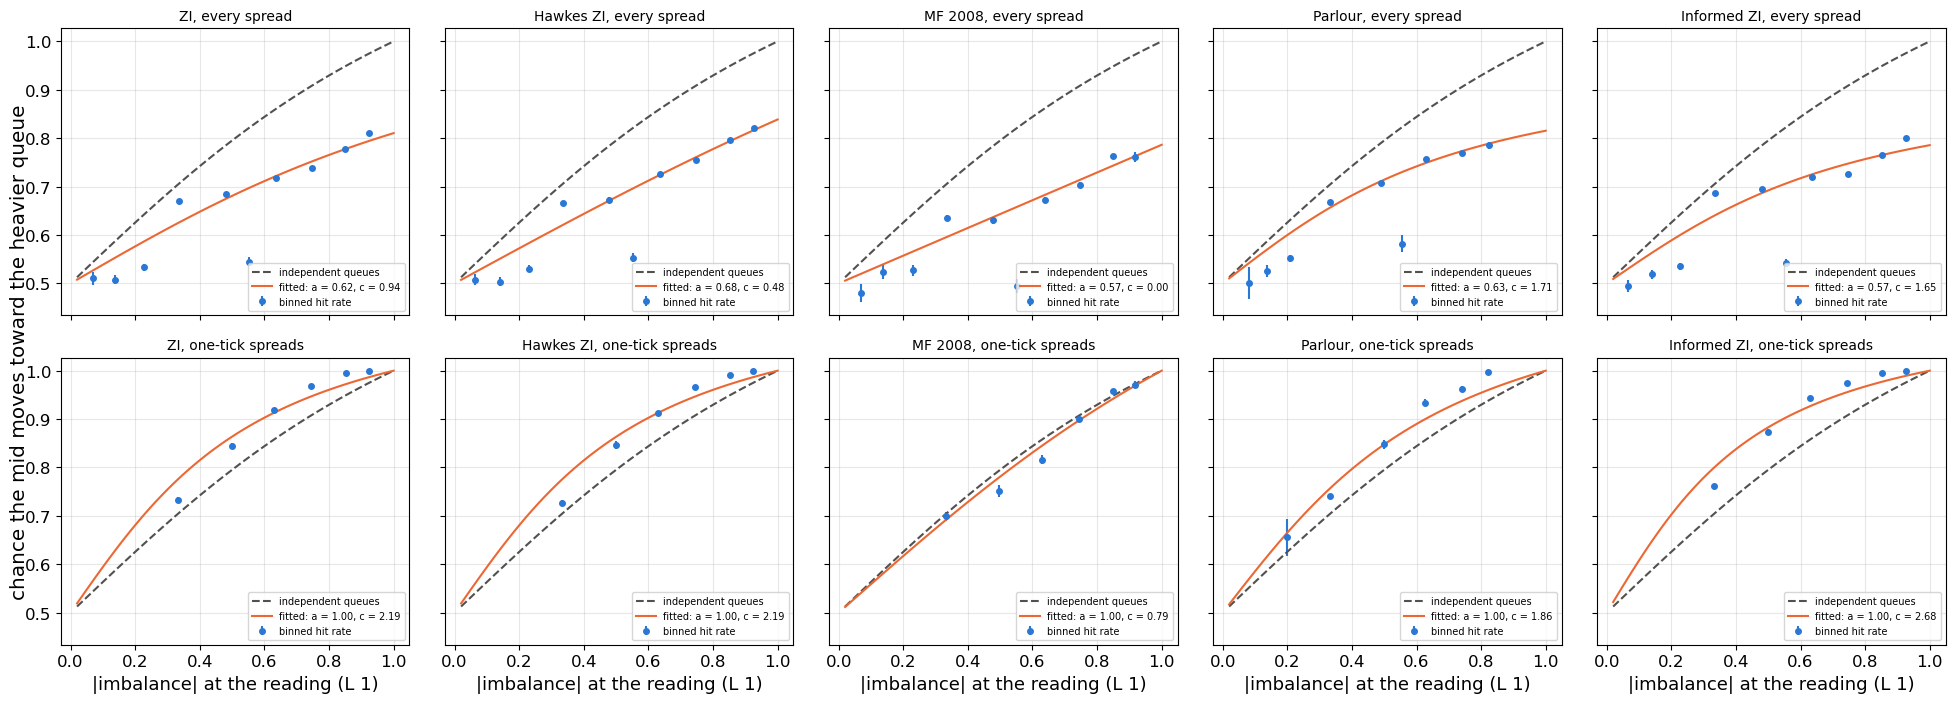

In [4]:
def race_probability(x, a, c):
    # The queue race of independent queues: the chance that the mid moves toward the heavier queue is
    # 1/2 + (2/pi) arctan(|I|), which is VisualHFT's 1/2 + arctan(c |I|) / (2 arctan c) at c = 1 (Cont and de Larrard
    # 2013; Avellaneda, Reed and Stoikov 2011). `a` scales what it adds to 1/2.
    return 0.5 + a * np.arctan(c * x) / (2.0 * np.arctan(c))


def race_nll(x, hit, a, c):
    p = np.clip(race_probability(x, a, c), 1e-9, 1 - 1e-9)
    return -(hit * np.log(p) + (1 - hit) * np.log1p(-p)).sum()


def logistic(t):
    return 1.0 / (1.0 + math.exp(-t))


def race_fit(x, hit):
    # Log likelihood over a constant hit rate for the curve at c = 1 as it is, with c fitted (a = 1), with a fitted
    # (c = 1), and with both; and the fitted values.
    p = hit.mean()
    constant = -(hit.sum() * math.log(p) + (len(hit) - hit.sum()) * math.log(1 - p))
    c_only = minimize(lambda t: race_nll(x, hit, 1.0, math.exp(t[0])), [0.0], method='Nelder-Mead')
    a_only = minimize(lambda t: race_nll(x, hit, logistic(t[0]), 1.0), [0.0], method='Nelder-Mead')
    both = minimize(lambda t: race_nll(x, hit, logistic(t[0]), math.exp(t[1])), [0.0, 0.0], method='Nelder-Mead')
    return {
        'n': len(x),
        'hit': p,
        'gain c=1': constant - race_nll(x, hit, 1.0, 1.0),
        'gain c fitted': constant - c_only.fun,
        'gain a fitted': constant - a_only.fun,
        'gain both': constant - both.fun,
        'c (a = 1)': math.exp(c_only.x[0]),
        'a (c = 1)': logistic(a_only.x[0]),
        'a': logistic(both.x[0]),
        'c': math.exp(both.x[1]),
    }


SUBSETS = {
    'all': lambda spread: spread > 0,
    'one tick': lambda spread: spread == 1,
    'two ticks': lambda spread: spread == 2,
    'three or more': lambda spread: spread >= 3,
}
pooled = {key: np.concatenate(rows[key]).astype(float) for key in MODELS}  # |I|, hit, spread of every scored change
fits = {}
for key in MODELS:
    for name, keep in SUBSETS.items():
        data = pooled[key][keep(pooled[key][:, 2])]
        fits[key, name] = race_fit(data[:, 0], data[:, 1])
fit_table = pd.DataFrame(
    {
        (NAMES[key], name): {
            'scored (all seeds)': f'{fits[key, name]["n"]:,}',
            'hit %': f'{100 * fits[key, name]["hit"]:.1f}',
            'log-lik gain, c = 1': f'{fits[key, name]["gain c=1"]:,.0f}',
            'c fitted (a = 1)': f'{fits[key, name]["gain c fitted"]:,.0f} (c = {fits[key, name]["c (a = 1)"]:.2g})',
            'a fitted (c = 1)': f'{fits[key, name]["gain a fitted"]:,.0f} (a = {fits[key, name]["a (c = 1)"]:.2f})',
            'both fitted': f'{fits[key, name]["gain both"]:,.0f} (a = {fits[key, name]["a"]:.2f}, '
            f'c = {fits[key, name]["c"]:.2f})',
        }
        for key in MODELS
        for name in SUBSETS
    }
).T
note(
    'The queue-race curve against L 1 readings at the first nonzero imbalance (pooled over the seeds): the log',
    'likelihood each version gains over a constant hit rate, and its fitted values, by the spread at the reading.',
)
display(fit_table)

BINS = np.linspace(0, 1, 11)
fig, axes = plt.subplots(2, len(MODELS), figsize=(4.0 * len(MODELS), 7.2), sharex=True, sharey=True)
for j, key in enumerate(MODELS):
    for i, (name, title) in enumerate((('all', 'every spread'), ('one tick', 'one-tick spreads'))):
        ax = axes[i, j]
        data = pooled[key][SUBSETS[name](pooled[key][:, 2])]
        x, hit = data[:, 0], data[:, 1]
        centers, rates, errors = [], [], []
        for low, high in zip(BINS[:-1], BINS[1:], strict=True):
            inside = (x > low) & (x <= high)
            if inside.sum() >= 100:
                centers.append(x[inside].mean())
                rates.append(hit[inside].mean())
                errors.append(math.sqrt(hit[inside].mean() * (1 - hit[inside].mean()) / inside.sum()))
        grid_x = np.linspace(0.02, 1, 100)
        fit = fits[key, name]
        ax.errorbar(centers, rates, yerr=errors, fmt='o', color=BLUE, markersize=4, label='binned hit rate')
        ax.plot(grid_x, race_probability(grid_x, 1.0, 1.0), color=GRAY, linestyle='--', label='independent queues')
        ax.plot(
            grid_x,
            race_probability(grid_x, fit['a'], fit['c']),
            color=ORANGE,
            label=f'fitted: a = {fit["a"]:.2f}, c = {fit["c"]:.2f}',
        )
        ax.set_title(f'{NAMES[key]}, {title}', fontsize=10)
        ax.legend(fontsize=7, loc='lower right')
        if i == 1:
            ax.set_xlabel('|imbalance| at the reading (L 1)')
fig.supylabel('chance the mid moves toward the heavier queue')
plt.tight_layout()
plt.show()

The comparison is R-001's event design: after each change of the mid, the first event that leaves the mid alone and gives a nonzero imbalance, its sign scored against the direction of the next change, over 4,000 units a run on seeds 101 to 108. It is scored against two baselines, 50% (R-001's) and the reversal rate (predict minus the last change), and the lift is the hit rate less the better of the two.

**The queue imbalance at the touch beats the reversal baseline by 5.6 to 11.1 pp in every model, and 50% flatters it.** In ZI the L 1 imbalance hits 71.1% (se 0.1) on 13,014 changes scored a run, against a reversal rate of 63.9% (se 0.1): a lift of 7.2 pp (se 0.1). The lifts are 7.4, 5.6, 11.1 and 7.7 pp in Hawkes ZI, MF 2008, Parlour and Informed ZI (se 0.2 to 0.3), over reversal rates of 64.3, 61.3, 57.8 and 63.7%. Against 50% alone, the baseline R-001 uses, the same hit rates read 16.9 to 21.8 pp. They are not comparable to R-001's +5.0 pp on Nasdaq ITCH: what the reversal rate is in its data is not known here.

**Beyond the touch, equal weights lose to the reversal baseline and touch weights repair that only in part.** Equal weights at L 3, 5 and 10 lift by -7.5 to +2.1 pp, below 0 in 13 of the 15 cells (at L 10: -2.1, -1.8, -7.5, -4.1 and -3.8 pp, se 0.1 to 0.2; the other two are Parlour at L 3 and L 5, +2.1 (se 0.2) and +0.1 (se 0.2); Hawkes ZI at L 3, -0.0 (se 0.2), is below 0 by its sign only). Touch weights are above 0 at every level, 0.5 to 4.3 pp, but below L 1: at L 10, 1.4, 2.9, 2.2, 3.7 and 0.7 pp (se 0.1 to 0.2). L 1 equal and touch are the same number, as the first level's weight is 1. VisualHFT's code defaults to equal weights, with its touch weighting, w(d) = (1 + d/S)^-2, opt-in, and has no exp(-0.5 k) weighting, which its older note used: the equal-weight rows are the code's default, and touch L 10 is R-001's form.

**The dropped share depends on the setting and on the design.** A change is dropped when no event gives a reading before the next change. In ZI that is 17.3% (se 0.1) of the changes at L 1 and 8.2 to 8.4% at L 3 and beyond; in Parlour 52.8% (se 0.1) at L 1 and 39.4 to 40.8% beyond. Letting the change event's own state give the reading (the inclusive design) drops 10.2% (se 0.1) at L 1 in ZI and 25.9% (se 0.1) in Parlour. The reviews' "about 12% dropped in ZI" belonged to that inclusive design (10.6% in the review's own run), not to the strict design scored here. Dropping the changes whose next change comes more than 30 units later, as R-001 does with 30 seconds, drops 0.000% (se 0.000) in every model.

**R-001's one-tick effect holds for the hit rate and not for the lift.** At one-tick spreads the L 1 imbalance hits 89.1% (se 0.2) in ZI against 64.5% (se 0.1) at wider ones, but the reversal rate is 87.0% (se 0.3) against 55.5% (se 0.1), so the lift is 2.2 pp (se 0.1) at one tick and 9.0 pp (se 0.2) wider. The small one-tick lift is a ceiling and not a weaker signal. Where the reversal rate is above 50%, as it is in every cell here, the lift equals the share of changes on which the imbalance disagrees with the reversal prediction times (2 x the imbalance's hit rate on those changes - 1), so it can be no larger than that share. An independent check outside this notebook found that at a one-tick spread the share is a small fraction of the changes in four models and much larger at wider spreads, because the queue the imbalance reads is the one the move just thinned, and that when the imbalance does disagree it is right more often at one tick than wider. Outside Parlour (8.3 pp, se 0.4) the one-tick lift is 1.9 to 2.3 pp, against 6.9 to 11.5 pp wider in every model; the same check found Parlour's larger one-tick lift to come from a larger disagreement share and not from being right more often when it disagrees. For touch L 10 the lift at one-tick spreads is below 0 in every model (-6.0 pp (se 0.3) in ZI, -8.2 (se 0.3) in Informed ZI) and +3.9 to +6.0 pp wider: at one tick the touch-weighted reading disagrees with the reversal on more of the changes than L 1 does and is right on fewer than half of those, by the same check.

**The queue race fits one-tick spreads and over-predicts the rest.** The curve for independent queues, 1/2 + (2/pi) arctan |I|, which is VisualHFT's 1/2 + arctan(c |I|) / (2 arctan c) at c = 1, beats a constant hit rate at one-tick spreads (a gain in log likelihood of 1,391 in ZI, and 1,195, 468, 228 and 1,148 in the others) and loses to it over every spread (-8,946 in ZI, -13,638 in Informed ZI). With an amplitude a (what the curve adds to 1/2) and c fitted, a reaches its upper limit of 1.00 at one tick in all five models (the fit does not allow more, and the fit with a alone gains exactly what the curve at c = 1 does), so the data there are at least as steep as the curve for independent queues, with c at 2.19, 2.19, 0.79, 1.86 and 2.68. For wider spreads a is an interior estimate and it falls with the spread: in ZI 0.54 at two ticks and 0.31 at three or more, and 0.57 to 0.68 over every spread. At a wider spread a limit order inside the spread moves the mid whatever the queues say, so the race is the whole story only where the mid can move only by a queue emptying.

**The look-ahead trap flips the sign here.** Pairing the once-a-unit sample (the state at the end of a unit) with the change of the mid over that same unit, as a join on a bucket's open time does, gives an agreement of signs of 24.9% (se 0.2), the mean over the five models at L 1; pairing it with the next unit's change, the causal pairing, gives 70.9% (se 0.1). By model the two are 23.8, 22.6, 23.6, 29.1 and 25.2% against 72.8, 73.3, 69.3, 67.8 and 71.6%. R-002 found that the same mistake inflated VisualHFT's touch-weighted lead from +1.26 pp to +15.78 pp; here it has the opposite sign because, in the reviews' reading (not tested here), a move exposes a deep level and the end-of-unit imbalance points back at the reversal. The sign of the bias depends on the book's queues, and a sample must be paired only with changes after its time.

## 2. Order Flow Imbalance: Explained or Forecast?

OFI over intervals of simulation time: the same-interval fit of the mid change on OFI, and the forecast of the next
interval's change, as correlations (mean over seeds, standard error across them). The forecast is scored against what
the last interval's own mid change forecasts, and by OFI's partial correlation with the next change given it.


intervals a run same-interval R2  \
1 units  ZI                    5,002    0.322 (0.005)   
         Hawkes ZI             5,016    0.250 (0.005)   
         MF 2008               4,937    0.322 (0.003)   
         Parlour               5,024    0.410 (0.003)   
         Informed ZI           4,994    0.279 (0.003)   
5 units  ZI                    1,000    0.306 (0.010)   
         Hawkes ZI             1,003    0.227 (0.004)   
         MF 2008                 987    0.422 (0.006)   
         Parlour               1,004    0.446 (0.009)   
         Informed ZI             998    0.242 (0.006)   
10 units ZI                      500    0.322 (0.013)   
         Hawkes ZI               501    0.238 (0.011)   
         MF 2008                 493    0.495 (0.010)   
         Parlour                 502    0.474 (0.009)   
         Informed ZI             499    0.308 (0.005)   
50 units ZI                      100    0.450 (0.023)   
         Hawkes ZI               100    0.363 (0.031)   
         MF 2008                  98    0.768 (0.013)   
         Parlour                 100    0.607 (0.020)   
         Informed ZI              99    0.711 (0.016)   

                     OFI against the next change  \
1 units  ZI                         -0.22 (0.00)   
         Hawkes ZI                  -0.21 (0.00)   
         MF 2008                    -0.08 (0.00)   
         Parlour                    -0.18 (0.01)   
         Informed ZI                -0.20 (0.00)   
5 units  ZI                         -0.22 (0.01)   
         Hawkes ZI                  -0.22 (0.01)   
         MF 2008                    -0.09 (0.01)   
         Parlour                    -0.21 (0.01)   
         Informed ZI                -0.05 (0.01)   
10 units ZI                         -0.23 (0.02)   
         Hawkes ZI                  -0.17 (0.01)   
         MF 2008                    -0.04 (0.02)   
         Parlour                    -0.20 (0.01)   
         Informed ZI                 0.08 (0.02)   
50 units ZI                         -0.13 (0.03)   
         Hawkes ZI                  -0.07 (0.02)   
         MF 2008                     0.13 (0.04)   
         Parlour                    -0.05 (0.03)   
         Informed ZI                 0.27 (0.02)   

                     the last change against the next  \
1 units  ZI                              -0.32 (0.00)   
         Hawkes ZI                       -0.33 (0.01)   
         MF 2008                         -0.21 (0.00)   
         Parlour                         -0.28 (0.01)   
         Informed ZI                     -0.36 (0.01)   
5 units  ZI                              -0.37 (0.01)   
         Hawkes ZI                       -0.37 (0.01)   
         MF 2008                         -0.25 (0.01)   
         Parlour                         -0.33 (0.01)   
         Informed ZI                     -0.36 (0.01)   
10 units ZI                              -0.35 (0.02)   
         Hawkes ZI                       -0.32 (0.02)   
         MF 2008                         -0.17 (0.02)   
         Parlour                         -0.33 (0.01)   
         Informed ZI                     -0.27 (0.02)   
50 units ZI                              -0.27 (0.04)   
         Hawkes ZI                       -0.23 (0.03)   
         MF 2008                          0.06 (0.04)   
         Parlour                         -0.14 (0.05)   
         Informed ZI                      0.18 (0.03)   

                     OFI beyond the last change OFI against the next OFI  
1 units  ZI                        -0.05 (0.01)              0.03 (0.01)  
         Hawkes ZI                 -0.05 (0.00)              0.02 (0.01)  
         MF 2008                    0.05 (0.00)              0.21 (0.01)  
         Parlour                   -0.00 (0.01)             -0.00 (0.00)  
         Informed ZI               -0.01 (0.01)              0.14 (0.01)  
5 units  ZI                        -0.02 (0.01)              0.06 (0.01)  
       

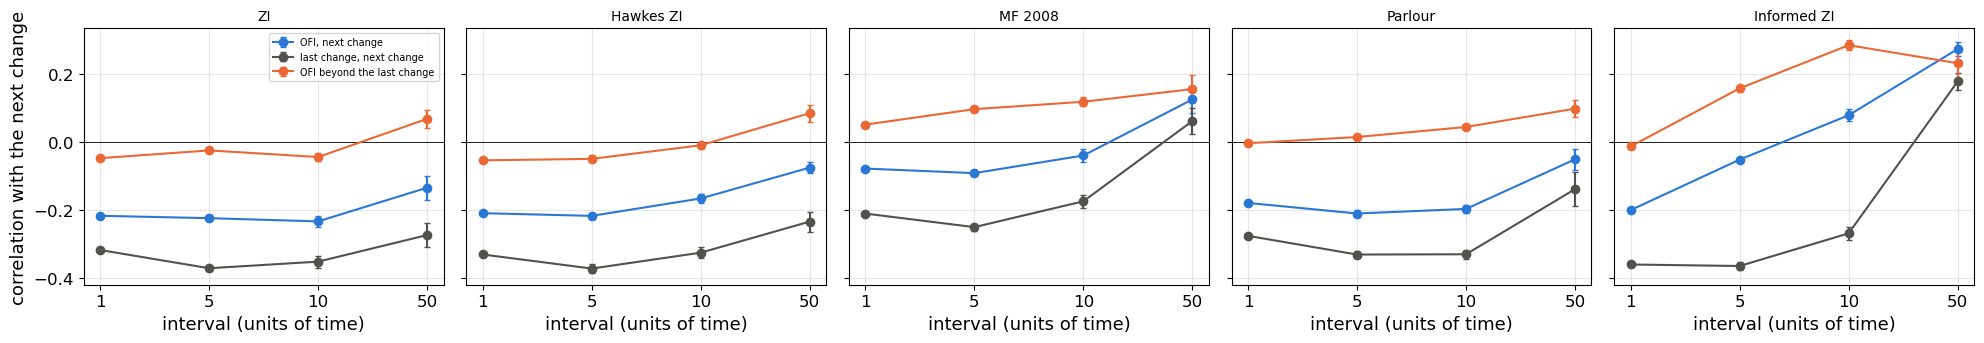

In [5]:
OFI_UNITS = 5_000  # units of simulation time a run, after the warm-up
INTERVALS = (1, 5, 10, 50)  # units of simulation time: Cont, Kukanov and Stoikov's are 10 seconds
OFI_MAIN, OFI_LONG = 10, 50  # the two intervals the conclusions quote
assert {OFI_MAIN, OFI_LONG} <= set(INTERVALS)


class FlowCollector:
    # The order flow imbalance of each unit of simulation time (the library's increment e_n of each event, summed), and
    # the mid at the start of each unit, from the book before the event that opens it. Nothing from the warm-up.
    def __init__(self):
        self.unit = 0
        self.first = None
        self.mid = []
        self.flow = {}

    def on_pre(self, warm, t, book):
        while self.unit < int(t):
            self.unit += 1
            if not warm:
                if self.first is None:
                    self.first = self.unit
                self.mid.append(np.nan if book.mid_price is None else book.mid_price)

    def observe(self, warm, t, kind, side, price, size, fills, aggressor, before, after, book, own=False):
        if not warm:
            e = ofi_increment(before, after)
            if e:
                self.flow[int(t)] = self.flow.get(int(t), 0.0) + e

    def units(self):
        flow = np.zeros(len(self.mid))
        for unit, value in self.flow.items():
            if self.first <= unit < self.first + len(flow):
                flow[unit - self.first] = value
        return flow, np.array(self.mid)


def interval_fits(flow, mid, h):
    # Intervals of h units: the mid's change over the interval, its OFI, and the same of the next interval.
    k = (len(mid) - 1) // h
    start = np.arange(k) * h
    ofi = np.add.reduceat(flow[: k * h], start)
    move = mid[start + h] - mid[start]
    now_ofi, now_move, next_move, next_ofi = ofi[:-1], move[:-1], move[1:], ofi[1:]
    ok = np.isfinite(ofi) & np.isfinite(move)
    return {
        'intervals': k,
        'same R2': correlation(ofi, move) ** 2,
        'slope': np.cov(ofi[ok], move[ok])[0, 1] / ofi[ok].var(ddof=1),
        'OFI against the next change': correlation(now_ofi, next_move),
        'the last change against the next': correlation(now_move, next_move),
        'OFI beyond the last change': partial_correlation(now_ofi, next_move, now_move),
        'OFI against the next OFI': correlation(now_ofi, next_ofi),
    }


def ofi_run(key, seed):
    collector = FlowCollector()
    simulate(make_model(key), key, seed, OFI_UNITS, [collector.observe], collector.on_pre)
    flow, mid = collector.units()
    return key, seed, {h: interval_fits(flow, mid, h) for h in INTERVALS}


ofi_runs = Parallel(n_jobs=N_JOBS)(delayed(ofi_run)(key, seed) for key in MODELS for seed in FEW)
ofi_stats = {(key, h): pd.DataFrame([r[2][h] for r in ofi_runs if r[0] == key]) for key in MODELS for h in INTERVALS}

ofi_table = pd.DataFrame(
    {
        (f'{h} units', NAMES[key]): {
            'intervals a run': f'{ofi_stats[key, h]["intervals"].mean():,.0f}',
            'same-interval R2': said(ofi_stats[key, h]['same R2']),
            'OFI against the next change': said(ofi_stats[key, h]['OFI against the next change'], 2),
            'the last change against the next': said(ofi_stats[key, h]['the last change against the next'], 2),
            'OFI beyond the last change': said(ofi_stats[key, h]['OFI beyond the last change'], 2),
            'OFI against the next OFI': said(ofi_stats[key, h]['OFI against the next OFI'], 2),
        }
        for h in INTERVALS
        for key in MODELS
    }
).T
note(
    'OFI over intervals of simulation time: the same-interval fit of the mid change on OFI, and the forecast of the '
    "next interval's change, as correlations (mean over seeds, standard error across them). The forecast is scored "
    "against what the last interval's own mid change forecasts, and by OFI's partial correlation with the next change "
    'given it.'
)
display(ofi_table)

fig, axes = plt.subplots(1, len(MODELS), figsize=(4.0 * len(MODELS), 3.6), sharey=True)
for ax, key in zip(axes, MODELS, strict=True):
    for column, color, label in (
        ('OFI against the next change', BLUE, 'OFI, next change'),
        ('the last change against the next', GRAY, 'last change, next change'),
        ('OFI beyond the last change', ORANGE, 'OFI beyond the last change'),
    ):
        means = [ofi_stats[key, h][column].mean() for h in INTERVALS]
        errors = [mean_se(ofi_stats[key, h][column])[1] for h in INTERVALS]
        ax.errorbar(range(len(INTERVALS)), means, yerr=errors, marker='o', color=color, label=label, capsize=2)
    ax.axhline(0, color='black', linewidth=0.6)
    ax.set_xticks(range(len(INTERVALS)), [f'{h}' for h in INTERVALS])
    ax.set_xlabel('interval (units of time)')
    ax.set_title(NAMES[key], fontsize=10)
axes[0].set_ylabel('correlation with the next change')
axes[0].legend(fontsize=7)
plt.tight_layout()
plt.show()

The comparison is Cont, Kukanov and Stoikov's: the mid's change over an interval on the interval's order flow imbalance (OFI), as a fit to the same interval and as a forecast of the next interval's change, over 5,000 units a run on seeds 101 to 108, in intervals of 1, 5, 10 and 50 units (theirs are 10 seconds). The forecast is scored against the baseline that section 1 found: what the last interval's own mid change forecasts, and OFI's partial correlation with the next change given it.

**OFI explains the interval it falls in, more at 50 units than at 1, with a dip at 5 units in three models.** The same-interval R2 at 10 units is 0.322 (se 0.013) in ZI, 0.238 (se 0.011) in Hawkes ZI, 0.495 (se 0.010) in MF 2008, 0.474 (se 0.009) in Parlour and 0.308 (se 0.005) in Informed ZI. Across the five it is 0.250 to 0.410 at 1 unit and 0.363 to 0.768 at 50, higher at 50 than at 1 in every model but not rising throughout: it dips at 5 units in ZI (0.322, 0.306, 0.322 and 0.450 at 1, 5, 10 and 50 units), Hawkes ZI and Informed ZI. VisualHFT's note calls CKS's 65% "a same-interval explanatory fit, not a forecast"; the next paragraphs score the forecast.

**Scored against the last change, OFI forecasts almost nothing in ZI, Hawkes ZI and Parlour.** At 10 units the correlation of OFI with the next interval's mid change is negative in four of the five models (-0.23, -0.17, -0.04 and -0.20 in ZI, Hawkes ZI, MF 2008 and Parlour; +0.08 in Informed ZI), but the last change alone forecasts the next by more: -0.35, -0.32, -0.17, -0.33 and -0.27. So the negative forecast is the mid's own reversal, which OFI shows because it explained the last change. Given the last change, OFI's partial correlation with the next is about zero in Hawkes ZI (-0.01 (se 0.01)), slightly negative in ZI (-0.04 (se 0.01)) and slightly positive in Parlour (+0.04 (se 0.01)): small, and four standard errors from 0 in ZI and in Parlour, with opposite signs.

**In Informed ZI what OFI adds to the last change is the gap between V and the mid, which the informed orders reveal; in MF 2008 it is the persistence of the flow.** The partial is +0.28 (se 0.02) in Informed ZI and +0.12 (se 0.01) in MF 2008. An independent check outside this notebook, on the informed model, found that the forecast sits in the informed orders' part of OFI, a proxy for that gap: the uninformed part adds nothing beside the last change and the informed part, and given the gap at the end of the interval OFI's own partial is negative. The same check found that persistence on its own does not give OFI a forecast: one-sided uninformed flow that persists (no informed traders, persistence 0.7 and 0.85) left OFI's partial at about 0, as in ZI, with OFI itself no more persistent than in ZI, and with V held fixed the informed orders' part still forecast although OFI was anti-persistent. OFI's correlation with the next interval's OFI at 10 units is 0.55 (se 0.02) in Informed ZI and 0.30 (se 0.02) in MF 2008, against 0.08 (se 0.02), 0.05 (se 0.02) and -0.00 (se 0.01) in ZI, Hawkes ZI and Parlour. MF 2008, whose order signs have long memory (Hurst 0.75 in its parameters), is the one model here where OFI adds to the last change with nothing behind it; that its persistence is the cause is a reading and not something tested here.

**The sign of the forecast depends on the interval.** In Informed ZI OFI's correlation with the next change is -0.20 (se 0.00) at 1 unit, -0.05 (se 0.01) at 5, +0.08 (se 0.02) at 10 and +0.27 (se 0.02) at 50; in MF 2008 it goes from -0.08 to +0.13 (se 0.04) at 50; in ZI, Hawkes ZI and Parlour it stays negative at every interval (-0.13, -0.07 and -0.05 at 50). At 50 units OFI's partial beyond the last change is positive in every model: 0.07, 0.09, 0.16, 0.10 and 0.23 (se 0.03 to 0.05).

**VisualHFT lists OFI on its website and not in its code.** Its OFI is Cont, Kukanov and Stoikov's best-quote rule summed over a trailing window of 1, 2, 3 or 5 seconds (5 by default), published every 100 ms. The notebook's is the library's increment (the same rule) summed over fixed intervals of simulation time, and says nothing of a tile's window.

## 3. Who Was the Aggressor?

In [6]:
SIDES_UNITS = 4_000  # units of simulation time a run, after the warm-up
DELTAS = {
    'tick rule': dict(side='tick'),
    'quote rule, lag 0': dict(side='quote', quote_lag=0),
    'quote rule, lag 1': dict(side='quote', quote_lag=1),
    'quote rule, lag 5': dict(side='quote', quote_lag=5),
}
VPINS = {
    'true': dict(side='true'),
    'tick': dict(side='tick'),
    'mid, lag 0': dict(side='mid', quote_lag=0),
    'mid, lag 1': dict(side='mid', quote_lag=1),
    'bvc': dict(side='bvc'),
}


class SidesCollector:
    # Four delta-of-trades studies and five VPINs, each fill's side inferred by a rule, beside the true side. The deltas
    # start at the end of the warm-up (they count what they classified since their start); the VPINs run through it, and
    # the buckets closed in it are left out afterwards.
    def __init__(self):
        self.deltas = {name: TradeDelta(**settings) for name, settings in DELTAS.items()}
        self.vpins = {name: VPIN(log_buckets=True, **settings) for name, settings in VPINS.items()}
        self.unit = 0
        self.began = False
        self.t_warm = 0.0

    def on_pre(self, warm, t, book):
        if not warm and not self.began:
            self.began = True
            for study in self.deltas.values():
                study.reset(self.unit, t)
        while self.unit < int(t):
            self.unit += 1
            for study in (*self.deltas.values(), *self.vpins.values()):
                study.sample(self.unit, book)

    def observe(self, warm, t, kind, side, price, size, fills, aggressor, before, after, book, own=False):
        if warm:
            self.t_warm = t
        if fills:
            for study in (*self.deltas.values(), *self.vpins.values()):
                study.observe(t, kind, side, price, size, fills, aggressor, before, after, book, own)


def sides_run(key, seed):
    collector = SidesCollector()
    simulate(make_model(key), key, seed, SIDES_UNITS, [collector.observe], collector.on_pre)
    fills = {}
    for name, study in collector.deltas.items():
        values = study.values()
        fills[name] = (values['coverage'], values['accuracy'])
    logs = {}
    for name, study in collector.vpins.items():
        log = np.array([(t, i, np.nan if s is None else s, share) for t, i, s, share in study.log], dtype=float)
        logs[name] = log[log[:, 0] > collector.t_warm]  # the buckets that closed after the warm-up
    return key, seed, fills, logs, collector.vpins['true'].volume_in_use


sides_runs = Parallel(n_jobs=N_JOBS)(delayed(sides_run)(key, seed) for key in MODELS for seed in FEW)
sides = {key: [r for r in sides_runs if r[0] == key] for key in MODELS}
print('Lots in a VPIN bucket (50 median fills):', {NAMES[key]: sides[key][0][4] for key in MODELS})
# The fair-coin level of a VPIN depends on how many fills a bucket holds: in ZI every market order is one size.
coin_lots = sides['smith_zi'][0][4]
coin_fills = coin_lots / PARAMS['smith_zi']['lot_size']

accuracy = pd.DataFrame(
    {
        NAMES[key]: {
            name: said([r[2][name][1] for r in sides[key]], 1, 100) + (' *' if name == 'quote rule, lag 0' else '')
            for name in DELTAS
        }
        for key in MODELS
    }
).T
note(
    'Per fill: the share of the fills classified that the rule gets right (mean over seeds, standard error across '
    'them).',
    '* At lag 0 the quote rule reads the mid just before the event, which every fill is on the right side of: exact',
    'by construction, a check and not a result.',
)
display(accuracy)
coverage = min(r[2][name][0] for key in MODELS for r in sides[key] for name in DELTAS)
note(
    f'Coverage, the share of the lots classified at all: at least {100 * coverage:.2f}% in every run.',
)

BUCKET_RULES = ('tick', 'mid, lag 1', 'bvc')
per_bucket = {}
for key in MODELS:
    row = {}
    for rule in BUCKET_RULES:
        corr, error = [], []
        for _, _, _, logs, _ in sides[key]:
            share, true_share = logs[rule][:, 2], logs[rule][:, 3]
            ok = np.isfinite(share)
            corr.append(correlation(share[ok], true_share[ok]))
            error.append(np.abs(share[ok] - true_share[ok]).mean())
        row[f'{rule}: correlation'] = said(corr, 2)
        row[f'{rule}: mean absolute error'] = said(error, 3)
    per_bucket[NAMES[key]] = row
note(
    '\nPer bucket of 250 lots: the inferred buy share against the true one (correlation, and the mean absolute error).',
)
display(pd.DataFrame(per_bucket).T)

levels = {}
for key in MODELS:
    row = {}
    window = {rule: [trailing(logs[rule][:, 1]) for _, _, _, logs, _ in sides[key]] for rule in VPINS}
    for rule in VPINS:
        row[f'{rule}: level'] = said([np.nanmean(v) for v in window[rule]])
    for rule in ('tick', 'mid, lag 1', 'bvc'):
        row[f'{rule}: correlation with true'] = said(
            [correlation(a, b) for a, b in zip(window[rule], window['true'], strict=True)], 2
        )
    levels[NAMES[key]] = row
note(
    '\nVPIN (trailing 50 buckets) by the rule that signs the fills: its level, and its correlation with the true '
    "side's.",
    f'Independent fair-coin sides in n fills of one size give a bucket sqrt(2 / (pi n)) = '
    f'{math.sqrt(2 / (math.pi * coin_fills)):.3f} at n = {coin_fills:g}, the {coin_lots:g} lots of a ZI bucket over '
    f"its market orders' {PARAMS['smith_zi']['lot_size']} lots (n is the fills in a bucket, not the buckets in the "
    'window).',
)
display(pd.DataFrame(levels).T)
bvc_levels = [np.mean([np.nanmean(trailing(x[3]['bvc'][:, 1])) for x in sides[key]]) for key in MODELS]
note(
    'Bulk volume classification gives a bucket the buy share Phi(x), x its mid change in units of the standard '
    "deviation of the last 100 buckets'. When x is standard normal |2 Phi(x) - 1| is uniform on (0, 1), with mean 1/2, "
    f'whatever the flow: its VPIN is {min(bvc_levels):.3f} to {max(bvc_levels):.3f} here, in every model.',
)
exact = max(np.abs(r[3]['mid, lag 0'][:, 1] - r[3]['true'][:, 1]).max() for key in MODELS for r in sides[key])
note(
    f'Largest difference between the mid rule at lag 0 and the true side in any bucket of any run: {exact}.',
)

Lots in a VPIN bucket (50 median fills): {'ZI': 250.0, 'Hawkes ZI': 250.0, 'MF 2008': 250.0, 'Parlour': 250.0, 'Informed ZI': 250.0}
Per fill: the share of the fills classified that the rule gets right (mean over seeds, standard error across them). * At
lag 0 the quote rule reads the mid just before the event, which every fill is on the right side of: exact by
construction, a check and not a result.


,tick rule,"quote rule, lag 0","quote rule, lag 1","quote rule, lag 5"
ZI,92.2 (0.0),100.0 (0.0) *,90.1 (0.1),77.4 (0.1)
Hawkes ZI,92.8 (0.1),100.0 (0.0) *,90.2 (0.1),80.4 (0.2)
MF 2008,94.7 (0.1),100.0 (0.0) *,95.4 (0.1),84.8 (0.1)
Parlour,90.5 (0.1),100.0 (0.0) *,86.8 (0.0),72.4 (0.2)
Informed ZI,90.5 (0.1),100.0 (0.0) *,87.5 (0.1),77.4 (0.1)


Coverage, the share of the lots classified at all: at least 99.80% in every run.

Per bucket of 250 lots: the inferred buy share against the true one (correlation, and the mean absolute error).


,tick: correlation,tick: mean absolute error,"mid, lag 1: correlation","mid, lag 1: mean absolute error",bvc: correlation,bvc: mean absolute error
ZI,0.79 (0.00),0.034 (0.000),0.77 (0.01),0.048 (0.000),0.45 (0.01),0.233 (0.002)
Hawkes ZI,0.80 (0.01),0.033 (0.000),0.75 (0.01),0.048 (0.001),0.37 (0.02),0.221 (0.001)
MF 2008,0.95 (0.00),0.028 (0.001),0.96 (0.00),0.031 (0.001),0.71 (0.01),0.200 (0.003)
Parlour,0.77 (0.01),0.036 (0.001),0.72 (0.01),0.050 (0.001),0.50 (0.02),0.222 (0.002)
Informed ZI,0.86 (0.01),0.043 (0.000),0.82 (0.01),0.057 (0.001),0.43 (0.01),0.224 (0.001)



VPIN (trailing 50 buckets) by the rule that signs the fills: its level, and its correlation with the true side's.
Independent fair-coin sides in n fills of one size give a bucket sqrt(2 / (pi n)) = 0.113 at n = 50, the 250 lots of a
ZI bucket over its market orders' 5 lots (n is the fills in a bucket, not the buckets in the window).


,true: level,tick: level,"mid, lag 0: level","mid, lag 1: level",bvc: level,tick: correlation with true,"mid, lag 1: correlation with true",bvc: correlation with true
ZI,0.113 (0.001),0.102 (0.001),0.113 (0.001),0.144 (0.002),0.504 (0.004),0.61 (0.05),0.43 (0.07),0.06 (0.08)
Hawkes ZI,0.111 (0.001),0.099 (0.001),0.111 (0.001),0.146 (0.002),0.471 (0.002),0.62 (0.05),0.48 (0.04),-0.00 (0.11)
MF 2008,0.195 (0.004),0.183 (0.003),0.195 (0.004),0.202 (0.004),0.524 (0.006),0.83 (0.09),0.76 (0.08),0.27 (0.15)
Parlour,0.113 (0.002),0.103 (0.002),0.113 (0.002),0.144 (0.003),0.492 (0.003),0.43 (0.06),0.50 (0.07),0.28 (0.11)
Informed ZI,0.170 (0.003),0.128 (0.002),0.170 (0.003),0.179 (0.003),0.498 (0.003),0.88 (0.03),0.77 (0.03),-0.08 (0.09)


Bulk volume classification gives a bucket the buy share Phi(x), x its mid change in units of the standard deviation of
the last 100 buckets'. When x is standard normal |2 Phi(x) - 1| is uniform on (0, 1), with mean 1/2, whatever the flow:
its VPIN is 0.471 to 0.524 here, in every model.
Largest difference between the mid rule at lag 0 and the true side in any bucket of any run: 0.0.


The comparison is each rule against the true aggressor, which only a simulator has: per fill for the tick rule and for the quote rule at quote lags of 0, 1 and 5 units (the mid that many units old), and per bucket of 250 lots for the tick rule, the mid at lag 1 and bulk volume classification (BVC), over 4,000 units a run on seeds 101 to 108. The share of lots classified at all is at least 99.80% in every run.

**The quote rule at lag 0 is right on every fill, by construction.** It reads the mid just before the event, and a fill is at the maker's price, on the right side of it: 100.0% (se 0.0) in every model, and no bucket of any run differs from the true side (the largest difference is 0.0). It is a check and not a result. The rules have content against a stale quote: at lag 1 the quote rule is right on 90.1, 90.2, 95.4, 86.8 and 87.5% of fills in ZI, Hawkes ZI, MF 2008, Parlour and Informed ZI (se 0.0 to 0.1), and at lag 5 on 77.4, 80.4, 84.8, 72.4 and 77.4%. The tick rule is right on 92.2, 92.8, 94.7, 90.5 and 90.5%: above the quote rule at lag 1 in four models, and below it in MF 2008 (94.7% against 95.4%). VisualHFT's code signs a print for its default VPIN against the book mid (a price at or above it is a buy, the venue's flag only if the mid is unknown) and uses the tick rule only in its opt-in corrected form, so what its default reads depends on how stale the book is when a print arrives.

**Per bucket the tick rule tracks the true buy share and BVC tracks it far worse.** The correlation of the inferred share with the true one is 0.79, 0.80, 0.95, 0.77 and 0.86 for the tick rule (se 0.00 to 0.01), 0.77, 0.75, 0.96, 0.72 and 0.82 for the mid at lag 1, and 0.45, 0.37, 0.71, 0.50 and 0.43 for BVC (se 0.01 to 0.02), BVC's being 0.37 to 0.50 in four models and 0.71 in MF 2008 against 0.77 to 0.95 for the tick rule; the mean absolute error is 0.028 to 0.043 for the tick rule and 0.200 to 0.233 for BVC. BVC does not sign fills: it gives a bucket the buy share Phi(x), x the mid's change over the bucket in units of the standard deviation of the last 100 buckets' changes, and so reads price changes and not flow (Andersen and Bondarenko 2014).

**VPIN's level depends on the rule, and BVC's is near 0.5 by identity.** True-side VPIN is 0.113 (se 0.001) in ZI, 0.111 (se 0.001) in Hawkes ZI and 0.113 (se 0.002) in Parlour, the value of independent fair-coin sides, sqrt(2 / (pi n)) = 0.113 at n = 50 (in ZI that is by construction), and 0.195 (se 0.004) in MF 2008 and 0.170 (se 0.003) in Informed ZI. Here n is the number of fills in a bucket and not the 50 buckets of the trailing window: a bucket of 250 lots holds 50 market orders of 5 lots, and the identity needs equal-size fills and independent fair sides. An independent check outside this notebook found the same level with a shorter window and a different level with buckets of other sizes. The tick rule reads 0.102, 0.099, 0.183, 0.103 and 0.128, lower in every model, and the mid at lag 1 reads 0.144, 0.146, 0.202, 0.144 and 0.179. BVC reads 0.504, 0.471, 0.524, 0.492 and 0.498 whatever the flow: when x is standard normal, |2 Phi(x) - 1| is uniform on (0, 1) with mean 1/2. Its VPIN tracks the true side's weakly or not at all (0.06 (se 0.08), -0.00 (se 0.11) and -0.08 (se 0.09) in ZI, Hawkes ZI and Informed ZI; 0.27 (se 0.15) and 0.28 (se 0.11) in MF 2008 and Parlour), where the tick rule's correlates 0.61, 0.62, 0.83, 0.43 and 0.88 (se 0.03 to 0.09).

**VisualHFT's VPIN is not the website's.** The website's default bucket of 50 times the median print and its desk bands of 0.60 and 0.75 are not in the code, whose default bucket is 1 unit, with a window of N = 50 buckets and the mid rule. The three rules are on different scales, so the bands would not carry over: no cell of section 4 reaches 0.60 (the highest true-side VPIN is 0.468 and the highest tick-rule VPIN 0.417, at persistence 0.95).

## 4. VPIN and Toxicity

In [7]:
TOXICITY_UNITS = 20_000  # units of simulation time a run, after the warm-up
# The two horizons of a markout: what the impact of a fill is soon after it (events), and what is left of it later
# (units).
HORIZON_EVENTS, HORIZON_UNITS = 100, 30.0
OFFSETS = np.arange(-5, 11)  # buckets around a jump of V
# Every cell is the informed-trader model at the dashboard's parameters but for what it names. `kappa` 0 turns the
# informed traders off. `sigma_v` 0 does not: the model's jumps (rate 0.05, 2 ticks) alone make some orders informed.
CELLS = {
    'base': dict(kappa=0.0),
    'sigma_v 0': dict(sigma_v=0.0),
    'sigma_v 0.1': dict(sigma_v=0.1),
    'sigma_v 0.3 (default)': dict(sigma_v=0.3),
    'sigma_v 0.5': dict(sigma_v=0.5),
    'sigma_v 1.0': dict(sigma_v=1.0),
    'persistence 0.7': dict(kappa=0.0, persistence=0.7),
    'persistence 0.85': dict(kappa=0.0, persistence=0.85),
    'persistence 0.95': dict(kappa=0.0, persistence=0.95),
    'kappa 0.5': dict(kappa=0.5),
    'kappa 1': dict(kappa=1.0),
    'kappa 4': dict(kappa=4.0),
    'kappa 8': dict(kappa=8.0),
    'rare jumps': dict(jump_size=6.0, jump_rate=0.005),
}
JUMP_CELLS = ('rare jumps', 'sigma_v 0.3 (default)')


class JumpInformed(InformedZIModel):
    # The informed-trader model, which also notes the jumps of V. No random number is drawn for the note: V's path is
    # the model's own.
    def __init__(self, **settings):
        super().__init__(**settings)
        self.jump_log = []  # (time, change in V, jumps in the step)
        self.lowest = math.inf

    def _advance_value_to(self, t):
        before, value = self.jumps, self._value
        super()._advance_value_to(t)
        self.lowest = min(self.lowest, self._value)
        if self.jumps > before:
            self.jump_log.append((t, self._value - value, self.jumps - before))


class FillLog:
    # The mid after every event and every fill of the model's market orders, in typed arrays, with three VPINs that
    # sign the fills by the true side, the tick rule and bulk volume classification, and, for each fill, whether its
    # taker was informed and V at the time of the order (the observer is called right after the model's event, so the
    # model's V is the one at the order's own time).
    def __init__(self, model):
        self.model = model
        self.vpins = {side: VPIN(log_buckets=True, side=side) for side in ('true', 'tick', 'bvc')}
        self.t, self.mid = array('d'), array('d')
        self.fills = array('d')  # eight numbers a fill: event, time, price, lots, taker's side, informed, V, bucket
        self.t_warm = 0.0

    def observe(self, warm, t, kind, side, price, size, fills, aggressor, before, after, book, own=False):
        if warm:
            self.t_warm = t
        mid = mid_of(after)
        self.t.append(t)
        self.mid.append(math.nan if mid is None else mid)
        if fills:
            bucket, informed, value = len(self.vpins['true'].log), float(self.model.last_informed), self.model.value()
            for fill in fills:
                self.fills.extend((len(self.t) - 1, t, fill.price, fill.size, aggressor, informed, value, bucket))
            for study in self.vpins.values():
                study.observe(t, kind, side, price, size, fills, aggressor, before, after, book, own)


def toxicity_summary(model, log, cell):
    t, mid = np.array(log.t), forward_fill(np.array(log.mid))
    n_events = len(t)
    event, ft, price, lots, side, informed, value, bucket = np.array(log.fills).reshape(-1, 8).T
    event, bucket, informed = event.astype(int), bucket.astype(int), informed.astype(bool)
    post = ft > log.t_warm
    # The maker's loss per lot (positive when the maker lost): the taker's side times what the mid later is above the
    # price.
    later = np.minimum(event + HORIZON_EVENTS, n_events - 1)
    has_events = event + HORIZON_EVENTS < n_events
    at = np.searchsorted(t, ft + HORIZON_UNITS, side='right') - 1
    has_units = ft + HORIZON_UNITS <= t[-1]
    mark_events, mark_units, loss = side * (mid[later] - price), side * (mid[at] - price), side * (value - price)
    out = {'cell': cell, 'events': n_events, 'floor': model.lowest <= model.value_floor + 1e-9}
    for name, keep in (('all', post), ('informed', post & informed), ('uninformed', post & ~informed)):
        out[f'lots {name}'] = float(lots[keep].sum())
        out[f'mark 100 events {name}'] = weighted(mark_events, lots, keep & has_events)
        out[f'mark 30 units {name}'] = weighted(mark_units, lots, keep & has_units)
        out[f'loss {name}'] = weighted(loss, lots, keep)
    out['informed share'] = out['lots informed'] / out['lots all']
    seen = post & informed
    out['loss quantiles'] = np.quantile(loss[seen], [0.1, 0.5, 0.9]) if seen.any() else np.full(3, np.nan)
    # VPINs: only the buckets that closed after the warm-up, so that no window reaches back into it.
    logs = {
        name: np.array([(a, b, np.nan if c is None else c, d) for a, b, c, d in study.log], dtype=float)
        for name, study in log.vpins.items()
    }
    skipped = int((logs['true'][:, 0] <= log.t_warm).sum())
    logs = {name: array_[skipped:] for name, array_ in logs.items()}
    nb = len(logs['true'])
    window = {name: trailing(array_[:, 1]) for name, array_ in logs.items()}
    for name in logs:
        out[f'vpin {name}'] = float(np.nanmean(window[name]))
    out['buckets'], out['V'] = nb, log.vpins['true'].volume_in_use
    # The within-run test: in bucket b + 1, the maker's loss (at 30 units, at 100 events), and the informed share of its
    # lots, against VPIN at the end of bucket b, the bucket's own imbalance, and the mean of its last five buckets'
    # imbalances.
    rel = bucket - skipped
    use = post & (rel >= 0) & (rel < nb)

    def per_bucket(x, ok):
        keep = use & ok
        num = np.bincount(rel[keep], weights=(x * lots)[keep], minlength=nb)
        den = np.bincount(rel[keep], weights=lots[keep], minlength=nb)
        return num / np.maximum(den, 1e-9), den

    y_units, n_units = per_bucket(mark_units, has_units)
    y_events, n_events_ = per_bucket(mark_events, has_events)
    y_informed, _ = per_bucket(informed.astype(float), np.ones_like(has_units))
    y_loss, _ = per_bucket(loss, np.ones_like(has_units))
    five = {name: trailing(logs[name][:, 1], 5) for name in ('true', 'tick')}
    reg = [
        (
            window['true'][j],
            window['tick'][j],
            logs['true'][j, 1],
            logs['tick'][j, 1],
            five['true'][j],
            five['tick'][j],
            y_units[j + 1],
            y_events[j + 1],
            y_informed[j + 1],
            y_loss[j + 1],
        )
        for j in range(N_BUCKETS - 1, nb - 1)
        if n_units[j + 1] >= 100 and n_events_[j + 1] >= 100
    ]
    out['reg'] = np.array(reg, dtype=float).reshape(-1, 10)
    if cell in JUMP_CELLS:
        out['jumps'] = jump_study(model, t, mid, logs, window, log.t_warm)
    return out


def jump_study(model, t, mid, logs, window, t_warm):
    # The jumps of V that came alone in their step: for each, the buckets around it (bucket 0 is the one open at the
    # jump), and how long the mid took to move half the jump. A jump is isolated if no other jump falls in the 6 buckets
    # before it to the 11 after.
    closes = logs['true'][:, 0]
    nb = len(closes)
    jumps = np.array([(a, b) for a, b, n in model.jump_log if n == 1], dtype=float).reshape(-1, 2)
    where = np.searchsorted(closes, np.array([a for a, _, _ in model.jump_log], dtype=float))
    keys = (
        'iso',
        'vpin true',
        'vpin tick',
        'imbalance true',
        'imbalance tick',
        'buy share',
        'lag units',
        'lag buckets',
    )
    found = {key: [] for key in keys}
    for when, change in jumps:
        if when <= t_warm or abs(change) < 0.45 * abs(model.jump_size):
            continue
        direction = 1.0 if change > 0 else -1.0
        bj = int(np.searchsorted(closes, when))
        if bj + OFFSETS[0] < N_BUCKETS - 1 or bj + OFFSETS[-1] >= nb:
            continue
        around = bj + OFFSETS
        others = np.delete(where, np.flatnonzero(where == bj)[:1])
        found['iso'].append(float(not np.any((others >= bj - 6) & (others <= bj + 11))))
        found['vpin true'].append(window['true'][around] - window['true'][bj - 1])
        found['vpin tick'].append(window['tick'][around] - window['tick'][bj - 1])
        found['imbalance true'].append(logs['true'][around, 1])
        found['imbalance tick'].append(logs['tick'][around, 1])
        share = logs['true'][around, 3]
        found['buy share'].append(share if direction > 0 else 1 - share)
        first = int(np.searchsorted(t, when, side='left'))
        moved = direction * (mid[first : first + 20_000] - mid[max(first - 1, 0)])
        reached = np.flatnonzero(moved >= 0.5 * abs(change))
        if len(reached):
            found['lag units'].append(t[first + reached[0]] - when)
            found['lag buckets'].append(np.searchsorted(closes, t[first + reached[0]]) - bj)
        else:
            found['lag units'].append(np.nan)
            found['lag buckets'].append(np.nan)
    found = {key: np.array(value, dtype=float) for key, value in found.items()}
    found['logged'] = len(model.jump_log)
    return found


def toxicity_run(cell, seed):
    model = JumpInformed(initial_mid=MID, record_path=False, **{**PARAMS['informed_zi'], **CELLS[cell]})
    log = FillLog(model)
    simulate(model, 'informed_zi', seed, TOXICITY_UNITS, [log.observe])
    return seed, toxicity_summary(model, log, cell)


toxicity_runs = Parallel(n_jobs=N_JOBS)(delayed(toxicity_run)(cell, seed) for cell in CELLS for seed in FEW)
toxicity = {cell: [r[1] for r in toxicity_runs if r[1]['cell'] == cell] for cell in CELLS}
note(
    f'{len(toxicity_runs)} runs of {toxicity_runs[0][1]["events"]:,} events; '
    f'{sum(r[1]["floor"] for r in toxicity_runs)} of them took V to its floor (a run that does is a different market). '
    f'VPIN buckets after the warm-up a run: {np.mean([r[1]["buckets"] for r in toxicity_runs]):,.0f}, of '
    f'{toxicity_runs[0][1]["V"]:.0f} lots.',
)

112 runs of 1,209,999 events; 0 of them took V to its floor (a run that does is a different market). VPIN buckets after
the warm-up a run: 2,731, of 250 lots.


Toxicity, by cell (mean over seeds, standard error across them). The loss against V on an informed fill is positive by
construction (an informed order is sent only when V lies beyond the quote it hits): what has content is its size.


,informed share,"VPIN, true side","VPIN, tick rule","VPIN, bvc",loss against V on informed fills,its 10th / 50th / 90th percentile
base,0.000 (0.000),0.111 (0.001),0.101 (0.001),0.499 (0.001),-,-
sigma_v 0,0.123 (0.001),0.147 (0.001),0.116 (0.001),0.494 (0.001),2.01 (0.02),1.0 / 2.0 / 3.9
sigma_v 0.1,0.134 (0.002),0.150 (0.002),0.118 (0.001),0.494 (0.001),1.86 (0.04),0.5 / 1.6 / 3.6
sigma_v 0.3 (default),0.155 (0.001),0.168 (0.001),0.129 (0.001),0.493 (0.001),2.19 (0.03),0.6 / 1.8 / 4.3
sigma_v 0.5,0.186 (0.002),0.192 (0.002),0.147 (0.002),0.495 (0.001),2.80 (0.04),0.7 / 2.2 / 5.8
sigma_v 1.0,0.257 (0.001),0.255 (0.001),0.191 (0.001),0.497 (0.001),6.04 (0.22),1.2 / 4.3 / 13.3
persistence 0.7,0.000 (0.000),0.171 (0.001),0.148 (0.001),0.504 (0.002),-,-
persistence 0.85,0.000 (0.000),0.266 (0.001),0.231 (0.001),0.510 (0.001),-,-
persistence 0.95,0.000 (0.000),0.468 (0.002),0.417 (0.002),0.521 (0.001),-,-
kappa 0.5,0.112 (0.002),0.149 (0.002),0.120 (0.001),0.497 (0.002),3.45 (0.07),1.2 / 3.1 / 6.1



Realized markouts, in ticks a lot: the maker's loss on a fill, the taker's side times the mid later less the price, by
the taker's type; and what makers earned on all fills (the minus of the aggregate markout), at both horizons.


,"informed fills, 30 units","uninformed fills, 30 units","informed fills, 100 events","uninformed fills, 100 events","maker earnings, 100 events","maker earnings, 30 units"
base,-,-0.91 (0.00),-,-0.86 (0.00),0.856 (0.002),0.910 (0.002)
sigma_v 0,1.09 (0.02),-1.07 (0.00),-0.09 (0.02),-1.01 (0.00),0.897 (0.002),0.808 (0.003)
sigma_v 0.1,1.03 (0.02),-1.08 (0.00),-0.12 (0.02),-1.02 (0.00),0.899 (0.002),0.799 (0.007)
sigma_v 0.3 (default),1.03 (0.02),-1.09 (0.00),-0.28 (0.01),-1.02 (0.00),0.908 (0.001),0.757 (0.006)
sigma_v 0.5,1.03 (0.03),-1.09 (0.00),-0.44 (0.01),-1.02 (0.00),0.917 (0.002),0.694 (0.010)
sigma_v 1.0,1.25 (0.03),-1.10 (0.00),-0.69 (0.00),-1.04 (0.00),0.950 (0.002),0.492 (0.009)
persistence 0.7,-,-0.92 (0.00),-,-0.80 (0.00),0.803 (0.002),0.924 (0.004)
persistence 0.85,-,-0.92 (0.01),-,-0.66 (0.00),0.663 (0.001),0.921 (0.006)
persistence 0.95,-,-0.83 (0.01),-,-0.38 (0.00),0.377 (0.003),0.827 (0.008)
kappa 0.5,1.02 (0.01),-1.03 (0.00),-0.43 (0.01),-0.96 (0.00),0.901 (0.002),0.798 (0.005)



Which dial moves toxicity one way: kappa raises the informed share and lowers the loss on each informed fill (the book
tracks V more closely), and sigma_v raises both. (Like for like in model, seeds and run length, not in the path of V:
the same seed gives the same normals for V, but a different path once the events differ.)


informed share  \
sigma_v sigma_v 0              0.123 (0.001)   
        sigma_v 0.1            0.134 (0.002)   
        sigma_v 0.3 (default)  0.155 (0.001)   
        sigma_v 0.5            0.186 (0.002)   
        sigma_v 1.0            0.257 (0.001)   
kappa   kappa 0.5              0.112 (0.002)   
        kappa 1                0.135 (0.001)   
        kappa 2 (default)      0.155 (0.001)   
        kappa 4                0.173 (0.001)   
        kappa 8                0.180 (0.001)   

                              loss against V on an informed fill  \
sigma_v sigma_v 0                                    2.01 (0.02)   
        sigma_v 0.1                                  1.86 (0.04)   
        sigma_v 0.3 (default)                        2.19 (0.03)   
        sigma_v 0.5                                  2.80 (0.04)   
        sigma_v 1.0                                  6.04 (0.22)   
kappa   kappa 0.5                                    3.45 (0.07)   
        kappa 1                                      2.75 (0.05)   
        kappa 2 (default)                            2.19 (0.03)   
        kappa 4                                      1.89 (0.03)   
        kappa 8                                      1.68 (0.02)   

                              maker earnings, 30 units  
sigma_v sigma_v 0                        0.808 (0.003)  
        sigma_v 0.1                      0.799 (0.007)  
        sigma_v 0.3 (default)            0.757 (0.006)  
        sigma_v 0.5                      0.694 (0.010)  
        sigma_v 1.0                      0.492 (0.009)  
kappa   kappa 0.5                        0.798 (0.005)  
        kappa 1                          0.773 (0.006)  
        kappa 2 (default)                0.757 (0.006)  
        kappa 4                          0.756 (0.006)  
        kappa 8                          0.762 (0.006)


The same VPIN, opposite earnings: each persistence cell (one-sided flow with nothing behind it) beside the informed cell
whose VPIN is nearest (within 0.02), when there is one.


VPIN, true side informed share  \
persistence 0.7  informed    kappa 8            0.172 (0.001)  0.180 (0.001)   
                 persistence persistence 0.7    0.171 (0.001)  0.000 (0.000)   
persistence 0.85 informed    sigma_v 1.0        0.255 (0.001)  0.257 (0.001)   
                 persistence persistence 0.85   0.266 (0.001)  0.000 (0.000)   

                                              maker earnings, 100 events  \
persistence 0.7  informed    kappa 8                       0.913 (0.002)   
                 persistence persistence 0.7               0.803 (0.002)   
persistence 0.85 informed    sigma_v 1.0                   0.950 (0.002)   
                 persistence persistence 0.85              0.663 (0.001)   

                                              maker earnings, 30 units  
persistence 0.7  informed    kappa 8                     0.762 (0.006)  
                 persistence persistence 0.7             0.924 (0.004)  
persistence 0.85 informed    sigma_v 1.0                 0.492 (0.009)  
                 persistence persistence 0.85            0.921 (0.006)

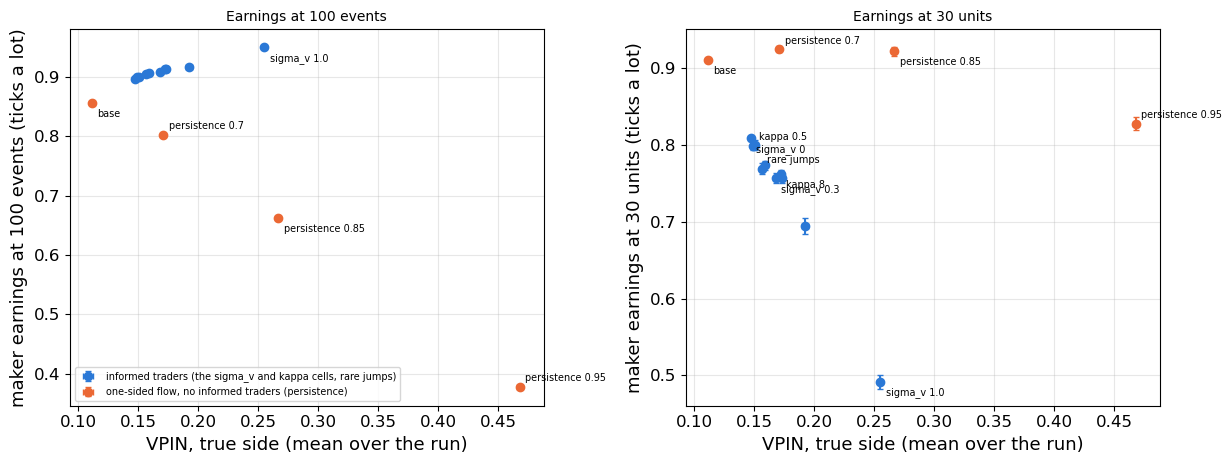

In [8]:
def values_of(cell, name, scale=1.0):
    return [r[name] * scale for r in toxicity[cell]]


def percentiles(cell):
    # the loss on informed fills at its 10th, 50th and 90th percentiles, each averaged over the runs
    means = [mean_se([r['loss quantiles'][i] for r in toxicity[cell]])[0] for i in range(3)]
    return ' / '.join(f'{m:.1f}' for m in means) if np.isfinite(means[1]) else '-'


measures = {
    cell: {
        'informed share': said(values_of(cell, 'informed share')),
        'VPIN, true side': said(values_of(cell, 'vpin true')),
        'VPIN, tick rule': said(values_of(cell, 'vpin tick')),
        'VPIN, bvc': said(values_of(cell, 'vpin bvc')),
        'loss against V on informed fills': said(values_of(cell, 'loss informed'), 2),
        'its 10th / 50th / 90th percentile': percentiles(cell),
    }
    for cell in CELLS
}
note(
    'Toxicity, by cell (mean over seeds, standard error across them). The loss against V on an informed fill is '
    'positive',
    'by construction (an informed order is sent only when V lies beyond the quote it hits): what has content is its '
    'size.',
)
display(pd.DataFrame(measures).T)

realized = {
    cell: {
        'informed fills, 30 units': said(values_of(cell, 'mark 30 units informed'), 2),
        'uninformed fills, 30 units': said(values_of(cell, 'mark 30 units uninformed'), 2),
        'informed fills, 100 events': said(values_of(cell, 'mark 100 events informed'), 2),
        'uninformed fills, 100 events': said(values_of(cell, 'mark 100 events uninformed'), 2),
        'maker earnings, 100 events': said(values_of(cell, 'mark 100 events all'), 3, -1),
        'maker earnings, 30 units': said(values_of(cell, 'mark 30 units all'), 3, -1),
    }
    for cell in CELLS
}
note(
    "\nRealized markouts, in ticks a lot: the maker's loss on a fill, the taker's side times the mid later less the "
    'price,',
    "by the taker's type; and what makers earned on all fills (the minus of the aggregate markout), at both horizons.",
)
display(pd.DataFrame(realized).T)

SWEEPS = {
    'sigma_v': ['sigma_v 0', 'sigma_v 0.1', 'sigma_v 0.3 (default)', 'sigma_v 0.5', 'sigma_v 1.0'],
    'kappa': ['kappa 0.5', 'kappa 1', 'sigma_v 0.3 (default)', 'kappa 4', 'kappa 8'],
}
dials = {}
for dial, cells in SWEEPS.items():
    for cell in cells:
        label = 'kappa 2 (default)' if dial == 'kappa' and cell == 'sigma_v 0.3 (default)' else cell
        dials[dial, label] = {
            'informed share': said(values_of(cell, 'informed share')),
            'loss against V on an informed fill': said(values_of(cell, 'loss informed'), 2),
            'maker earnings, 30 units': said(values_of(cell, 'mark 30 units all'), 3, -1),
        }
note(
    '\nWhich dial moves toxicity one way: kappa raises the informed share and lowers the loss on each informed fill '
    '(the',
    'book tracks V more closely), and sigma_v raises both. (Like for like in model, seeds and run length, not in the',
    'path of V: the same seed gives the same normals for V, but a different path once the events differ.)',
)
display(pd.DataFrame(dials).T)

level = {cell: np.mean(values_of(cell, 'vpin true')) for cell in CELLS}
informed_cells = [cell for cell in CELLS if cell.startswith(('sigma_v', 'kappa'))]
pairs = {}
for cell in ('persistence 0.7', 'persistence 0.85', 'persistence 0.95'):
    near = min(informed_cells, key=lambda other: abs(level[other] - level[cell]))
    if abs(level[near] - level[cell]) <= 0.02:
        for name, label in ((near, 'informed'), (cell, 'persistence')):
            pairs[cell, label, name] = {
                'VPIN, true side': said(values_of(name, 'vpin true')),
                'informed share': said(values_of(name, 'informed share')),
                'maker earnings, 100 events': said(values_of(name, 'mark 100 events all'), 3, -1),
                'maker earnings, 30 units': said(values_of(name, 'mark 30 units all'), 3, -1),
            }
note(
    '\nThe same VPIN, opposite earnings: each persistence cell (one-sided flow with nothing behind it) beside the '
    'informed',
    'cell whose VPIN is nearest (within 0.02), when there is one.',
)
display(pd.DataFrame(pairs).T)

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8), sharex=True)
families = (
    ('informed traders (the sigma_v and kappa cells, rare jumps)', BLUE, informed_cells + ['rare jumps']),
    (
        'one-sided flow, no informed traders (persistence)',
        ORANGE,
        ['base', 'persistence 0.7', 'persistence 0.85', 'persistence 0.95'],
    ),
)
LABELED = {
    'sigma_v 0',
    'sigma_v 0.3 (default)',
    'sigma_v 1.0',
    'kappa 0.5',
    'kappa 8',
    'rare jumps',
}  # the others lie among these
for ax, (name, horizon) in zip(
    axes, (('mark 100 events all', '100 events'), ('mark 30 units all', '30 units')), strict=True
):
    for title, color, cells in families:
        x = [np.mean(values_of(cell, 'vpin true')) for cell in cells]
        y = [-np.mean(values_of(cell, name)) for cell in cells]
        ax.errorbar(
            x,
            y,
            xerr=[mean_se(values_of(cell, 'vpin true'))[1] for cell in cells],
            yerr=[mean_se(values_of(cell, name))[1] for cell in cells],
            fmt='o',
            color=color,
            label=title,
            capsize=2,
        )
        for k, (cell, xi, yi) in enumerate(zip(cells, x, y, strict=True)):
            if color == ORANGE or cell in (LABELED if horizon == '30 units' else {'sigma_v 1.0'}):
                ax.annotate(
                    cell.replace(' (default)', ''),
                    (xi, yi),
                    fontsize=7,
                    xytext=(4, 4 if k % 2 else -10),
                    textcoords='offset points',
                )
    ax.set_xlabel('VPIN, true side (mean over the run)')
    ax.set_ylabel(f'maker earnings at {horizon} (ticks a lot)')
    ax.set_title(f'Earnings at {horizon}', fontsize=10)
axes[0].legend(fontsize=7)
plt.tight_layout()
plt.show()

In [9]:
def hac_ols(y, X, lags=N_BUCKETS):
    # OLS with Newey-West (Bartlett) standard errors; X holds the constant. Returns the coefficients and their errors.
    inverse = np.linalg.inv(X.T @ X)
    beta = inverse @ X.T @ y
    scores = X * (y - X @ beta)[:, None]
    middle = scores.T @ scores
    for lag in range(1, lags + 1):
        cross = scores[lag:].T @ scores[:-lag]
        middle += (1 - lag / (lags + 1)) * (cross + cross.T)
    return beta, np.sqrt(np.diag(inverse @ middle @ inverse))


def zscore(v):
    return (v - v.mean()) / v.std()


# columns of a run's `reg`: VPIN (true, tick) and imbalance of bucket b (true, tick), the mean of the last five buckets'
# imbalances (true, tick), then in bucket b + 1: the maker's loss at 30 units, at 100 events, the informed share, the
# loss vs V.
V_TRUE, V_TICK, OWN_TRUE, OWN_TICK, FIVE_TRUE, FIVE_TICK, Y_UNITS, Y_EVENTS, Y_INFORMED, Y_LOSS = range(10)


def within_run(cell, y_column):
    # Per run, standardized inside the run: y on VPIN and the bucket's own imbalance (two regressors), then with the
    # last five buckets' mean as a third. Coefficients in standard deviations of y per standard deviation of x.
    out = {
        name: [] for name in ('corr', 'vpin 2', 'own 2', 'vpin 3', 'own 3', 'five 3', 't vpin 3', 'vpin 3 tick', 'rows')
    }
    for r in toxicity[cell]:
        reg = r['reg']
        if len(reg) < 200 or not np.all(np.isfinite(reg[:, y_column])) or reg[:, y_column].std() == 0:
            continue
        y = zscore(reg[:, y_column])
        one = np.ones(len(reg))
        x = {
            name: zscore(reg[:, c])
            for name, c in (
                ('v', V_TRUE),
                ('o', OWN_TRUE),
                ('f', FIVE_TRUE),
                ('vk', V_TICK),
                ('ok', OWN_TICK),
                ('fk', FIVE_TICK),
            )
        }
        out['rows'].append(len(reg))
        out['corr'].append(correlation(y, x['v']))
        beta, _ = hac_ols(y, np.column_stack([one, x['v'], x['o']]))
        out['vpin 2'].append(beta[1])
        out['own 2'].append(beta[2])
        beta, error = hac_ols(y, np.column_stack([one, x['v'], x['o'], x['f']]))
        out['vpin 3'].append(beta[1])
        out['own 3'].append(beta[2])
        out['five 3'].append(beta[3])
        out['t vpin 3'].append(beta[1] / error[1])
        beta, _ = hac_ols(y, np.column_stack([one, x['vk'], x['ok'], x['fk']]))
        out['vpin 3 tick'].append(beta[1])
    return out


REGRESSION_CELLS = [
    'base',
    'sigma_v 0.3 (default)',
    'sigma_v 0.5',
    'sigma_v 1.0',
    'rare jumps',
    'persistence 0.7',
    'persistence 0.85',
    'persistence 0.95',
]
for title, column in (
    ("the maker's loss at 30 units a lot", Y_UNITS),
    ("the informed share of the next bucket's lots (the truth)", Y_INFORMED),
):
    cells = [cell for cell in REGRESSION_CELLS if column == Y_UNITS or toxicity[cell][0]['lots informed'] > 0]
    fits_by_cell = {cell: within_run(cell, column) for cell in cells}
    table = {
        cell: {
            'bucket pairs a run': f'{np.mean(f["rows"]):,.0f}',
            'corr(y, VPIN)': said(f['corr'], 3),
            "VPIN, with the bucket's own imbalance": said(f['vpin 2'], 3),
            "VPIN, and the last five buckets' mean": said(f['vpin 3'], 3),
            "the bucket's own imbalance": said(f['own 3'], 3),
            "the last five buckets' mean": said(f['five 3'], 3),
            'VPIN, tick side': said(f['vpin 3 tick'], 3),
            'mean HAC t of VPIN': f'{np.mean(f["t vpin 3"]):+.1f}',
        }
        for cell, f in fits_by_cell.items()
    }
    note(
        f'\nWithin a run, y = {title} in bucket b + 1 (standardized inside each run; mean over seeds, standard error '
        'across',
        'them; Newey-West errors, 50 buckets): the partial coefficient of VPIN at the end of bucket b, beside the',
        "bucket's own one-sidedness and the mean of the last five buckets'.",
    )
    display(pd.DataFrame(table).T)
    if column == Y_UNITS:
        within = fits_by_cell


Within a run, y = the maker's loss at 30 units a lot in bucket b + 1 (standardized inside each run; mean over seeds,
standard error across them; Newey-West errors, 50 buckets): the partial coefficient of VPIN at the end of bucket b,
beside the bucket's own one-sidedness and the mean of the last five buckets'.


,bucket pairs a run,"corr(y, VPIN)","VPIN, with the bucket's own imbalance","VPIN, and the last five buckets' mean",the bucket's own imbalance,the last five buckets' mean,"VPIN, tick side",mean HAC t of VPIN
base,"2,344",-0.004 (0.007),-0.007 (0.006),-0.006 (0.007),0.017 (0.010),0.001 (0.014),-0.002 (0.006),-0.2
sigma_v 0.3 (default),"2,790",0.079 (0.006),0.045 (0.005),0.009 (0.006),0.108 (0.011),0.143 (0.015),0.016 (0.007),+0.2
sigma_v 0.5,"2,894",0.094 (0.012),0.057 (0.011),0.016 (0.008),0.113 (0.009),0.155 (0.015),0.019 (0.010),+0.4
sigma_v 1.0,"3,178",0.105 (0.014),0.076 (0.014),0.036 (0.014),0.081 (0.007),0.152 (0.008),0.046 (0.014),+1.0
rare jumps,"2,744",0.092 (0.019),0.053 (0.017),0.018 (0.015),0.136 (0.009),0.142 (0.011),0.026 (0.016),+0.5
persistence 0.7,"2,344",-0.010 (0.006),-0.015 (0.006),-0.016 (0.007),0.029 (0.009),0.004 (0.010),-0.028 (0.006),-0.7
persistence 0.85,"2,344",-0.014 (0.008),-0.018 (0.008),-0.020 (0.009),0.029 (0.012),0.009 (0.007),-0.025 (0.010),-1.1
persistence 0.95,"2,344",0.011 (0.008),0.006 (0.008),0.002 (0.007),0.028 (0.011),0.014 (0.011),-0.002 (0.007),+0.1



Within a run, y = the informed share of the next bucket's lots (the truth) in bucket b + 1 (standardized inside each
run; mean over seeds, standard error across them; Newey-West errors, 50 buckets): the partial coefficient of VPIN at the
end of bucket b, beside the bucket's own one-sidedness and the mean of the last five buckets'.


,bucket pairs a run,"corr(y, VPIN)","VPIN, with the bucket's own imbalance","VPIN, and the last five buckets' mean",the bucket's own imbalance,the last five buckets' mean,"VPIN, tick side",mean HAC t of VPIN
sigma_v 0.3 (default),"2,790",0.135 (0.016),0.071 (0.014),0.013 (0.012),0.225 (0.011),0.227 (0.009),0.018 (0.012),+0.6
sigma_v 0.5,"2,894",0.146 (0.007),0.076 (0.007),0.015 (0.008),0.243 (0.009),0.234 (0.012),0.022 (0.006),+0.6
sigma_v 1.0,"3,178",0.144 (0.013),0.087 (0.011),0.028 (0.010),0.201 (0.007),0.219 (0.010),0.042 (0.013),+1.1
rare jumps,"2,744",0.137 (0.021),0.066 (0.017),-0.003 (0.015),0.237 (0.006),0.279 (0.014),0.012 (0.017),-0.2


rare jumps: 100 jumps of V a run, 771 studied in 8 runs, 444 of them isolated.
sigma_v 0.3 (default): 995 jumps of V a run, 7723 studied in 8 runs, 14 of them isolated.

rare jumps, isolated jumps, by bucket around the jump (0 is the bucket open at it):


,-1,0,1,2,3,5,8,10
"change in trailing VPIN, true side",0.000,0.0011,0.0043,0.0068,0.0090,0.0117,0.0132,0.0131
"change in trailing VPIN, tick rule",0.000,0.0007,0.0029,0.0047,0.0060,0.0080,0.0090,0.0088
"the bucket's own |buy - sell| / V, true",0.138,0.2008,0.3124,0.2793,0.2645,0.2147,0.1653,0.1454
true buy share in the jump's direction,0.495,0.5799,0.6545,0.6346,0.6257,0.5946,0.5555,0.5420


The mid moved half the jump after a median 10.2 units (quartiles 5.1 and 18.2): within the jump's own bucket for 13% of the jumps, by the next bucket 43%, by the third 79%.


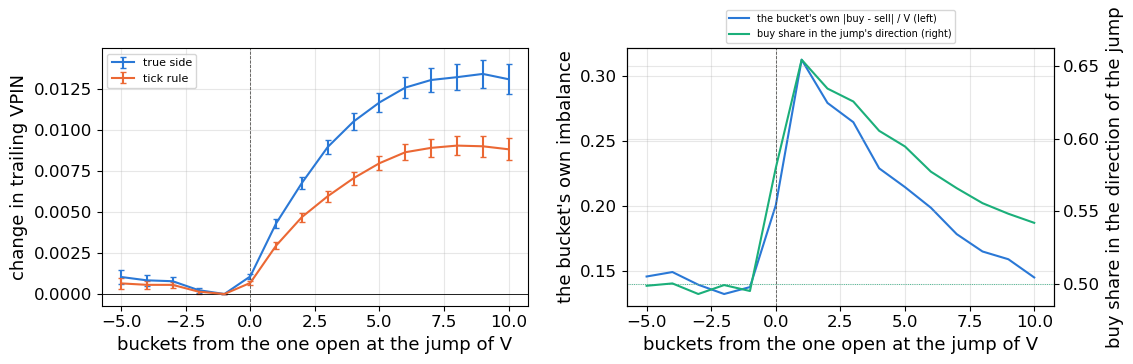

In [10]:
def jump_pool(cell):
    # the studied jumps of a cell from every run: for each key an array with a row a jump, and the jumps logged
    runs = [r['jumps'] for r in toxicity[cell] if len(r['jumps']['iso'])]
    if not runs:
        return None, 0
    pool = {key: np.concatenate([j[key] for j in runs]) for key in runs[0] if key != 'logged'}
    return pool, sum(j['logged'] for j in runs)


jump_table, jump_lags = {}, {}
for cell in JUMP_CELLS:
    pool, logged = jump_pool(cell)
    if pool is None:
        continue
    isolated = pool['iso'] > 0
    print(
        f'{cell}: {logged / len(toxicity[cell]):,.0f} jumps of V a run, {len(isolated)} studied in '
        f'{len(toxicity[cell])} runs, {int(isolated.sum())} of them isolated.'
    )
    if isolated.sum() < 20:
        continue
    pick = {key: value[isolated] for key, value in pool.items()}
    jump_table[cell] = {
        'change in trailing VPIN, true side': pick['vpin true'].mean(axis=0),
        'change in trailing VPIN, tick rule': pick['vpin tick'].mean(axis=0),
        "the bucket's own |buy - sell| / V, true": pick['imbalance true'].mean(axis=0),
        "true buy share in the jump's direction": pick['buy share'].mean(axis=0),
    }
    jump_lags[cell] = pick

SHOWN_OFFSETS = (-1, 0, 1, 2, 3, 5, 8, 10)
for cell, columns in jump_table.items():
    frame = pd.DataFrame(columns, index=OFFSETS).T[list(SHOWN_OFFSETS)]
    print(f'\n{cell}, isolated jumps, by bucket around the jump (0 is the bucket open at it):')
    display(frame.round(4))
    lag, bucket_lag = jump_lags[cell]['lag units'], jump_lags[cell]['lag buckets']
    reached = bucket_lag[np.isfinite(bucket_lag)]
    print(
        f'The mid moved half the jump after a median {np.nanmedian(lag):.1f} units (quartiles '
        f'{np.nanpercentile(lag, 25):.1f} and {np.nanpercentile(lag, 75):.1f}): within the '
        f"jump's own bucket for {np.mean(reached <= 0):.0%} of the jumps, by the next bucket "
        f'{np.mean(reached <= 1):.0%}, by the third {np.mean(reached <= 3):.0%}.'
    )

if 'rare jumps' in jump_table:
    fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.8))
    table, pick = jump_table['rare jumps'], jump_lags['rare jumps']
    for name, key, color in (('true side', 'vpin true', BLUE), ('tick rule', 'vpin tick', ORANGE)):
        axes[0].errorbar(
            OFFSETS,
            pick[key].mean(axis=0),
            yerr=pick[key].std(axis=0, ddof=1) / math.sqrt(len(pick[key])),
            color=color,
            label=name,
            capsize=2,
        )
    axes[0].axhline(0, color='black', linewidth=0.6)
    axes[0].set_ylabel('change in trailing VPIN')
    axes[0].legend(fontsize=8)
    own, share = "the bucket's own |buy - sell| / V, true", "true buy share in the jump's direction"
    line = axes[1].plot(OFFSETS, table[own], color=BLUE, label="the bucket's own |buy - sell| / V (left)")
    ax2 = axes[1].twinx()
    line += ax2.plot(OFFSETS, table[share], color=AQUA, label="buy share in the jump's direction (right)")
    ax2.axhline(0.5, color=AQUA, linewidth=0.6, linestyle=':')
    axes[1].set_ylabel("the bucket's own imbalance")
    ax2.set_ylabel('buy share in the direction of the jump')
    axes[1].legend(line, [x.get_label() for x in line], fontsize=7, loc='lower center', bbox_to_anchor=(0.5, 1.0))
    for ax in axes:
        ax.axvline(0, color=GRAY, linewidth=0.6, linestyle='--')
        ax.set_xlabel('buckets from the one open at the jump of V')
    plt.tight_layout()
    plt.show()

The comparison is VPIN against toxicity as the informed model defines it, over 14 cells (the informed model's dials, and one-sided uninformed flow with no informed traders) on 8 seeds of 20,000 units each (112 runs, none of which took V to its floor). The truth per fill is the maker's loss against V; realized markouts are at 100 events, which sees the transient impact of a fill, and at 30 units, which sees what is left of it. The sweeps are like for like in model, seeds and run length and not in the path of V (the same seed gives the same normals for V, but a different path once the events differ).

**An informed fill costs the maker against V by construction, and the makers still earn.** That the loss is positive is the rule (an informed order is sent only when V lies beyond the quote it hits); what has content is its size, 2.19 ticks a lot (se 0.03) at the defaults with a 10th, 50th and 90th percentile of 0.6, 1.8 and 4.3, and what the maker goes on to earn. The informed share is 0.155 (se 0.001) and VPIN 0.168 (se 0.001) (tick rule 0.129, BVC 0.493). Realized, the maker's loss on an informed fill is 1.03 (se 0.02) ticks a lot at 30 units and -0.28 (se 0.01) at 100 events, where it still earns; uninformed fills earn it 1.09 (se 0.00) at 30 units. Over all fills the makers earn 0.757 (se 0.006) at 30 units, against 0.910 (se 0.002) with no informed traders (kappa 0). They earn in every cell: the least is 0.492 (se 0.009) at 30 units (`sigma_v` 1.0) and 0.377 (se 0.003) at 100 events (persistence 0.95), with informed shares up to 0.257 (se 0.001).

**The informed share does not fix the earnings: the dials move toxicity differently.** Raising `kappa` from 0.5 to 8 raises the share from 0.112 (se 0.002) to 0.180 (se 0.001) and lowers the loss on an informed fill from 3.45 (se 0.07) to 1.68 (se 0.02), as the book tracks V more closely, and earnings at 30 units are 0.798, 0.773, 0.757, 0.756 and 0.762 (se 0.005 to 0.006) at `kappa` 0.5, 1, 2, 4 and 8: flat from 2. Raising `sigma_v` from 0 to 1.0 raises both, the share from 0.123 (se 0.001) to 0.257 (se 0.001) and the loss from 2.01 (se 0.02) to 6.04 (se 0.22), and earnings fall from 0.808 (se 0.003) to 0.492 (se 0.009). `sigma_v` 0 has informed traders too: the model's jumps alone make 0.123 of the lots informed.

**VPIN rises with one-sided flow whether or not anything is behind it.** True-side VPIN measures one-sidedness, so it rises in both sweeps by construction: 0.111 (se 0.001) in the base cell, 0.147 to 0.255 across the `sigma_v` cells, and 0.171, 0.266 and 0.468 (se 0.001 to 0.002) at persistence 0.7, 0.85 and 0.95, where no order is informed. The same VPIN earns opposite amounts. `kappa` 8 (VPIN 0.172 (se 0.001)) earns 0.762 (se 0.006) at 30 units and persistence 0.7 (0.171 (se 0.001)) earns 0.924 (se 0.004); `sigma_v` 1.0 (0.255 (se 0.001)) earns 0.492 (se 0.009) and persistence 0.85 (0.266 (se 0.001)) earns 0.921 (se 0.006). The horizon matters: at 100 events it is persistent flow that costs the makers, 0.803 (se 0.002), 0.663 (se 0.001) and 0.377 (se 0.003) at persistence 0.7, 0.85 and 0.95 against 0.856 (se 0.002) in the base cell, while the informed cells earn 0.897 to 0.950. At 30 units persistence 0.7 and 0.85 are back at 0.924 and 0.921, and 0.95 at 0.827 (se 0.008).

**Within a run, VPIN predicts the next bucket's loss mostly through the recent one-sidedness it averages.** With each run standardized, the partial coefficient of VPIN at the end of bucket b on the maker's loss at 30 units in bucket b + 1, beside the bucket's own imbalance, is 0.045 (se 0.005) at the default, 0.057 (se 0.011) at `sigma_v` 0.5, 0.076 (se 0.014) at 1.0 and 0.053 (se 0.017) with rare jumps. Adding the mean of the last five buckets' imbalances takes it to 0.009 (se 0.006), 0.016 (se 0.008), 0.036 (se 0.014) and 0.018 (se 0.015), while the five-bucket mean has 0.143 (se 0.015), 0.155 (se 0.015), 0.152 (se 0.008) and 0.142 (se 0.011); the mean Newey-West t of VPIN is +0.2, +0.4, +1.0 and +0.5. Beside the five-bucket mean the coefficient is about 0 at the default and 53 to 72% lower in the other three, but at `sigma_v` 1.0 it stays at 0.036 (se 0.014), 2.6 standard errors from 0 (the mean Newey-West t of +1.0 is a different statistic, within a run, and does not offset that). In the base and persistence cells every coefficient is within 0.03 of 0.

**The same holds for the truth at the default: beyond the last five buckets, VPIN adds almost nothing to the informed share of the next bucket's lots.** VPIN's partial on it falls from 0.071 (se 0.014) to 0.013 (se 0.012) at the default once the five-bucket mean is added, and the mean has 0.227 (se 0.009); at `sigma_v` 1.0 it falls from 0.087 (se 0.011) to 0.028 (se 0.010), which is 2.8 standard errors from 0. What VPIN carries is the persistence of the informed regime over a few buckets, which a shorter trailing mean carries better than its 50 buckets.

**VPIN cannot lead a jump of V, and after one it rises slowly.** By construction nothing in the book carries V before the first informed order after a jump, so the question with content is how long after it VPIN rises, against how long the mid takes to move. In the rare-jumps cell (jumps of 6 ticks at a rate of 0.005 a unit, 100 a run), 444 of 771 studied jumps in 8 runs are isolated (no other jump from 6 buckets before to 11 after). Trailing VPIN, measured from the bucket before the jump (zero by construction), is up +0.0011 in the jump's own bucket, +0.0043 one bucket after, +0.0068 two after and +0.0132 eight after (the tick rule's: +0.0007, +0.0029, +0.0047 and +0.0090). The bucket's own imbalance goes from 0.138 before the jump to 0.2008 in it and 0.3124 a bucket after, and the true buy share in the jump's direction from 0.495 to 0.5799 and 0.6545: the flow reacts, and a window of 50 buckets averages that into a small rise. At the defaults jumps come too often to isolate: 995 a run, and 14 of 7,723 studied are isolated.

**The mid is ahead of VPIN.** It has moved half the jump after a median 10.2 units (quartiles 5.1 and 18.2): within the jump's own bucket for 13% of the jumps, by the next bucket 43% and by the third 79%, while trailing VPIN keeps rising to about eight buckets after.

**VisualHFT's research asks a different question of VPIN, so the two results are not comparable.** R-002 finds that adding VPIN to a HAR-RV forecast of 5-minute volatility did not improve it (QLIKE worse, Diebold-Mariano p 0.72 to 0.89): VPIN did not improve a baseline of past realized volatility. Here the target is the maker's loss and the baseline is recent order flow, not past volatility: VPIN's coefficient is small and positive beside one bucket's imbalance (0.045 (se 0.005) at the default) and shrinks to 0.009 (se 0.006) once the five-bucket mean is in the regression. The two are not like for like, and that shrinkage is this notebook's finding and not R-002's.

## 5. How Fast the Book Refills

In [11]:
RESILIENCE_UNITS = 4_000  # units of simulation time a run, after the warm-up
RESILIENCE_MODELS = [*MODELS, 'mike_farmer']  # the simplified model's touch queues are too deep for a depletion
ROW = ('side', 'start', 'depth0', 'baseline', 'recovered', 'duration', 'arrived', 'canceled', 'taken', 'depth1')


class RestorationLog(deque):
    # The study's last restoration times, which also notes each one with the time at which it was restored.
    def __init__(self, study, maxlen):
        super().__init__(maxlen=maxlen)
        self.study = study

    def append(self, x):
        self.study.restoration_log.append((self.study._t, x))
        super().append(x)


class Episodes(Resilience):
    # The library's Resilience, noting each episode as it starts and ends, and the lots that arrived at, were canceled
    # at and were taken from its K anchored prices while it was open: arrivals less cancels less takes is the change in
    # the depth there, to the lot. It reaches into the study's own methods for where an episode starts and ends, and
    # logs the times at which a quote was restored (the study keeps the last 20).
    def _clear(self):
        super()._clear()
        self.episodes = []
        self.open = [None, None]  # the open episode of each side
        self.restoration_log = []  # (time, units to restore) of every restored quote-moving take
        self._restorations = RestorationLog(self, self._restorations.maxlen)

    def _maybe_start(self, t, s, best, after, book, fills=(), canceled=0):
        started = self.started
        super()._maybe_start(t, s, best, after, book, fills, canceled)
        if self.started > started:
            depth = self._near(book, s, best)
            row = dict(
                side=s,
                start=t,
                anchor=best,
                depth0=depth,
                baseline=self._baseline[s],
                arrived=0,
                canceled=0,
                taken=0,
                recovered=np.nan,
                duration=np.nan,
                depth1=np.nan,
            )
            if self._episode[s] is None:  # the quote had moved away already: abandoned at once
                row.update(recovered=0.0, duration=0.0, depth1=depth)
            else:
                self.open[s] = row
            self.episodes.append(row)

    def _follow(self, t, s, best, book, near=True):
        row, recovered = self.open[s], self.recovered_n
        super()._follow(t, s, best, book, near)
        if row is not None and self._episode[s] is None:
            row.update(
                recovered=float(self.recovered_n > recovered),
                duration=t - row['start'],
                depth1=self._near(book, s, row['anchor']),
            )
            self.open[s] = None

    def observe(self, t, kind, side, price, size, fills, aggressor, before, after, book, own=False):
        for s, row in enumerate(self.open):
            if row is not None:
                anchor, step = row['anchor'], book.tick_size
                low, high = (
                    (anchor - (self.ticks - 1) * step, anchor) if s == 0 else (anchor, anchor + (self.ticks - 1) * step)
                )
                if (side == Side.BID) == (s == 0) and low <= price <= high:
                    if kind == ARRIVAL_LIMIT:
                        row['arrived'] += size - sum(
                            fill.size for fill in fills
                        )  # an order that crossed rests with the rest
                    elif kind == CANCEL:
                        row['canceled'] += size
                if fills and aggressor == (-1 if s == 0 else 1):
                    row['taken'] += sum(fill.size for fill in fills if low <= fill.price <= high)
        super().observe(t, kind, side, price, size, fills, aggressor, before, after, book, own)


class Shifting:
    # The definition of depletion that the study's anchoring replaces: the depth at the K prices from the side's CURRENT
    # best quote below q times its baseline starts an episode, back at r times it ends one. Counts what starts each and
    # why.
    def __init__(self, reference, q=0.5, r=0.9):
        self.reference, self.q, self.r = reference, q, r
        self.open = [None, None]
        self.starts = 0
        self.causes = dict.fromkeys(('quote-improving arrival', 'take', 'cancel', 'other'), 0)
        self.durations = []

    def observe(self, warm, t, kind, side, price, size, fills, aggressor, before, after, book, own=False):
        if warm:
            return
        for s in (0, 1):
            baseline, best = self.reference._baseline[s], after[2 * s]
            if baseline is None or best is None:
                continue
            depth = self.reference._near(book, s, best)
            if self.open[s] is None:
                if depth < self.q * baseline:
                    self.open[s] = t
                    self.starts += 1
                    old = before[2 * s]
                    improved = old is not None and (best > old if s == 0 else best < old)
                    cause = (
                        'quote-improving arrival'
                        if improved and kind == ARRIVAL_LIMIT
                        else ('take' if fills else 'cancel' if kind == CANCEL else 'other')
                    )
                    self.causes[cause] += 1
            elif depth >= self.r * baseline:
                self.durations.append(t - self.open[s])
                self.open[s] = None


class ResilienceCollector:
    def __init__(self):
        self.studies = {onset: Episodes(onset=onset) for onset in ('below', 'crossing')}
        self.shifting = Shifting(self.studies['below'])
        self.unit, self.began, self.t_warm, self.t_end = 0, False, 0.0, 0.0
        self.snapshot = {}

    def on_pre(self, warm, t, book):
        if not warm and not self.began:
            self.began = True
            self.snapshot = {k: (s.quote_moves, s.restored, s.unrestored) for k, s in self.studies.items()}
        while self.unit < int(t):
            self.unit += 1
            for study in self.studies.values():
                study.sample(self.unit, book)

    def observe(self, warm, t, kind, side, price, size, fills, aggressor, before, after, book, own=False):
        if warm:
            self.t_warm = t
        self.t_end = t
        for study in self.studies.values():
            study.observe(t, kind, side, price, size, fills, aggressor, before, after, book, own)
        self.shifting.observe(warm, t, kind, side, price, size, fills, aggressor, before, after, book, own)


def resilience_run(key, seed):
    collector = ResilienceCollector()
    simulate(make_model(key), key, seed, RESILIENCE_UNITS, [collector.observe], collector.on_pre)
    out = {'units': collector.t_end - collector.t_warm}
    for onset, study in collector.studies.items():
        episodes = [r for r in study.episodes if r['start'] > collector.t_warm]
        moves, restored, unrestored = (
            a - b
            for a, b in zip(
                (study.quote_moves, study.restored, study.unrestored), collector.snapshot[onset], strict=True
            )
        )
        out[onset] = {
            'episodes': np.array([[r[name] for name in ROW] for r in episodes], dtype=float).reshape(-1, len(ROW)),
            'quote moves': moves,
            'restored': restored,
            'unrestored': unrestored,
            'restoration': np.array([x for when, x in study.restoration_log if when > collector.t_warm], dtype=float),
        }
    shifting = collector.shifting
    out['shifting'] = {'starts': shifting.starts, 'causes': shifting.causes, 'durations': np.array(shifting.durations)}
    below = collector.studies['below']
    out['baseline'] = (
        np.mean([b for b in below._baseline if b is not None])
        if any(b is not None for b in below._baseline)
        else np.nan
    )
    return key, seed, out


resilience_runs = Parallel(n_jobs=N_JOBS)(
    delayed(resilience_run)(key, seed) for key in RESILIENCE_MODELS for seed in FEW
)
resilience = {key: [r[2] for r in resilience_runs if r[0] == key] for key in RESILIENCE_MODELS}

In [12]:
STUDY = Resilience()  # the dashboard's settings: K prices, depleted below q and recovered at r of the baseline
ZI_FAMILY = ('smith_zi', 'hawkes_zi', 'informed_zi')  # limit orders arrive at lam a tick, in lots, whatever the book
IX = {name: i for i, name in enumerate(ROW)}
MIN_EPISODES = 10  # a model with fewer depletions over all its runs has no episodes worth summarizing


def episode_metrics(run, onset):
    data, units = run[onset], run['units']
    episodes = data['episodes']
    ended = episodes[np.isfinite(episodes[:, IX['recovered']])]
    done = ended[ended[:, IX['recovered']] == 1]
    timed = done[done[:, IX['duration']] > 0]
    deficit = STUDY.recovered * done[:, IX['baseline']] - done[:, IX['depth0']]
    both = data['restored'] + data['unrestored']
    net_rates = (timed[:, IX['arrived']] - timed[:, IX['canceled']] - timed[:, IX['taken']]) / timed[:, IX['duration']]
    seconds = timed[:, IX['duration']].sum()
    flows = {
        name: timed[:, IX[name]].sum() / seconds if seconds else np.nan for name in ('arrived', 'taken', 'canceled')
    }
    return {
        'episodes': len(episodes),
        'started a unit': len(episodes) / units,
        'recovered share': len(done) / len(ended) if len(ended) else np.nan,
        'abandoned share': 1 - len(done) / len(ended) if len(ended) else np.nan,
        'median recovery': np.median(done[:, IX['duration']]) if len(done) else np.nan,
        'p90 recovery': np.percentile(done[:, IX['duration']], 90) if len(done) else np.nan,
        'quote-moving takes a unit': data['quote moves'] / units,
        'restored share': data['restored'] / both if both else np.nan,
        'median restoration': np.median(data['restoration']) if len(data['restoration']) else np.nan,
        'median deficit': np.median(deficit) if len(done) else np.nan,
        'median gain': np.median(done[:, IX['depth1']] - done[:, IX['depth0']]) if len(done) else np.nan,
        'median net rate': np.median(net_rates) if len(timed) else np.nan,
        # every ended episode, recovered or abandoned
        'identity': np.abs(
            ended[:, IX['arrived']]
            - ended[:, IX['canceled']]
            - ended[:, IX['taken']]
            - (ended[:, IX['depth1']] - ended[:, IX['depth0']])
        ).max()
        if len(ended)
        else np.nan,
        **flows,
        'net': flows['arrived'] - flows['taken'] - flows['canceled'],
        'baseline': run['baseline'],
    }


metrics = {
    (key, onset): pd.DataFrame([episode_metrics(run, onset) for run in resilience[key]])
    for key in RESILIENCE_MODELS
    for onset in ('below', 'crossing')
}


def depleted(key):
    # whether the model's runs, together, hold enough depletions to summarize
    return metrics[key, 'below']['episodes'].sum() >= MIN_EPISODES


table = {}
for key in RESILIENCE_MODELS:
    below, crossing = metrics[key, 'below'], metrics[key, 'crossing']
    if not depleted(key):
        table[NAMES[key]] = {
            'baseline depth (lots)': said(below['baseline'], 0),
            'episodes a unit': f'{below["episodes"].sum():.0f} in all, too few to summarize',
        }
        continue
    table[NAMES[key]] = {
        'baseline depth (lots)': said(below['baseline'], 0),
        'episodes a unit': said(below['started a unit']),
        'recovered share': said(below['recovered share'], 2),
        'median recovery (units)': said(below['median recovery'], 1),
        '90th percentile': said(below['p90 recovery'], 1),
        'quote-moving takes a unit': said(below['quote-moving takes a unit'], 2),
        f'restored within {STUDY.restore_window:g} units': said(below['restored share'], 3),
        'median restoration (units)': said(below['median restoration'], 2),
        'crossing: episodes a unit': said(crossing['started a unit']),
        'crossing: recovered share': said(crossing['recovered share'], 2),
        'crossing: median recovery': said(crossing['median recovery'], 1),
    }
note(
    f'Depth recovery after a depletion (K = {STUDY.ticks} prices from the touch, depleted below {STUDY.depleted:g} and',
    f'recovered at {STUDY.recovered:g} of the baseline), episodes anchored where they began. The onset is "below the '
    'line"',
    'as the dashboard starts them, beside the "crossing" onset. Large\'s restoration: of the takes that moved the '
    'quote, the share',
    'that a limit order put back within the window, and after how long (mean over seeds, standard error across them).',
)
display(pd.DataFrame(table).T.fillna('-'))

shifting, shift_stats = {}, {}
for key in RESILIENCE_MODELS:
    if not depleted(key):
        continue
    starts = [run['shifting']['starts'] / run['units'] for run in resilience[key]]
    improving = [
        run['shifting']['causes']['quote-improving arrival'] / max(run['shifting']['starts'], 1)
        for run in resilience[key]
    ]
    shift_stats[key] = {'starts': starts, 'improving': improving}
    durations = [
        np.median(run['shifting']['durations']) if len(run['shifting']['durations']) else np.nan
        for run in resilience[key]
    ]
    shifting[NAMES[key]] = {
        'shifting-window episodes a unit': said(starts, 3),
        'anchored episodes a unit': said(metrics[key, 'below']['started a unit'], 3),
        'times as many': f'{np.mean(starts) / metrics[key, "below"]["started a unit"].mean():.1f}',
        'started by a quote-improving arrival': said(improving, 3),
        'median duration (units)': said(durations, 2),
    }
note(
    "\nThe definition the anchoring replaces: the depth measured from the side's current best quote, so that a limit "
    'order that',
    'improves the quote reads as a thin touch. How many episodes it invents, and what starts them:',
)
display(pd.DataFrame(shifting).T)


def identity(key):
    # the largest gap in arrivals - cancels - takes - change in depth, over every ended episode of both onsets
    return np.nanmax([metrics[key, onset]['identity'].max() for onset in ('below', 'crossing')])


refill = {}
for key in RESILIENCE_MODELS:
    m = metrics[key, 'below']
    if not depleted(key):
        continue
    params = PARAMS[key]
    gross = params['lot_size'] * params['lam'] * STUDY.ticks if key in ZI_FAMILY else None
    row = {
        'median deficit D (lots)': said(m['median deficit'], 0),
        'median depth gained (lots)': said(m['median gain'], 0),
        'measured median recovery (units)': said(m['median recovery'], 1),
        'D over the gross refill (a lower bound)': said(m['median deficit'] / gross, 1) if gross else '-',
        'arrivals a unit': said(m['arrived'], 1),
        'takes a unit': said(m['taken'], 1),
        'cancels a unit': said(m['canceled'], 1),
        'net a unit': said(m['net'], 1),
        'median net rate (units a unit)': said(m['median net rate'], 2),
        'D over the median net rate (units)': said(m['median deficit'] / m['median net rate'], 1),
        'depth gained over the median net rate (units)': said(m['median gain'] / m['median net rate'], 1),
        'largest |arrivals - cancels - takes - change in depth|': f'{identity(key):.0f}',
    }
    refill[NAMES[key]] = row
gross_rate = PARAMS['smith_zi']['lot_size'] * PARAMS['smith_zi']['lam'] * STUDY.ticks
note(
    '\nHow fast depth comes back, in the recovered episodes. In the ZI family limit orders arrive at lambda a tick, '
    'in lots of',
    f'{PARAMS["smith_zi"]["lot_size"]}: {gross_rate:g} lots a unit across the K = {STUDY.ticks} anchored prices, which '
    f'would refill a deficit D in D / {gross_rate:g}',
    'units if nothing were taken or canceled. Per unit of episode time, the lots that arrived at, were taken from and '
    'were',
    'canceled at the anchored prices while an episode was open (pooled over its recovered episodes, so the long ones '
    'weigh most)',
    "make the net rate. The measured median is set against medians: D, the median deficit, over the median of the "
    "episodes' own",
    'net rates, and the median depth actually gained over it. The gain is smaller than D because D is measured against '
    'the baseline',
    'when the episode began and the baseline, a rolling median, can move while it is open; an episode ends at 0.9 of '
    'the baseline of',
    'the time. The last column checks the identity on every ended episode, recovered or abandoned, in both onsets.',
)
display(pd.DataFrame(refill).T)

Depth recovery after a depletion (K = 3 prices from the touch, depleted below 0.5 and recovered at 0.9 of the baseline),
episodes anchored where they began. The onset is "below the line" as the dashboard starts them, beside the "crossing"
onset. Large's restoration: of the takes that moved the quote, the share that a limit order put back within the window,
and after how long (mean over seeds, standard error across them).


,baseline depth (lots),episodes a unit,recovered share,median recovery (units),90th percentile,quote-moving takes a unit,restored within 30 units,median restoration (units),crossing: episodes a unit,crossing: recovered share,crossing: median recovery
ZI,190 (9),0.048 (0.001),0.41 (0.01),32.0 (1.4),91.8 (4.5),2.09 (0.01),0.984 (0.000),0.58 (0.00),0.029 (0.001),0.67 (0.02),17.1 (0.8)
Hawkes ZI,220 (18),0.091 (0.008),0.23 (0.02),24.4 (1.1),65.0 (4.7),1.95 (0.05),0.979 (0.001),0.50 (0.00),0.028 (0.001),0.55 (0.02),14.1 (1.2)
MF 2008,155 (11),0.041 (0.001),0.54 (0.01),24.6 (1.7),82.8 (4.5),0.76 (0.01),0.940 (0.001),1.71 (0.02),0.023 (0.001),0.66 (0.01),17.4 (0.4)
Parlour,34 (2),0.639 (0.006),0.07 (0.00),2.6 (0.1),7.4 (0.4),2.71 (0.01),0.974 (0.001),0.79 (0.01),0.245 (0.004),0.17 (0.00),2.1 (0.1)
Informed ZI,202 (8),0.083 (0.002),0.33 (0.01),18.6 (0.6),58.1 (2.2),2.75 (0.02),0.983 (0.000),0.51 (0.00),0.040 (0.001),0.63 (0.01),10.5 (0.4)
MF simplified,1515 (27),"3 in all, too few to summarize",-,-,-,-,-,-,-,-,-



The definition the anchoring replaces: the depth measured from the side's current best quote, so that a limit order that
improves the quote reads as a thin touch. How many episodes it invents, and what starts them:


,shifting-window episodes a unit,anchored episodes a unit,times as many,started by a quote-improving arrival,median duration (units)
ZI,0.692 (0.006),0.048 (0.001),14.3,0.996 (0.000),0.35 (0.00)
Hawkes ZI,0.635 (0.017),0.091 (0.008),7.0,0.996 (0.001),0.23 (0.01)
MF 2008,0.217 (0.004),0.041 (0.001),5.3,0.993 (0.001),0.99 (0.02)
Parlour,0.803 (0.007),0.639 (0.006),1.3,0.980 (0.001),0.38 (0.01)
Informed ZI,0.930 (0.009),0.083 (0.002),11.2,0.997 (0.000),0.24 (0.00)



How fast depth comes back, in the recovered episodes. In the ZI family limit orders arrive at lambda a tick, in lots of
5: 15 lots a unit across the K = 3 anchored prices, which would refill a deficit D in D / 15 units if nothing were taken
or canceled. Per unit of episode time, the lots that arrived at, were taken from and were canceled at the anchored
prices while an episode was open (pooled over its recovered episodes, so the long ones weigh most) make the net rate.
The measured median is set against medians: D, the median deficit, over the median of the episodes' own net rates, and
the median depth actually gained over it. The gain is smaller than D because D is measured against the baseline when the
episode began and the baseline, a rolling median, can move while it is open; an episode ends at 0.9 of the baseline of
the time. The last column checks the identity on every ended episode, recovered or abandoned, in both onsets.


,median deficit D (lots),median depth gained (lots),measured median recovery (units),D over the gross refill (a lower bound),arrivals a unit,takes a unit,cancels a unit,net a unit,median net rate (units a unit),D over the median net rate (units),depth gained over the median net rate (units),largest |arrivals - cancels - takes - change in depth|
ZI,109 (3),85 (2),32.0 (1.4),7.3 (0.2),13.6 (0.1),9.7 (0.1),1.7 (0.0),2.2 (0.1),2.85 (0.08),38.6 (1.4),29.9 (1.1),0
Hawkes ZI,117 (4),93 (3),24.4 (1.1),7.8 (0.2),13.7 (0.1),8.5 (0.1),2.0 (0.1),3.2 (0.2),4.20 (0.17),28.1 (1.5),22.3 (0.9),0
MF 2008,76 (2),68 (2),24.6 (1.7),-,7.3 (0.1),4.2 (0.0),1.1 (0.0),2.0 (0.1),2.83 (0.13),27.3 (1.5),24.3 (1.3),0
Parlour,17 (0),19 (1),2.6 (0.1),-,10.2 (0.1),4.6 (0.1),0.1 (0.0),5.5 (0.1),7.44 (0.25),2.3 (0.1),2.5 (0.1),0
Informed ZI,71 (3),58 (1),18.6 (0.6),4.7 (0.2),14.0 (0.1),10.1 (0.1),1.3 (0.0),2.6 (0.1),3.42 (0.09),20.8 (0.8),17.1 (0.3),0


The comparison is the recovery of near-touch depth after a depletion (K = 3 prices from the touch, depleted below 0.5 of a rolling-median baseline and recovered at 0.9 of it, each episode anchored at the prices where it began), over 4,000 units a run on seeds 101 to 108, against what the ZI family's refill implies: limit orders arrive at `lam` 1 a tick in lots of 5, 15 lots a unit across the 3 prices, so a deficit D would refill in D / 15 units if nothing were taken or canceled. That is a lower bound, and the baseline for the measured time. The onset is "below the line", as the dashboard starts episodes, beside "crossing".

**An episode measured from the side's current best quote is mostly invented.** In ZI the shifting-window definition starts 14 times as many episodes as the anchored one, 0.692 (se 0.006) a unit against 0.048 (se 0.001), with a median duration of 0.35 units (se 0.00), and 99.6% (se 0.0) of them start from a quote-improving arrival, which reads as a thin touch. The factor is 7.0, 5.3, 1.3 and 11.2 in Hawkes ZI, MF 2008, Parlour and Informed ZI. VisualHFT's code measures another object, an immediacy-weighted depth of the whole book falling 3 median absolute deviations below its running median, counted only while a large print is anchored; the notebook tests the website's near-touch depth, anchored, and nothing of the code's.

**Depth takes far longer to come back than the gross refill says, and the net refill accounts for it.** In ZI the median recovery is 32.0 units (se 1.4) against 7.3 (se 0.2) from the gross refill. Per unit of episode time, 13.6 lots (se 0.1) arrive at the anchored prices (the theory's 15), 9.7 (se 0.1) are taken and 1.7 (se 0.0) canceled, a net of 2.2 (se 0.1): D over the median net rate is 38.6 units (se 1.4) and the median depth gained over it 29.9 (se 1.1), which bracket the measured 32.0.

**The same holds in the other models.** Hawkes ZI: 24.4 (se 1.1) against 7.8 (se 0.2), arrivals 13.7, takes 8.5, cancels 2.0, net 3.2 (se 0.2), and 28.1 (se 1.5) and 22.3 (se 0.9). Informed ZI: 18.6 (se 0.6) against 4.7 (se 0.2), arrivals 14.0, takes 10.1, cancels 1.3, net 2.6 (se 0.1), and 20.8 (se 0.8) and 17.1 (se 0.3). MF 2008 and Parlour do not have limit orders at a fixed rate a tick, so they have no gross refill; their net-rate times are 27.3 (se 1.5) and 24.3 (se 1.3) against a measured 24.6 (se 1.7), and 2.3 (se 0.1) and 2.5 (se 0.1) against 2.6 (se 0.1), the one model in which both fall short of the measured time. That arrivals less cancels less takes equals the change in depth holds to the lot on every ended episode of both onsets (the largest gap is 0): a check of the bookkeeping, not a result.

**In four of the five models most episodes are abandoned before they recover, and the onset changes the answer.** The recovered share of ended episodes is 0.41 (se 0.01) in ZI, 0.23 (se 0.02) in Hawkes ZI, 0.54 (se 0.01) in MF 2008, 0.07 (se 0.00) in Parlour and 0.33 (se 0.01) in Informed ZI, the rest being abandoned when the side's best quote moves more than K ticks from the anchor. In ZI the median recovery is 32.0 units (se 1.4) from the "below the line" onset and 17.1 (se 0.8) from "crossing", with 0.048 (se 0.001) and 0.029 (se 0.001) episodes a unit and recovered shares of 0.41 and 0.67 (se 0.02). Parlour's touch is thin (a baseline of 34 lots (se 2)) and its episodes short: 0.639 (se 0.006) a unit with a median recovery of 2.6 units (se 0.1).

**Large's restoration is fast and nearly certain: the quote returns in about a unit while the depth behind it takes tens.** Of the takes that moved the quote (2.09 a unit in ZI, se 0.01), a limit order put the quote back within 30 units in 0.984 (se 0.000) of them in ZI, 0.979 (se 0.001) in Hawkes ZI, 0.940 (se 0.001) in MF 2008, 0.974 (se 0.001) in Parlour and 0.983 (se 0.000) in Informed ZI, after a median of 0.58, 0.50, 1.71, 0.79 and 0.51 units. VisualHFT's recovery timer is a depth-threshold timer, a different object from Large's (2007) restoration of the quote after a trade; the notebook measures both. R-002 reports that market resilience did not predict the spread or markouts (rotation p-values 0.36 to 0.60); this section does not forecast with resilience and tests only what the recovery times are made of.

## 6. Order-to-Trade Ratios

In [13]:
OTR_UNITS = 4_000  # units of simulation time a run, after the warm-up
OTR_WINDOWS = (1, 5, 10, 30)  # units of simulation time; 10 is the dashboard's
VISUALHFT = (
    "VisualHFT's order-to-trade ratio (OrderToTradeRatioStudy.cs, count form) is orderEvents / denom - 1 with "
    'denom = max(trade count, 1), and its trade count is never incremented anywhere in the code: it is read, reset and '
    'exchanged to 0, never added to. So the number it shows is the book changes in the window less one, a count of '
    'book changes, whatever it is called; it is comparable to neither of the ratios below.'
)


class OTRCollector:
    # An order-to-trade study for each window, read at each unit sample (as of the unit boundary), with the mid then.
    def __init__(self):
        self.studies = {w: OrderToTrade(window=float(w), scope='model') for w in OTR_WINDOWS}
        self.unit = 0
        self.rows = []  # mid, then OTR and TTO of each window

    def on_pre(self, warm, t, book):
        while self.unit < int(t):
            self.unit += 1
            if not warm:
                row = [np.nan if book.mid_price is None else book.mid_price]
                for study in self.studies.values():
                    values = study.values(float(self.unit))
                    row += [
                        np.nan if values['otr'] is None else values['otr'],
                        np.nan if values['tto'] is None else values['tto'],
                    ]
                self.rows.append(row)

    def observe(self, warm, t, kind, side, price, size, fills, aggressor, before, after, book, own=False):
        for study in self.studies.values():
            study.observe(t, kind, side, price, size, fills, aggressor, before, after, book, own)


def otr_fits(rows, w):
    mid, otr, tto = rows[:, 0], rows[:, 1 + 2 * OTR_WINDOWS.index(w)], rows[:, 2 + 2 * OTR_WINDOWS.index(w)]
    move = np.abs(np.diff(mid))  # move[u]: the unit that starts at sample u
    n = len(move)
    now_otr, now_tto, last, nxt = otr[1:n], tto[1:n], move[: n - 1], move[1:n]
    return {
        'OTR': np.nanmean(otr),
        'TTO': np.nanmean(tto),
        'OTR against the next |change|': correlation(now_otr, nxt),
        'TTO against the next |change|': correlation(now_tto, nxt),
        'OTR against the last |change|': correlation(now_otr, last),
        '|last change| against the next': correlation(last, nxt),
        'OTR against the next, given the last': partial_correlation(now_otr, nxt, last),
    }


def otr_run(key, seed):
    collector = OTRCollector()
    simulate(make_model(key), key, seed, OTR_UNITS, [collector.observe], collector.on_pre)
    rows = np.array(collector.rows, dtype=float)
    return key, seed, {w: otr_fits(rows, w) for w in OTR_WINDOWS}


otr_runs = Parallel(n_jobs=N_JOBS)(delayed(otr_run)(key, seed) for key in MODELS for seed in FEW)
otr_stats = {(key, w): pd.DataFrame([r[2][w] for r in otr_runs if r[0] == key]) for key in MODELS for w in OTR_WINDOWS}
DEFAULT_WINDOW = 10
otr_table = {}
for key in MODELS:
    f = otr_stats[key, DEFAULT_WINDOW]
    otr_table[NAMES[key]] = {
        'OTR (messages a trade)': said(f['OTR'], 2),
        'RTS 9 form, OTR - 1': said(f['OTR'] - 1, 2),
        'TTO (lots traded a lot ordered)': said(f['TTO'], 3),
        "OTR, next unit's |change|": said(f['OTR against the next |change|'], 3),
        "TTO, next unit's |change|": said(f['TTO against the next |change|'], 3),
        "OTR, last unit's |change|": said(f['OTR against the last |change|'], 3),
        'last |change|, next': said(f['|last change| against the next'], 3),
        'OTR, next, given the last': said(f['OTR against the next, given the last'], 3),
    }
note(
    f'Order-to-trade ratio and trade-to-order volume over {DEFAULT_WINDOW} units, model orders only (mean over seeds, '
    'standard',
    'error across them), and their correlation with the absolute change of the mid over the next unit and over the '
    'last.',
)
display(pd.DataFrame(otr_table).T)
by_window = {
    (f'{w} units', NAMES[key]): {
        'OTR, next |change|': said(otr_stats[key, w]['OTR against the next |change|'], 3),
        'TTO, next |change|': said(otr_stats[key, w]['TTO against the next |change|'], 3),
        'OTR, last |change|': said(otr_stats[key, w]['OTR against the last |change|'], 3),
        'OTR, next, given the last': said(otr_stats[key, w]['OTR against the next, given the last'], 3),
    }
    for w in OTR_WINDOWS
    for key in MODELS
}
note(
    '\nThe same at the other windows:',
)
display(pd.DataFrame(by_window).T)
print('\n' + VISUALHFT)

Order-to-trade ratio and trade-to-order volume over 10 units, model orders only (mean over seeds, standard error across
them), and their correlation with the absolute change of the mid over the next unit and over the last.


,OTR (messages a trade),"RTS 9 form, OTR - 1",TTO (lots traded a lot ordered),"OTR, next unit's |change|","TTO, next unit's |change|","OTR, last unit's |change|","last |change|, next","OTR, next, given the last"
ZI,10.22 (0.03),9.22 (0.03),0.166 (0.000),-0.120 (0.004),0.128 (0.004),-0.158 (0.003),0.123 (0.008),-0.103 (0.003)
Hawkes ZI,12.93 (0.17),11.93 (0.17),0.161 (0.002),-0.323 (0.007),0.417 (0.008),-0.352 (0.007),0.317 (0.006),-0.239 (0.005)
MF 2008,5.43 (0.03),4.43 (0.03),0.274 (0.001),-0.010 (0.006),0.018 (0.006),-0.038 (0.007),0.125 (0.007),-0.006 (0.005)
Parlour,2.48 (0.00),1.48 (0.00),0.448 (0.000),-0.132 (0.006),0.145 (0.006),-0.146 (0.005),0.150 (0.007),-0.112 (0.005)
Informed ZI,8.65 (0.04),7.65 (0.04),0.191 (0.001),-0.105 (0.004),0.112 (0.005),-0.129 (0.004),0.159 (0.007),-0.086 (0.003)



The same at the other windows:


OTR, next |change| TTO, next |change| OTR, last |change|  \
1 units  ZI              -0.096 (0.005)      0.132 (0.006)     -0.125 (0.005)   
         Hawkes ZI       -0.301 (0.004)      0.407 (0.007)     -0.299 (0.003)   
         MF 2008          0.003 (0.006)     -0.002 (0.006)     -0.048 (0.005)   
         Parlour         -0.094 (0.004)      0.116 (0.004)     -0.065 (0.004)   
         Informed ZI     -0.095 (0.005)      0.113 (0.005)     -0.110 (0.004)   
5 units  ZI              -0.135 (0.003)      0.144 (0.004)     -0.185 (0.003)   
         Hawkes ZI       -0.279 (0.009)      0.458 (0.006)     -0.299 (0.010)   
         MF 2008         -0.013 (0.005)      0.024 (0.005)     -0.048 (0.006)   
         Parlour         -0.145 (0.005)      0.158 (0.005)     -0.161 (0.006)   
         Informed ZI     -0.132 (0.004)      0.139 (0.004)     -0.166 (0.004)   
10 units ZI              -0.120 (0.004)      0.128 (0.004)     -0.158 (0.003)   
         Hawkes ZI       -0.323 (0.007)      0.417 (0.008)     -0.352 (0.007)   
         MF 2008         -0.010 (0.006)      0.018 (0.006)     -0.038 (0.007)   
         Parlour         -0.132 (0.006)      0.145 (0.006)     -0.146 (0.005)   
         Informed ZI     -0.105 (0.004)      0.112 (0.005)     -0.129 (0.004)   
30 units ZI              -0.074 (0.009)      0.083 (0.009)     -0.098 (0.009)   
         Hawkes ZI       -0.250 (0.012)      0.276 (0.014)     -0.274 (0.011)   
         MF 2008         -0.011 (0.006)      0.015 (0.006)     -0.023 (0.007)   
         Parlour         -0.099 (0.003)      0.109 (0.004)     -0.112 (0.003)   
         Informed ZI     -0.046 (0.010)      0.051 (0.010)     -0.060 (0.009)   

                     OTR, next, given the last  
1 units  ZI                     -0.082 (0.005)  
         Hawkes ZI              -0.228 (0.004)  
         MF 2008                 0.009 (0.006)  
         Parlour                -0.086 (0.004)  
         Informed ZI            -0.079 (0.005)  
5 units  ZI                     -0.115 (0.002)  
         Hawkes ZI              -0.204 (0.007)  
         MF 2008                -0.007 (0.004)  
         Parlour                -0.124 (0.004)  
         Informed ZI            -0.108 (0.004)  
10 units ZI                     -0.103 (0.003)  
         Hawkes ZI              -0.239 (0.005)  
         MF 2008                -0.006 (0.005)  
         Parlour                -0.112 (0.005)  
         Informed ZI            -0.086 (0.003)  
30 units ZI                     -0.063 (0.008)  
         Hawkes ZI              -0.179 (0.009)  
         MF 2008                -0.008 (0.005)  
         Parlour                -0.083 (0.002)  
         Informed ZI            -0.037 (0.008)


VisualHFT's order-to-trade ratio (OrderToTradeRatioStudy.cs, count form) is orderEvents / denom - 1 with denom = max(trade count, 1), and its trade count is never incremented anywhere in the code: it is read, reset and exchanged to 0, never added to. So the number it shows is the book changes in the window less one, a count of book changes, whatever it is called; it is comparable to neither of the ratios below.


The comparison is the order-to-trade ratio over a window of 10 units (the dashboard's), counting the model's orders only: messages (limit and market arrivals and cancels) per trade, a trade being one aggressive order that filled, and trade-to-order volume (TTO), the lots traded per lot ordered. Each is set against the absolute change of the mid over the next unit and over the last, on 4,000 units a run on seeds 101 to 108; the baseline for a forecast is the last unit's own change.

**The ratios differ widely across models.** OTR is 10.22 (se 0.03) messages a trade in ZI, 12.93 (se 0.17) in Hawkes ZI, 5.43 (se 0.03) in MF 2008, 2.48 (se 0.00) in Parlour and 8.65 (se 0.04) in Informed ZI; TTO is 0.166 (se 0.000), 0.161 (se 0.002), 0.274 (se 0.001), 0.448 (se 0.000) and 0.191 (se 0.001). The RTS 9 form, orders over transactions less one, is one lower: 9.22, 11.93, 4.43, 1.48 and 7.65.

**OTR is more related to the unit just past than to the unit to come, and still carries a partial of -0.09 to -0.24 with the next unit beside the last change in four models.** Its correlation with the next unit's absolute change is -0.120 (se 0.004), -0.323 (se 0.007), -0.010 (se 0.006), -0.132 (se 0.006) and -0.105 (se 0.004), and with the last unit's -0.158 (se 0.003), -0.352 (se 0.007), -0.038 (se 0.007), -0.146 (se 0.005) and -0.129 (se 0.004): larger in every model. Given the last unit's change the partial with the next is -0.103 (se 0.003), -0.239 (se 0.005), -0.006 (se 0.005), -0.112 (se 0.005) and -0.086 (se 0.003), while the last change itself correlates +0.123 (se 0.008), +0.317 (se 0.006), +0.125 (se 0.007), +0.150 (se 0.007) and +0.159 (se 0.007) with the next. More messages per trade comes with smaller moves, and TTO, with +0.128 (se 0.004), +0.417 (se 0.008), +0.018 (se 0.006), +0.145 (se 0.006) and +0.112 (se 0.005) against the next change, with larger ones. At windows of 1, 5 and 30 units the correlations with the next change keep their sign in every model but MF 2008, where OTR's are near 0 at every window (+0.003 to -0.013 over 1, 5, 10 and 30 units) and TTO's are small and positive (-0.002 at 1 unit, then +0.024 (se 0.005), +0.018 (se 0.006) and +0.015 (se 0.006) at 5, 10 and 30).

**VisualHFT's order-to-trade ratio is a count of book changes.** Its code (`OrderToTradeRatioStudy.cs`, count form) computes order events over max(trade count, 1), less one, and its trade count is never incremented, so the number shown is the book changes in the window less one: comparable to neither ratio above. Its volume form, max(added + removed - traded, 0) / traded - 1, is cumulative over a UTC day and not windowed, and the website's TTO (traded volume over book volume in 1 s windows) has no counterpart in the code. Its research found that order-to-trade ratios did not support an order-pulling trigger; the notebook does not test one.

## 7. Acting on the Signals

In [14]:
STRATEGY_UNITS = 12_000  # units of simulation time a strategy trades for
# Events before a strategy starts: the dashboard's manager begins from a seeded book (16 levels of 25 to 100 lots a
# side).
STRATEGY_WARMUP = 40_000
TAKER_CAPITAL = 250_000.0  # ticks x lots: five times the 5 lots it holds at most, at a mid of 10,000
JOINER_CAPITAL = 2_500_000.0  # five times the 50 lots it may hold, at a mid of 10,000
CHUNK = 500  # events a step of the manager


def new_manager(key, seed, changes=None, vpin_side=None, imbalance=None):
    # What the dashboard runs, headless: a LOBManager with a board of studies (as tests/test_studies_session.py makes
    # it), the model at the dashboard's parameters and a book seeded around the notebook's mid-price of 10,000. At a mid
    # of 100 (the dashboard's) V of the informed model reaches its floor of 20 ticks in some runs of 12,000 units.
    manager = LOBManager()
    manager.attach_studies(StudyBoard())
    manager.set_model(key)
    errors = manager.configure(key, {**PARAMS[key], **(changes or {})}, seed)
    assert not errors, errors
    manager.reset(mid=MID)
    if vpin_side:
        manager.configure_study('vpin', {'side': vpin_side})
    if imbalance:
        manager.configure_study('imbalance', imbalance)
    return manager


class Wire:
    # Hooks on the manager's private methods, to record what its board does not keep: the mid after every event, each
    # fill of the strategy's account, and the strategy's position and signal after each decision. They only watch: the
    # market is as without them. Set `account` to the strategy's account once it has started.
    def __init__(self, manager, events=False, fills=False):
        self.account = None
        self.t, self.mid = array('d'), array('d')
        self.fills = array(
            'd'
        )  # nine numbers a fill: event, time, price, lots, buying, maker, mid before, informed, VPIN
        self.history = []  # per decision: time, the mid before it, position, signal and cash after it
        process, book_fill, decide = manager._process, manager._book_fill, manager._run_strategy

        def _process(order):
            fills_made = process(order)
            mid = manager.book.mid_price
            self.t.append(manager.sim_time)
            self.mid.append(math.nan if mid is None else mid)
            return fills_made

        def _book_fill(account, fill, side, maker, mid_before):
            if account is self.account:
                vpin = manager.studies['vpin'].value()
                self.fills.extend(
                    (
                        manager.event_count,
                        manager.sim_time,
                        fill.price,
                        fill.size,
                        side == Side.BID,
                        maker,
                        math.nan if mid_before is None else mid_before,
                        bool(getattr(manager.model, 'last_informed', False)),
                        math.nan if vpin is None else vpin,
                    )
                )
            return book_fill(account, fill, side, maker, mid_before)

        def _run_strategy(running):
            mid = manager.book.mid_price
            decide(running)
            if running.account is self.account:
                self.history.append(
                    (
                        manager.sim_time,
                        math.nan if mid is None else mid,
                        running.account.position,
                        math.nan if running.signal is None else running.signal,
                        running.account.cash,
                    )
                )

        if events:
            manager._process = _process
        if fills:
            manager._book_fill = _book_fill
        manager._run_strategy = _run_strategy


def start(manager, wire, strategy, name):
    # Put a Strategy object on the board through a spec that builds that very object.
    spec = StrategySpec(name, name, name[:4].upper(), name, lambda: strategy, (), family='benchmark')
    running = manager.start_strategy(spec, {})
    wire.account = running.account
    return running


def play(manager, units):
    end = manager.sim_time + units
    while manager.sim_time < end:
        manager.step(CHUNK)


def record_of(history, capital):
    # The record a card is made from, one row a decision of the strategy (0.5 units of simulation time): what it held
    # after the decision, in ticks x lots of the mid before it (weight = lots x mid / capital). `cost_bp` is chosen so
    # that the record's costs add up to what its fills made against the mid at the decision (the spread a taker paid, a
    # negative cost for a maker that earned it), and then the record's P&L is the account's to the tick, up to what the
    # mid moves after the last decision.
    times, mids, held, signal, cash = np.array(history, dtype=float).T
    first = max(int(np.argmax(held != 0)) - 1, 0)
    days = pd.bdate_range('2026-01-01', periods=len(times) - first)
    prices = pd.DataFrame({'book': mids[first:]}, index=days)
    weights = pd.DataFrame({'book': held[first:] * mids[first:] / capital}, index=days)
    returns = prices.pct_change().fillna(0.0)
    turnover = Backtest(weights, returns, cost_bp=0.0).turnover.sum() * capital
    slippage = np.sum(np.diff(cash[first:]) + np.diff(held[first:]) * mids[first + 1 :])
    cost_bp = -slippage / turnover * 1e4
    return Backtest(weights, returns, cost_bp=cost_bp), prices, weights, pd.Series(signal[first:], index=days), cost_bp


def card(history, capital, strategy, detail, title, setting, signal_label, levels, fills_made):
    bt, prices, weights, signal, cost_bp = record_of(history, capital)
    cost_is = 'what crossing the spread cost it' if cost_bp > 0 else 'what resting at the touch earned it (so negative)'
    note = (
        f'Simulated: {setting}. A card day is one decision of the strategy, 0.5 units of simulation time (252 make a '
        f'card year). The record holds what it held after each decision, valued at the mid just before it, on capital '
        f'of {capital:,.0f} ticks x lots; its costs, {cost_bp:.2f} bp of the record turnover, add up to {cost_is}, '
        f'against the mid at each decision. Its fills made {fills_made:+,.0f} over the run, this record '
        f'{bt.net.sum() * capital:+,.0f} to its last decision.'
    )
    chart_note = (
        f'The position is what the strategy held after each decision, in ticks x lots: the weight times {capital:,.0f} '
        'of '
        "capital. Marker area grows with the lots traded; re-sizing trades under a quarter of the window's largest "
        'are not '
        "marked. The note on the circles that follows is the library's, for a backtest that fills after it decides; "
        'here '
        f"the record holds the position after each decision's own orders, so a circle sits on the step it caused."
    )
    display(scorecard(bt, strategy, detail=detail, capital=capital, title=title, footnote=note))
    side = np.sign(weights['book'])
    before = side.shift(fill_value=0)
    days = prices.index
    a = min(2_000, len(days) // 3)
    b = min(a + 700, len(days) - 1)
    signal_chart(
        'book',
        prices['book'],
        weights['book'],
        signal,
        capital=capital,
        strategy=strategy,
        signal_label=signal_label,
        levels=levels,
        entries=list(days[((side != 0) & (side != before)).to_numpy()]),
        exits=list(days[((before != 0) & (side != before)).to_numpy()]),
        start=days[a],
        end=days[b],
        footnote=chart_note,
        asset_name='the book',
    )
    plt.show()
    return fills_made, bt.net.sum() * capital


class ImbalanceTaker(Strategy):
    # After lob.strategies.QueueImbalance (a _Positional strategy: -size, 0 or +size lots, a protected market order to
    # go there), with two differences. It reads the board's imbalance study, ten levels weighted to the touch, the value
    # a trigger sees and not the best queues of its View; and it leaves by the clock, `hold` units after it entered, and
    # not when the imbalance tips. With `null` it enters, at that share of its decisions while flat, in a random
    # direction instead: what the same trades earn with no information.
    kind = 'imbalance_taker'
    execution = 'aggressive'
    protection = 5
    keeps_queue = False

    def __init__(self, manager, theta, hold, size=5, interval=0.5, null=None, seed=0):
        self.manager, self.theta, self.hold, self.size, self.interval, self.null = (
            manager,
            theta,
            hold,
            size,
            interval,
            null,
        )
        self.random = np.random.default_rng(seed + 12345)
        self.target, self.entered, self.entries = 0, 0.0, 0

    def decide(self, view):
        if view.mid is None:
            return Plan()
        imbalance = self.manager.studies['imbalance'].compute(self.manager.book)
        if view.position == 0:
            self.target = 0
            if self.null is not None:
                if self.random.random() < self.null:
                    self.target = self.size if self.random.random() < 0.5 else -self.size
            elif imbalance is not None and abs(imbalance) >= self.theta:
                self.target = self.size if imbalance > 0 else -self.size
            if self.target:
                self.entered = view.time
                self.entries += 1
        elif self.target and view.time - self.entered >= self.hold - 1e-9:
            self.target = 0
        return Plan(target=self.target, signal=imbalance)

    def describe(self):
        return f'enters on an imbalance of {self.theta:g} or more and leaves {self.hold:g} units later'

### 7a. A Taker on the Imbalance

In [15]:
IMBALANCES = {'touch L 10': dict(levels=10, weighting='touch'), 'L 1': dict(levels=1, weighting='equal')}
TAKER_MODELS = ('smith_zi', 'informed_zi')
# The grid, chosen on seeds 1 to 8: the touch-weighted imbalance of ten levels at three thresholds and three holds, the
# queue imbalance of one level at a threshold of 0.9 and a hold of 10, and the null (a random direction at a tenth of
# the decisions while flat) at each hold.
THETAS, HOLDS = (0.3, 0.5, 0.7), (2.0, 10.0, 30.0)
TAKER_CELLS = (
    [('touch L 10', theta, hold, None) for theta in THETAS for hold in HOLDS]
    + [('L 1', 0.9, 10.0, None)]
    + [('touch L 10', 0.0, hold, 0.1) for hold in HOLDS]
)
MAIN = ('touch L 10', 0.7, 10.0, None)  # the cell the card is drawn for


def taker_run(key, seed, cell, record=False):
    reading, theta, hold, null = cell
    manager = new_manager(key, seed, imbalance=IMBALANCES[reading])
    wire = Wire(manager)
    manager.step(STRATEGY_WARMUP)
    taker = ImbalanceTaker(manager, theta, hold, null=null, seed=seed)
    running = start(manager, wire, taker, 'imbalance_taker')
    t0 = manager.sim_time
    play(manager, STRATEGY_UNITS)
    account = running.account
    total = account.summary(manager.book.mid_price)['total']
    out = {
        'model': key,
        'seed': seed,
        'cell': cell,
        'entries': taker.entries,
        'fills': account.fills,
        'lots': account.taker_lots,
        'after': total,
        'cost': -account.taker_edge,
        'units': manager.sim_time - t0,
    }
    if record:
        out['history'] = list(wire.history)
    return out


jobs = [(key, seed, cell) for key in TAKER_MODELS for cell in TAKER_CELLS for seed in SEEDS]
taker_runs = Parallel(n_jobs=N_JOBS)(
    delayed(taker_run)(key, seed, cell, record=(seed == SEEDS[0] and cell == MAIN)) for key, seed, cell in jobs
)
taker = pd.DataFrame([{k: v for k, v in run.items() if k != 'history'} for run in taker_runs])
taker['before'] = taker.after + taker.cost  # before the spread it paid
taker['after_trip'] = taker.after / taker.entries.replace(0, np.nan)
taker['before_trip'] = taker.before / taker.entries.replace(0, np.nan)
taker_history = {run['model']: run['history'] for run in taker_runs if 'history' in run}


def label_of(cell):
    reading, theta, hold, null = cell
    if null is not None:
        return f'null, random direction, hold {hold:g}'
    return f'{reading}, |I| >= {theta:g}, hold {hold:g}'


taker['label'] = taker.cell.map(label_of)


def taker_rows(key):
    frame = taker[taker.model == key]
    nulls = {}  # the null's before-cost round trips by seed, at each hold
    for cell in TAKER_CELLS:
        if cell[3] is not None:
            nulls[cell[2]] = frame[frame.label == label_of(cell)].set_index('seed').before_trip
    rows = {}
    for cell in TAKER_CELLS:
        g = frame[frame.label == label_of(cell)].set_index('seed')
        reading, theta, hold, null = cell
        rows[label_of(cell)] = {
            'entries a run': f'{g.entries.mean():,.0f}',
            'after costs a round trip': said(g.after_trip, 2),
            'before costs a round trip': said(g.before_trip, 2),
            "before costs, less the null's": '-' if null is not None else said(g.before_trip - nulls[hold], 2),
            'P&L over the run, after costs': said(g.after, 0),
            'seeds positive': f'{(g.after > 0).sum()} of {len(g)}',
        }
    return pd.DataFrame(rows).T


taker_tables = {key: taker_rows(key) for key in TAKER_MODELS}
for key in TAKER_MODELS:
    note(
        f'\n{NAMES[key]}: the imbalance taker, {STRATEGY_UNITS:,} units a run, a round trip of 5 lots in and out, '
        'ticks x lots',
        "(mean over seeds, standard error across them). Before costs adds back the spread it paid; less the null's "
        'takes off what',
        'the same trades earn in a random direction at the same hold (its own push on the mid, paired by seed).',
    )
    display(taker_tables[key])


ZI: the imbalance taker, 12,000 units a run, a round trip of 5 lots in and out, ticks x lots (mean over seeds, standard
error across them). Before costs adds back the spread it paid; less the null's takes off what the same trades earn in a
random direction at the same hold (its own push on the mid, paired by seed).


,entries a run,after costs a round trip,before costs a round trip,"before costs, less the null's","P&L over the run, after costs",seeds positive
"touch L 10, |I| >= 0.3, hold 2","3,819",-4.96 (0.04),4.59 (0.04),4.13 (0.07),-18929 (164),0 of 12
"touch L 10, |I| >= 0.3, hold 10","1,045",-3.92 (0.07),5.35 (0.06),5.11 (0.11),-4095 (71),0 of 12
"touch L 10, |I| >= 0.3, hold 30",382,-3.57 (0.10),5.67 (0.10),5.53 (0.13),-1364 (38),0 of 12
"touch L 10, |I| >= 0.5, hold 2","2,258",-2.95 (0.04),5.79 (0.04),5.33 (0.07),-6656 (105),0 of 12
"touch L 10, |I| >= 0.5, hold 10",852,-1.52 (0.06),7.06 (0.07),6.82 (0.11),-1295 (55),0 of 12
"touch L 10, |I| >= 0.5, hold 30",350,-1.17 (0.16),7.42 (0.13),7.28 (0.18),-412 (56),0 of 12
"touch L 10, |I| >= 0.7, hold 2",280,-0.76 (0.09),7.04 (0.09),6.58 (0.12),-216 (31),0 of 12
"touch L 10, |I| >= 0.7, hold 10",196,1.36 (0.14),8.96 (0.14),8.72 (0.19),270 (30),12 of 12
"touch L 10, |I| >= 0.7, hold 30",147,1.79 (0.19),9.59 (0.18),9.45 (0.20),258 (25),12 of 12
"L 1, |I| >= 0.9, hold 10",563,-3.03 (0.08),6.91 (0.06),6.67 (0.11),-1708 (47),0 of 12



Informed ZI: the imbalance taker, 12,000 units a run, a round trip of 5 lots in and out, ticks x lots (mean over seeds,
standard error across them). Before costs adds back the spread it paid; less the null's takes off what the same trades
earn in a random direction at the same hold (its own push on the mid, paired by seed).


,entries a run,after costs a round trip,before costs a round trip,"before costs, less the null's","P&L over the run, after costs",seeds positive
"touch L 10, |I| >= 0.3, hold 2","3,982",-6.83 (0.04),4.08 (0.04),3.82 (0.07),-27208 (191),0 of 12
"touch L 10, |I| >= 0.3, hold 10","1,061",-7.11 (0.06),3.42 (0.06),3.41 (0.09),-7546 (69),0 of 12
"touch L 10, |I| >= 0.3, hold 30",384,-8.50 (0.17),2.05 (0.14),2.24 (0.27),-3265 (67),0 of 12
"touch L 10, |I| >= 0.5, hold 2","2,807",-5.07 (0.05),4.95 (0.04),4.69 (0.04),-14242 (182),0 of 12
"touch L 10, |I| >= 0.5, hold 10",929,-4.96 (0.13),4.72 (0.12),4.71 (0.15),-4611 (133),0 of 12
"touch L 10, |I| >= 0.5, hold 30",364,-5.88 (0.14),3.78 (0.12),3.97 (0.27),-2137 (49),0 of 12
"touch L 10, |I| >= 0.7, hold 2",689,-2.74 (0.08),5.98 (0.06),5.71 (0.10),-1895 (90),0 of 12
"touch L 10, |I| >= 0.7, hold 10",394,-2.75 (0.14),5.88 (0.11),5.86 (0.15),-1085 (62),0 of 12
"touch L 10, |I| >= 0.7, hold 30",223,-4.22 (0.20),4.36 (0.21),4.55 (0.37),-946 (52),0 of 12
"L 1, |I| >= 0.9, hold 10",656,-6.61 (0.15),4.47 (0.13),4.46 (0.13),-4341 (110),0 of 12


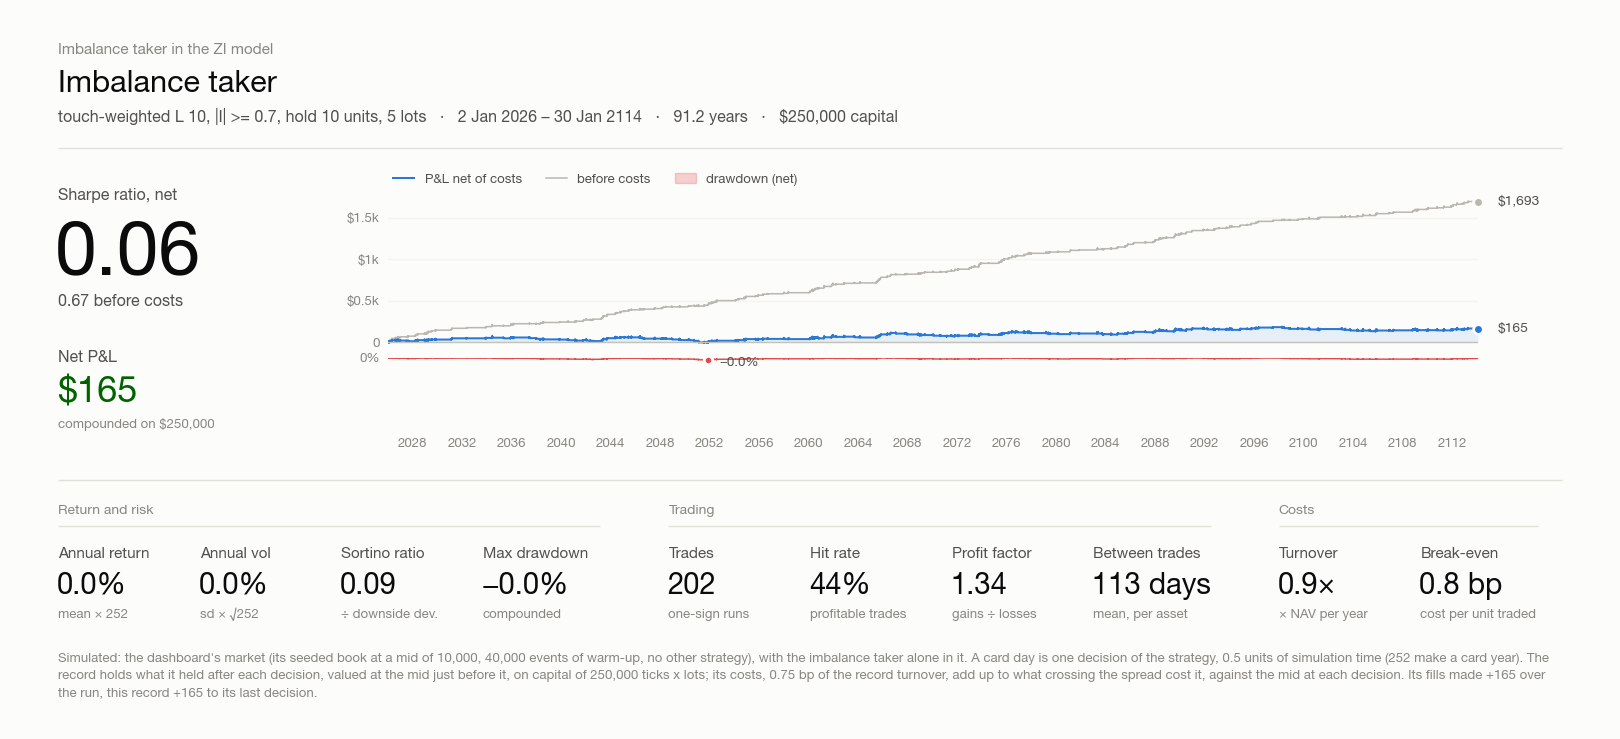

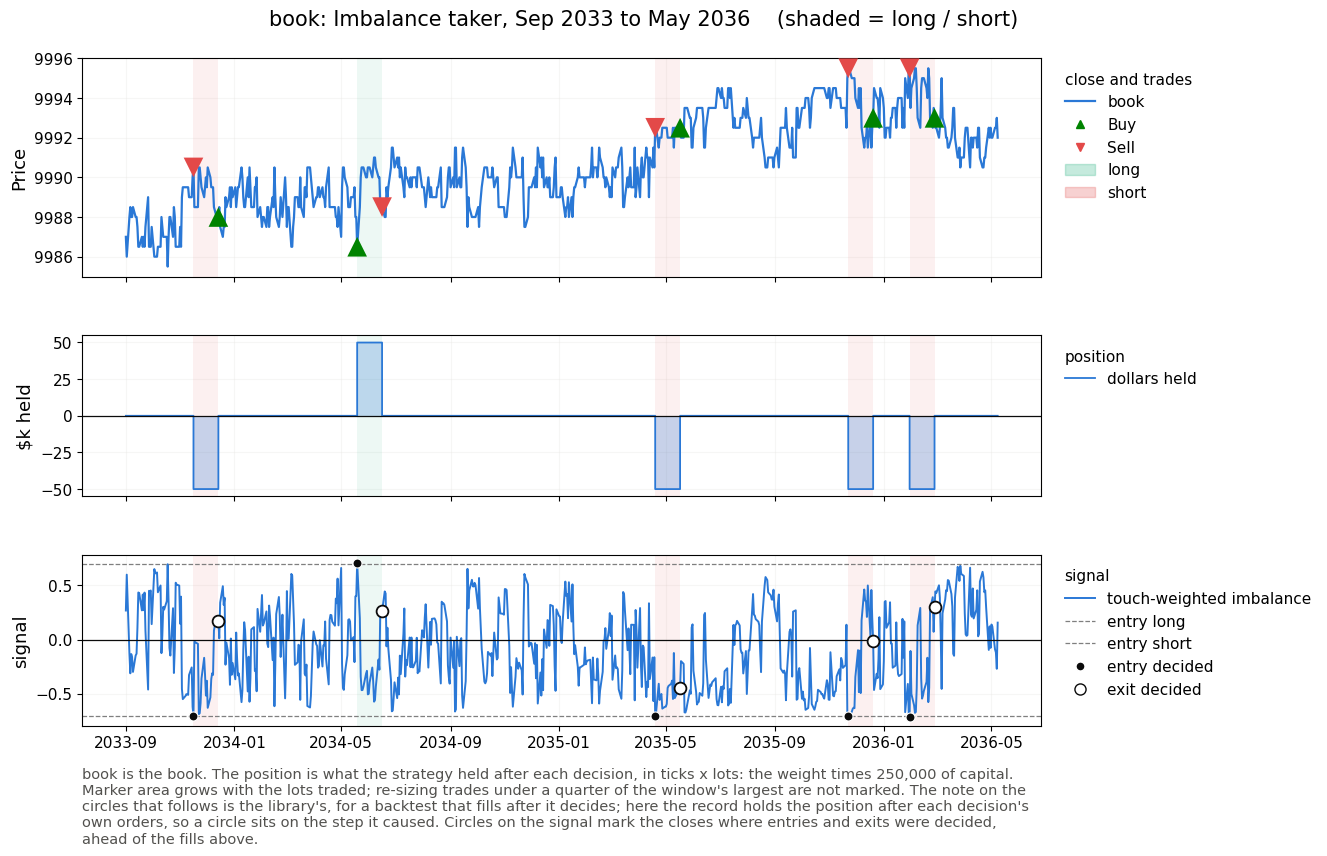

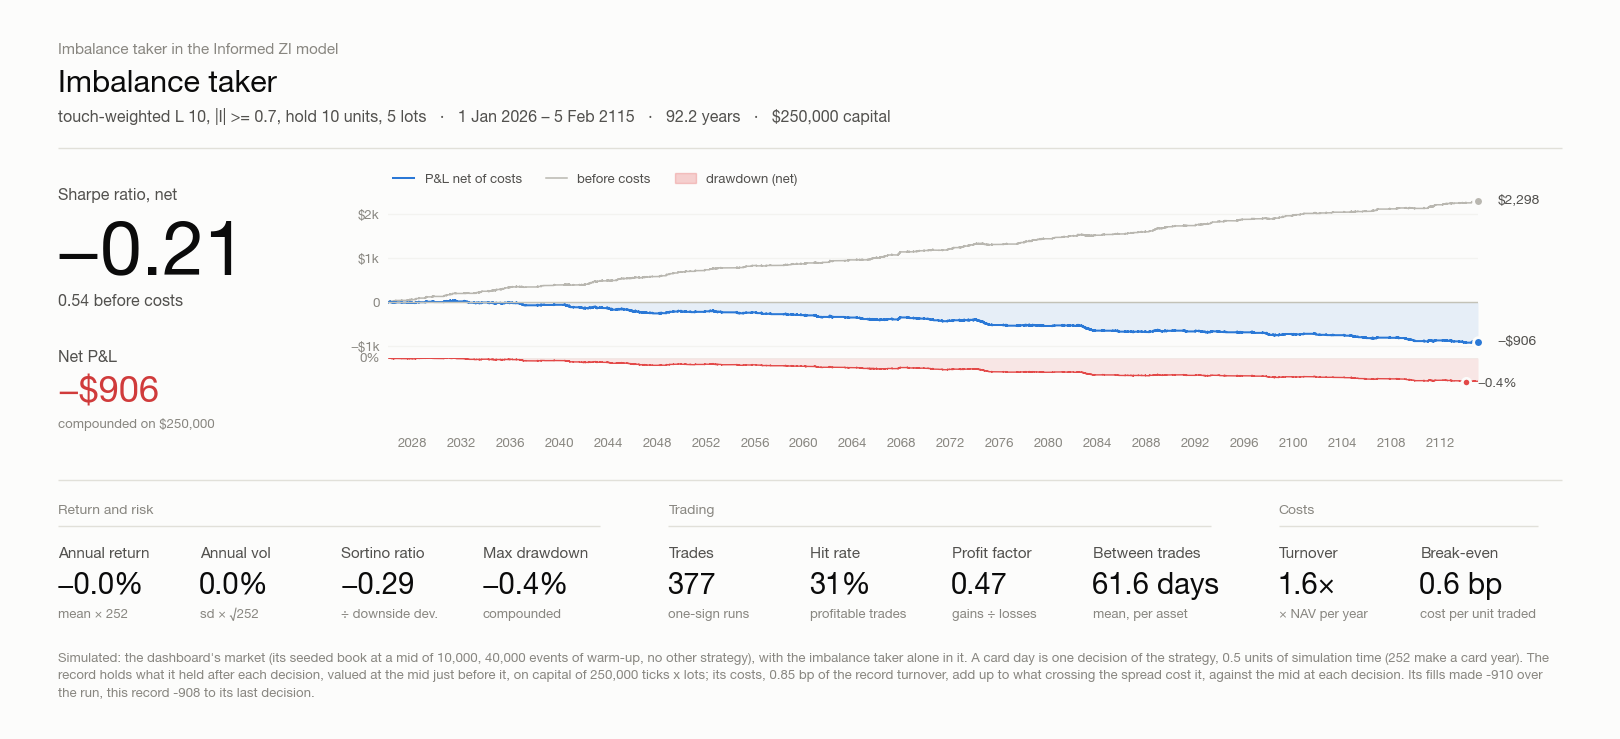

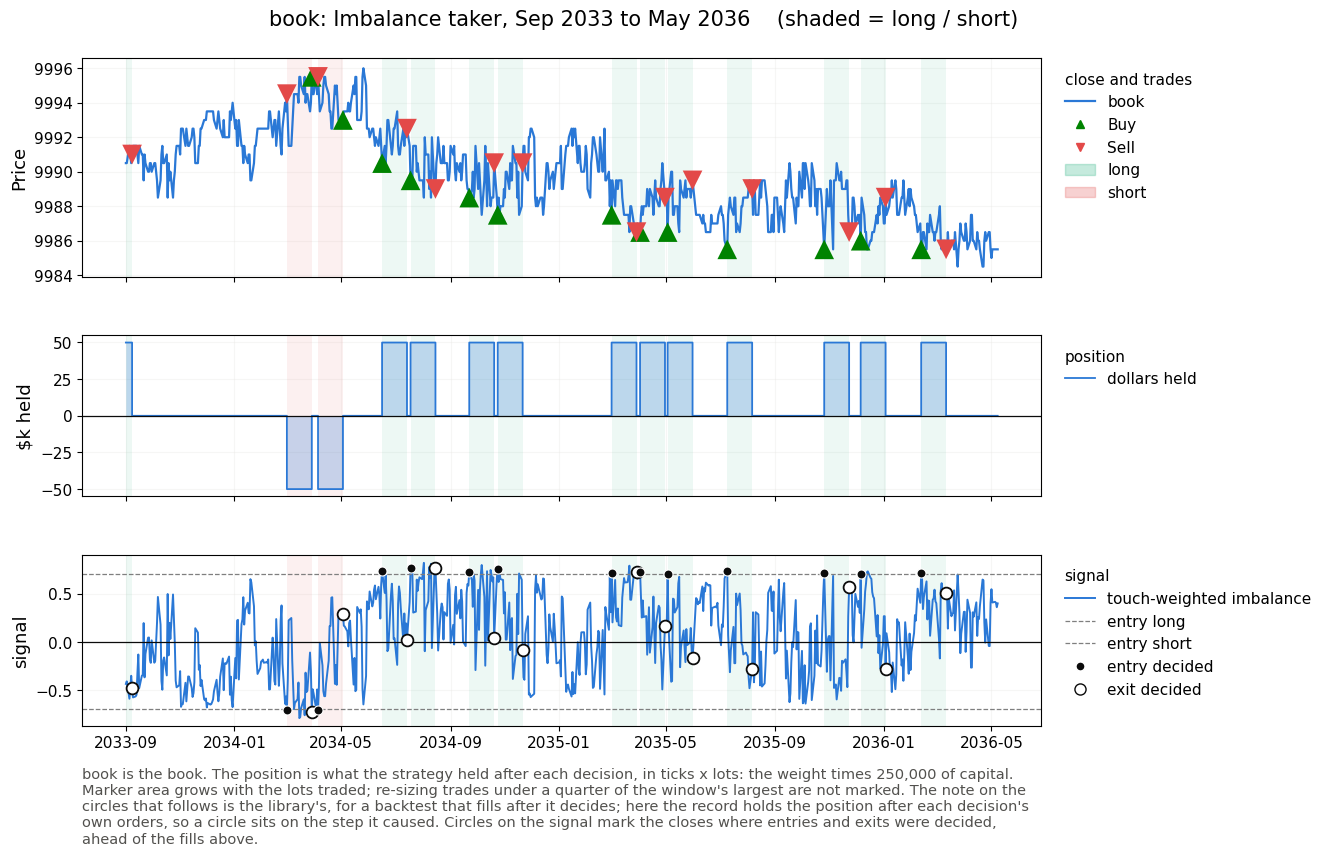

Each card against the fills (the fills over the whole run, the card to its last decision): {'ZI': '+165 and +165', 'Informed ZI': '-910 and -908'}


In [16]:
TAKER_SETTING = (
    "the dashboard's market (its seeded book at a mid of 10,000, 40,000 events of warm-up, no other strategy), with "
    'the '
    'imbalance taker alone in it'
)
taker_card_check = {}
for key in TAKER_MODELS:
    made = taker[(taker.model == key) & (taker.label == label_of(MAIN)) & (taker.seed == SEEDS[0])].after.item()
    taker_card_check[key] = card(
        taker_history[key],
        TAKER_CAPITAL,
        'Imbalance taker',
        'touch-weighted L 10, |I| >= 0.7, hold 10 units, 5 lots',
        f'Imbalance taker in the {NAMES[key]} model',
        TAKER_SETTING,
        'touch-weighted imbalance',
        [(0.7, 'C7', 'entry long'), (-0.7, 'C7', 'entry short')],
        made,
    )
print(
    'Each card against the fills (the fills over the whole run, the card to its last decision):',
    {NAMES[k]: f'{a:+,.0f} and {b:+,.0f}' for k, (a, b) in taker_card_check.items()},
)

The comparison is a taker alone in the dashboard's market (its seeded book at a mid of 10,000, 40,000 events of warm-up), over 12,000 units a run on seeds 101 to 112. When it is flat and the absolute value of the board's touch-weighted L 10 imbalance (the value a trigger sees), |I|, is at least the threshold, it sends a market order of 5 lots in the imbalance's direction and leaves by the clock after the hold; a round trip is 5 lots in and out, in ticks x lots. The baselines are 0 after costs and a null that enters in a random direction at a tenth of its flat decisions and holds the same time, which carries no information: its P&L is the spread and the taker's own push on the mid. Before costs adds back the spread paid, and less the null's takes off what the same trades earn in a random direction at the same hold, paired by seed.

**Only the corner of the grid with the fewest entries pays after costs, and only in ZI.** At |I| >= 0.7 and a hold of 10 the taker makes 1.36 (se 0.14) a round trip after costs and +270 (se 30) over the run on 196 entries, positive on 12 of 12 seeds; at a hold of 30, 1.79 (se 0.19) and +258 (se 25) on 147 entries, 12 of 12 again. At a hold of 2 it loses: -0.76 (se 0.09) and -216 (se 31) on 280 entries, 0 of 12. Every other cell loses on every seed: at |I| >= 0.5 and a hold of 10, -1.52 (se 0.06) and -1,295 (se 55); at |I| >= 0.3, -3.92 (se 0.07) and -4,095 (se 71); the queue imbalance (L 1, |I| >= 0.9, hold 10), -3.03 (se 0.08) and -1,708 (se 47). The loss shrinks as the threshold and the hold rise and the entries fall (3,819 at |I| >= 0.3 and a hold of 2). Two of the 20 cells over both models pay. VisualHFT's R-002 calls the imbalance unprofitable as a standalone taker (a spread-to-move ratio of 6.18x): here it is, in 18 of 20 cells.

**The signal is there before costs, in both models, and the spread takes it.** In ZI the round trip before costs, less the null's, is 4.13 (se 0.07) to 9.45 (se 0.20), rising with the threshold and the hold: 8.72 (se 0.19) in the main cell, which makes 8.96 (se 0.14) before costs and keeps 1.36 after. The null loses 9.30 (se 0.07), 9.37 (se 0.10) and 9.44 (se 0.10) a round trip at holds of 2, 10 and 30, by construction (it pays the spread), and earns +0.46 (se 0.06), +0.24 (se 0.09) and +0.14 (se 0.12) before costs: the taker's own push on the mid, which a review measured at 0.10 ticks at 2 units for a 5-lot market order. So the plain before-cost figure includes the taker's impact and is not the signal's worth; the figure less the null's is.

**In Informed ZI it loses in every cell: its signal is weaker, the spread it pays larger, and the informed traders are why.** The main cell makes -2.75 (se 0.14) a round trip after costs and -1,085 (se 62) over the run, positive on 0 of 12 seeds, on 5.88 (se 0.11) before costs and 5.86 (se 0.15) less the null's, against 8.72 in ZI. The null loses more here, 10.84 (se 0.08), 11.02 (se 0.08) and 11.19 (se 0.22) a round trip, so the spread it pays is larger. The loss is the informed traders' doing: an independent check outside this notebook found that with them off (`kappa` 0, the rest as in Informed ZI) the taker's run is ZI's, entry for entry, so the 196 entries, 1.36 a round trip and +270 on 12 of 12 seeds of the ZI row reappear. With them on, the same check found that the imbalance the taker enters on points against V more often than with it, that the entries against V carry the whole loss, and that those with V make about what ZI's one-tick trips make. Its reading is that in ZI a near-empty touch queue at a one-tick spread is the queue race, while here it is often the informed having just moved the mid toward V, after which the thin queue the imbalance reads points back. Fewer of its entries are at one-tick spreads than in ZI, which is the larger spread it pays. Section 1's touch L 10 lifts (0.7 pp (se 0.2) in Informed ZI against 1.4 (se 0.1) in ZI) are over all readings and not where the taker trades, which by the same check is mostly at one-tick spreads, where the touch L 10 reading hits 73.5% in ZI and 72.1% in Informed ZI. Unlike ZI's, its before-cost figure less the null's does not keep rising with the hold: at |I| >= 0.7 it is 5.71 (se 0.10), 5.86 (se 0.15) and 4.55 (se 0.37) at holds of 2, 10 and 30. The best cell after costs by the round trip is the hold of 2 at |I| >= 0.7, -2.74 (se 0.08), a tie with the hold of 10 (-2.75 (se 0.14)); by the P&L over the run it is the hold of 30, -946 (se 52).

**The main cell is not the best cell of the grid, and a count of positive seeds is not a test.** In ZI the round trip is best at the hold of 30 (1.79 (se 0.19)) and not at 10 (1.36 (se 0.14)), though the P&L over the run is about the same (+258 (se 25) and +270 (se 30)). The main cell was fixed on seeds 1 to 8 as the positive cell with the most entries, and "positive on 12 of 12" is a count over a list of cells fixed in advance.

**The cards (seed 101, the main cell) show the table's two outcomes: +165 in ZI and -910 in Informed ZI.** In ZI the fills made +165 and the record +165, on 202 trades, with a net Sharpe of 0.06 and 0.67 before costs. In Informed ZI the fills made -910 and the record -908, on 377 trades, with -0.21 net and 0.54 before costs, and a turnover of 1.6x against 0.9x. A card day is one decision (0.5 units) and 252 make a card year, so the Sharpe is on that convention and is for comparing the two cards. Seed 101's +165 is below the mean of the twelve seeds, +270 (se 30). The chart marks each entry at the line of 0.7 or -0.7 and each exit, decided by the clock, wherever the imbalance then is.

### 7b. Pulling Quotes on VPIN

In [17]:
JOINER_CELLS = ('sigma_v 0.3 (default)', 'sigma_v 1.0', 'persistence 0.85')  # from section 4's CELLS
THRESHOLDS = (0.16, 0.20, 0.25)  # VPIN, tick side: the dashboard's studies with the side changed from true to tick
PULL_MIN, PULL_MAX = 0.01, 0.99  # a rule that pulls less or more than this has no placebo worth running


class PullingJoiner(QuoteJoiner):
    # lob.strategies.QuoteJoiner (5 lots at the best bid and at the best ask, at most 50 lots, every 0.5 units, keeping
    # its place in the queue) that rests nothing while a rule says to pull: 'vpin' (the board's VPIN is at or above
    # `threshold`), 'block' (a placebo: pulled for episodes of `episode` decisions on average, a `share` of the time,
    # with no regard for VPIN) or 'never' (the joiner as it is). Its signal is the VPIN it saw.
    def __init__(self, manager, rule='never', threshold=None, share=None, episode=None, seed=0):
        super().__init__(size=5, limit=50, interval=0.5)
        self.manager, self.rule, self.threshold, self.share, self.episode = manager, rule, threshold, share, episode
        self.random = np.random.default_rng(seed + 777)
        self.on = None  # the placebo's chain: pulled now or not (not `state`, which is Strategy.state() for a snapshot)
        self.vpins, self.pulls = array('d'), array('b')

    def _chain(self):
        # Two states, pulled and not, with exits at the rates that give pulls of mean length `episode` decisions taking
        # a `share` of the time. Pulling in episodes as long as VPIN's own is what keeps a re-quote from going to the
        # back of the queue at every decision, which is a cost of pulling and not of VPIN's timing.
        if self.on is None:
            self.on = self.random.random() < self.share
        elif self.on:
            if self.random.random() < 1.0 / self.episode:
                self.on = False
        elif self.random.random() < self.share / (self.episode * (1.0 - self.share)):
            self.on = True
        return self.on

    def decide(self, view):
        vpin = self.manager.studies['vpin'].value()
        pull = bool(
            (vpin is not None and vpin >= self.threshold)
            if self.rule == 'vpin'
            else (self._chain() if self.rule == 'block' else False)
        )
        self.vpins.append(math.nan if vpin is None else vpin)
        self.pulls.append(pull)
        plan = Plan(quotes={}) if pull else super().decide(view)
        plan.signal = vpin
        return plan


def episodes_of(pulls):
    # episodes of pulling: how many, and their total length in decisions
    on = np.frombuffer(pulls, dtype=np.int8).astype(int)
    starts = int((np.diff(np.concatenate([[0], on])) == 1).sum())
    return starts, int(on.sum())


def joiner_run(cell, seed, rule, threshold=None, share=None, episode=None, keep=False, record=False):
    manager = new_manager('informed_zi', seed, CELLS[cell], vpin_side='tick')
    manager.step(STRATEGY_WARMUP)
    wire = Wire(manager, events=True, fills=True)
    joiner = PullingJoiner(manager, rule, threshold, share, episode, seed)
    running = start(manager, wire, joiner, 'joiner')
    t0 = manager.sim_time
    play(manager, STRATEGY_UNITS)
    account = running.account
    summary = account.summary(manager.book.mid_price)
    fills = np.array(wire.fills).reshape(-1, 9)  # event, time, price, lots, buying, maker, mid before, informed, VPIN
    t, mid = np.array(wire.t), forward_fill(np.array(wire.mid))
    at = np.searchsorted(t, fills[:, 1] + HORIZON_UNITS, side='right') - 1
    ok = fills[:, 1] + HORIZON_UNITS <= t[-1]
    buy, lots, informed = fills[:, 4] == 1, fills[:, 3], fills[:, 7] == 1
    gain = np.where(buy, mid[at] - fills[:, 2], fills[:, 2] - mid[at])  # the joiner's gain a lot, 30 units later
    starts, pulled = episodes_of(joiner.pulls)
    out = {
        'cell': cell,
        'seed': seed,
        'rule': rule,
        'threshold': threshold,
        'units': manager.sim_time - t0,
        'pnl': summary['total'],
        'fills': account.fills,
        'lots': account.bought + account.sold,
        'maker edge': summary['maker_edge'],
        'markout 100 events': summary['markout'],
        'gain 30 units': weighted(gain, lots, ok),
        'gain 30 units informed': weighted(gain, lots, ok & informed),
        'gain 30 units uninformed': weighted(gain, lots, ok & ~informed),
        'informed share': lots[informed].sum() / lots.sum() if lots.sum() else math.nan,
        'decisions': len(joiner.pulls),
        'pulled': pulled,
        'episodes': starts,
    }
    if keep:  # the never-pulling joiner's fills and VPINs, for the regime split
        out['vpin decisions'] = np.array(joiner.vpins, dtype=np.float32)
        out['fills log'] = {
            'gain': np.where(ok, gain, np.nan).astype(np.float32),
            'lots': lots.astype(np.float32),
            'informed': informed,
            'vpin': fills[:, 8].astype(np.float32),
        }
    if record:
        out['history'] = list(wire.history)
    return out


FIRST = SEEDS[0]  # the card's seed
RULES = [('never', None)] + [('vpin', theta) for theta in THRESHOLDS]
jobs = [(cell, seed, rule, theta) for cell in JOINER_CELLS for rule, theta in RULES for seed in SEEDS]
joiner_runs = Parallel(n_jobs=N_JOBS)(
    delayed(joiner_run)(
        cell,
        seed,
        rule,
        theta,
        keep=(rule == 'never'),
        record=(seed == FIRST and cell == JOINER_CELLS[0] and (rule, theta) in (('never', None), ('vpin', 0.20))),
    )
    for cell, seed, rule, theta in jobs
)
first_pass = pd.DataFrame(
    [{k: v for k, v in run.items() if k not in ('vpin decisions', 'fills log', 'history')} for run in joiner_runs]
)

In [18]:
never = {(run['cell'], run['seed']): run for run in joiner_runs if run['rule'] == 'never'}

# In the informed cells the tick VPIN is higher with the joiner in the market than without (section 4; in the
# persistence cell it is not). Its quotes change the flow itself, and they thicken the touch, so that prices change
# less often and the tick rule gives an unchanged price the last sign. So a threshold must be set, and read, in the
# market with the joiner in it.
presence = {
    cell: {
        'tick VPIN, no strategy (section 4)': said(values_of(cell, 'vpin tick')),
        'tick VPIN, the joiner never pulling': said(
            [np.nanmean(never[cell, seed]['vpin decisions']) for seed in SEEDS]
        ),
    }
    for cell in JOINER_CELLS
}
note(
    'The tick VPIN the joiner reads, with it in the market and without it (section 4), mean over seeds, standard '
    'error across them:',
)
display(pd.DataFrame(presence).T)


def regime(cell, theta):
    # The never-pulling joiner's fills, split by the VPIN in force when they happened: at or above the threshold, or
    # below.
    out = {name: [] for name in ('time', 'fills lo', 'fills hi', 'gain lo', 'gain hi', 'informed lo', 'informed hi')}
    for seed in SEEDS:
        run = never[cell, seed]
        vpin = run['vpin decisions']
        defined = np.isfinite(vpin)
        share = (vpin[defined] >= theta).mean()
        log = run['fills log']
        out['time'].append(share)
        thin = not PULL_MIN <= share <= PULL_MAX  # one regime all but empty on this seed: nothing to compare
        for name, keep, span in (
            ('lo', log['vpin'] < theta, 1 - share),
            ('hi', log['vpin'] >= theta, share),
        ):
            lots, informed = log['lots'][keep], log['informed'][keep]
            out[f'fills {name}'].append(
                np.nan if thin else keep.sum() / (run['units'] * defined.mean() * span)
            )
            out[f'gain {name}'].append(
                np.nan if thin else weighted(log['gain'], log['lots'], keep & np.isfinite(log['gain']))
            )
            out[f'informed {name}'].append(np.nan if thin or not lots.sum() else lots[informed].sum() / lots.sum())
    return out


MIN_SEEDS = len(SEEDS) // 2  # a row needs both regimes on at least half the seeds
split, thin_rules = {}, []
for cell in JOINER_CELLS:
    for theta in THRESHOLDS:
        r = regime(cell, theta)
        both = np.isfinite(r['gain lo']) & np.isfinite(r['gain hi'])
        if both.sum() < MIN_SEEDS:
            thin_rules.append((cell, theta))
            continue
        split[cell, f'VPIN >= {theta:.2f}'] = {
            ('time', 'at or above'): said(r['time'], 2),
            ('seeds', 'with both'): f'{both.sum()}',
            ('fills a unit', 'below'): said(r['fills lo'], 2),
            ('fills a unit', 'at or above'): said(r['fills hi'], 2),
            ('gain a lot at 30 units', 'below'): said(r['gain lo'], 3),
            ('gain a lot at 30 units', 'at or above'): said(r['gain hi'], 3),
            ('informed share of lots', 'below'): said(r['informed lo'], 3),
            ('informed share of lots', 'at or above'): said(r['informed hi'], 3),
        }
note(
    'The joiner that never pulls, its fills split by the VPIN (tick side) in force: how often it is at or above each',
    'threshold, and how many fills a unit, what a lot gained 30 units later, and what share of its lots were informed',
    '(mean over seeds, standard error across them). If high VPIN were a worse time to quote, the right-hand column of',
    f'each pair would be worse. A seed counts only if it spends {PULL_MIN:.0%} to {PULL_MAX:.0%} of its time at or '
    f'above the threshold, and a rule is shown only if at least {MIN_SEEDS} of the {len(SEEDS)} seeds count.',
)
print('Rules left out of the split (one regime empty or all but):', thin_rules or 'none')
display(pd.DataFrame(split).T)

# The placebo, second pass: pulls in episodes as long as the VPIN rule's own, taking as large a share of the time, both
# measured from the VPIN rule's decisions in the first pass on these seeds (not from the never-pulling joiner's VPIN:
# pulling lowers the tick VPIN, which the joiner's quotes raise).
matched = {}
for cell in JOINER_CELLS:
    for theta in THRESHOLDS:
        g = first_pass[(first_pass.cell == cell) & (first_pass.rule == 'vpin') & (first_pass.threshold == theta)]
        matched[cell, theta] = (g.pulled.sum() / g.decisions.sum(), g.pulled.sum() / max(g.episodes.sum(), 1))
placed = {key: value for key, value in matched.items() if PULL_MIN <= value[0] <= PULL_MAX}
print('Rules that pull too little or too much for a placebo:', [key for key in matched if key not in placed] or 'none')
jobs = [(cell, seed, theta) for (cell, theta) in placed for seed in SEEDS]
placebo_runs = Parallel(n_jobs=N_JOBS)(
    delayed(joiner_run)(cell, seed, 'block', theta, share=placed[cell, theta][0], episode=placed[cell, theta][1])
    for cell, seed, theta in jobs
)
placebo = pd.DataFrame(
    [{k: v for k, v in run.items() if k not in ('vpin decisions', 'fills log', 'history')} for run in placebo_runs]
)


def series(cell, rule, theta, column):
    frame = first_pass if rule != 'block' else placebo
    g = frame[(frame.cell == cell) & (frame.rule == rule) & ((frame.threshold == theta) | (rule == 'never'))]
    return g.set_index('seed')[column].sort_index()


def joiner_fills(cell, rule, theta):
    return {
        'informed share of lots': said(series(cell, rule, theta, 'informed share'), 3),
        '30-unit gain a lot, informed fills': said(series(cell, rule, theta, 'gain 30 units informed'), 2),
        'uninformed fills': said(series(cell, rule, theta, 'gain 30 units uninformed'), 2),
        'edge against the mid a lot': said(series(cell, rule, theta, 'maker edge'), 3),
        '100-event markout a lot': said(series(cell, rule, theta, 'markout 100 events'), 3),
    }


timing, fills_table, cost = {}, {}, {}
for cell in JOINER_CELLS:
    base = series(cell, 'never', None, 'pnl')
    timing[cell, 'never'] = {
        'pulled share': '0',
        'fills': said(series(cell, 'never', None, 'fills'), 0),
        'P&L': said(base, 0),
        'difference from never': '-',
        'VPIN rule less placebo': '-',
    }
    fills_table[cell, 'never'] = joiner_fills(cell, 'never', None)
    for theta in THRESHOLDS:
        for rule in ('vpin', 'block'):
            if rule == 'block' and (cell, theta) not in placed:
                continue
            name = f'VPIN >= {theta:.2f}' if rule == 'vpin' else f'placebo matched to {theta:.2f}'
            pnl = series(cell, rule, theta, 'pnl')
            pulled = series(cell, rule, theta, 'pulled') / series(cell, rule, theta, 'decisions')
            timing[cell, name] = {
                'pulled share': said(pulled, 2),
                'fills': said(series(cell, rule, theta, 'fills'), 0),
                'P&L': said(pnl, 0),
                'difference from never': said(pnl - base, 0),
                'VPIN rule less placebo': said(series(cell, 'vpin', theta, 'pnl') - pnl, 0) if rule == 'block' else '-',
            }
            fills_table[cell, name] = joiner_fills(cell, rule, theta)
            if rule == 'vpin':
                cost[cell, name] = {
                    'pulled share': said(pulled, 2),
                    'P&L a unit, never': said(base / series(cell, 'never', None, 'units'), 2),
                    'P&L a unit, this rule': said(pnl / series(cell, rule, theta, 'units'), 2),
                    'loss the time off the book predicts': said(pulled * base, 0),
                    'loss measured': said(base - pnl, 0),
                }
note(
    '\nThe VPIN rule against a placebo that pulls as much, in episodes as long, at times that ignore VPIN. P&L in '
    'ticks x lots',
    f'over {STRATEGY_UNITS:,} units, marked at the mid; differences are paired by seed (the same seed, a different '
    'path once the',
    "fills differ), mean over seeds with the standard error across them. The VPIN rule's P&L less the placebo's is the "
    "most VPIN's",
    'timing is worth over a placebo, here.',
)
display(pd.DataFrame(timing).T)
note(
    "\nWhat the rules do to the joiner's fills (gains are the joiner's: positive when it gained):",
)
display(pd.DataFrame(fills_table).T)
note(
    '\nThe cost of time off the book: what pulling lost, against what the time off the book alone predicts (the share '
    'of',
    'the time pulled times the P&L of never pulling):',
)
display(pd.DataFrame(cost).T)

The tick VPIN the joiner reads, with it in the market and without it (section 4), mean over seeds, standard error across
them:


,"tick VPIN, no strategy (section 4)","tick VPIN, the joiner never pulling"
sigma_v 0.3 (default),0.129 (0.001),0.146 (0.001)
sigma_v 1.0,0.191 (0.001),0.205 (0.001)
persistence 0.85,0.231 (0.001),0.229 (0.001)


The joiner that never pulls, its fills split by the VPIN (tick side) in force: how often it is at or above each
threshold, and how many fills a unit, what a lot gained 30 units later, and what share of its lots were informed (mean
over seeds, standard error across them). If high VPIN were a worse time to quote, the right-hand column of each pair
would be worse. A seed counts only if it spends 1% to 99% of its time at or above the threshold, and a rule is shown
only if at least 6 of the 12 seeds count.
Rules left out of the split (one regime empty or all but): [('sigma_v 0.3 (default)', 0.25), ('persistence 0.85', 0.16)]


time     seeds fills a unit  \
                                    at or above with both        below   
sigma_v 0.3 (default) VPIN >= 0.16  0.28 (0.02)        12  1.01 (0.00)   
                      VPIN >= 0.20  0.03 (0.01)        10  1.01 (0.00)   
sigma_v 1.0           VPIN >= 0.16  0.95 (0.01)        12  1.08 (0.02)   
                      VPIN >= 0.20  0.53 (0.02)        12  1.05 (0.00)   
                      VPIN >= 0.25  0.08 (0.01)        12  1.05 (0.00)   
persistence 0.85      VPIN >= 0.20  0.89 (0.01)        12  0.82 (0.01)   
                      VPIN >= 0.25  0.20 (0.02)        12  0.82 (0.00)   

                                                gain a lot at 30 units  \
                                    at or above                  below   
sigma_v 0.3 (default) VPIN >= 0.16  1.00 (0.00)          0.348 (0.008)   
                      VPIN >= 0.20  1.03 (0.01)          0.347 (0.006)   
sigma_v 1.0           VPIN >= 0.16  1.05 (0.00)          0.398 (0.022)   
                      VPIN >= 0.20  1.05 (0.00)          0.358 (0.007)   
                      VPIN >= 0.25  1.03 (0.01)          0.370 (0.006)   
persistence 0.85      VPIN >= 0.20  0.81 (0.00)          0.220 (0.010)   
                      VPIN >= 0.25  0.81 (0.00)          0.226 (0.005)   

                                                  informed share of lots  \
                                      at or above                  below   
sigma_v 0.3 (default) VPIN >= 0.16  0.352 (0.011)          0.163 (0.001)   
                      VPIN >= 0.20  0.338 (0.046)          0.166 (0.001)   
sigma_v 1.0           VPIN >= 0.16  0.371 (0.005)          0.207 (0.006)   
                      VPIN >= 0.20  0.385 (0.007)          0.211 (0.002)   
                      VPIN >= 0.25  0.405 (0.025)          0.216 (0.001)   
persistence 0.85      VPIN >= 0.20  0.228 (0.006)          0.000 (0.000)   
                      VPIN >= 0.25  0.229 (0.011)          0.000 (0.000)   

                                                   
                                      at or above  
sigma_v 0.3 (default) VPIN >= 0.16  0.174 (0.002)  
                      VPIN >= 0.20  0.176 (0.009)  
sigma_v 1.0           VPIN >= 0.16  0.217 (0.001)  
                      VPIN >= 0.20  0.222 (0.001)  
                      VPIN >= 0.25  0.223 (0.003)  
persistence 0.85      VPIN >= 0.20  0.000 (0.000)  
                      VPIN >= 0.25  0.000 (0.000)

Rules that pull too little or too much for a placebo: [('sigma_v 0.3 (default)', 0.25), ('persistence 0.85', 0.16)]



The VPIN rule against a placebo that pulls as much, in episodes as long, at times that ignore VPIN. P&L in ticks x lots
over 12,000 units, marked at the mid; differences are paired by seed (the same seed, a different path once the fills
differ), mean over seeds with the standard error across them. The VPIN rule's P&L less the placebo's is the most VPIN's
timing is worth over a placebo, here.


pulled share        fills  \
sigma_v 0.3 (default) never                              0   12115 (22)   
                      VPIN >= 0.16             0.21 (0.01)   9606 (142)   
                      placebo matched to 0.16  0.20 (0.01)   9724 (153)   
                      VPIN >= 0.20             0.03 (0.01)   11804 (76)   
                      placebo matched to 0.20  0.02 (0.00)   11864 (62)   
                      VPIN >= 0.25             0.00 (0.00)   12108 (22)   
sigma_v 1.0           never                              0   12599 (22)   
                      VPIN >= 0.16             0.86 (0.01)   1815 (169)   
                      placebo matched to 0.16  0.87 (0.01)   1629 (137)   
                      VPIN >= 0.20             0.46 (0.02)   6874 (256)   
                      placebo matched to 0.20  0.46 (0.02)   6870 (198)   
                      VPIN >= 0.25             0.07 (0.01)  11810 (112)   
                      placebo matched to 0.25  0.06 (0.01)  11913 (105)   
persistence 0.85      never                              0    9786 (24)   
                      VPIN >= 0.16             1.00 (0.00)       12 (6)   
                      VPIN >= 0.20             0.88 (0.02)   1150 (160)   
                      placebo matched to 0.20  0.90 (0.01)    1017 (90)   
                      VPIN >= 0.25             0.20 (0.02)   7804 (157)   
                      placebo matched to 0.25  0.19 (0.01)   7923 (132)   

                                                        P&L  \
sigma_v 0.3 (default) never                     21574 (487)   
                      VPIN >= 0.16              17495 (515)   
                      placebo matched to 0.16   17673 (331)   
                      VPIN >= 0.20              21495 (552)   
                      placebo matched to 0.20   22112 (520)   
                      VPIN >= 0.25              21698 (533)   
sigma_v 1.0           never                     25587 (848)   
                      VPIN >= 0.16               2021 (527)   
                      placebo matched to 0.16    3173 (866)   
                      VPIN >= 0.20              14582 (825)   
                      placebo matched to 0.20  14156 (1333)   
                      VPIN >= 0.25              23119 (652)   
                      placebo matched to 0.25   22964 (549)   
persistence 0.85      never                     10255 (299)   
                      VPIN >= 0.16                 -30 (29)   
                      VPIN >= 0.20               1099 (317)   
                      placebo matched to 0.20     736 (290)   
                      VPIN >= 0.25               8131 (296)   
                      placebo matched to 0.25    8547 (237)   

                                              difference from never  \
sigma_v 0.3 (default) never                                       -   
                      VPIN >= 0.16                      -4079 (821)   
                      placebo matched to 0.16           -3901 (517)   
                      VPIN >= 0.20                        -79 (400)   
                      placebo matched to 0.20             538 (746)   
                      VPIN >= 0.25                        124 (124)   
sigma_v 1.0           never                                       -   
                      VPIN >= 0.16                    -23565 (1189)   
                      placebo matched to 0.16         -22413 (1090)   
                      VPIN >= 0.20                    -11005 (1054)   
                      placebo matched to 0.20         -11431 (1394)   
                      VPIN >= 0.25                     -2467 (1023)   
                      placebo matched to 0.25           -2623 (945)   
persistence 0.85      never                                       -   
                      VPIN >= 0.16                     -10285 (306)   
                      VPIN >= 0.20                      -9156 (365)   
                      placebo matched to 0.20           -9519 (420)   
      


What the rules do to the joiner's fills (gains are the joiner's: positive when it gained):


informed share of lots  \
sigma_v 0.3 (default) never                            0.166 (0.001)   
                      VPIN >= 0.16                     0.165 (0.002)   
                      placebo matched to 0.16          0.163 (0.001)   
                      VPIN >= 0.20                     0.168 (0.002)   
                      placebo matched to 0.20          0.166 (0.001)   
                      VPIN >= 0.25                     0.166 (0.001)   
sigma_v 1.0           never                            0.217 (0.001)   
                      VPIN >= 0.16                     0.212 (0.003)   
                      placebo matched to 0.16          0.215 (0.003)   
                      VPIN >= 0.20                     0.214 (0.001)   
                      placebo matched to 0.20          0.218 (0.002)   
                      VPIN >= 0.25                     0.217 (0.001)   
                      placebo matched to 0.25          0.217 (0.002)   
persistence 0.85      never                            0.000 (0.000)   
                      VPIN >= 0.16                     0.000 (0.000)   
                      VPIN >= 0.20                     0.000 (0.000)   
                      placebo matched to 0.20          0.000 (0.000)   
                      VPIN >= 0.25                     0.000 (0.000)   
                      placebo matched to 0.25          0.000 (0.000)   

                                              30-unit gain a lot, informed fills  \
sigma_v 0.3 (default) never                                         -1.28 (0.04)   
                      VPIN >= 0.16                                  -1.24 (0.02)   
                      placebo matched to 0.16                       -1.21 (0.02)   
                      VPIN >= 0.20                                  -1.25 (0.03)   
                      placebo matched to 0.20                       -1.26 (0.03)   
                      VPIN >= 0.25                                  -1.27 (0.03)   
sigma_v 1.0           never                                         -1.65 (0.04)   
                      VPIN >= 0.16                                  -1.34 (0.05)   
                      placebo matched to 0.16                       -1.64 (0.09)   
                      VPIN >= 0.20                                  -1.45 (0.04)   
                      placebo matched to 0.20                       -1.66 (0.07)   
                      VPIN >= 0.25                                  -1.57 (0.04)   
                      placebo matched to 0.25                       -1.66 (0.04)   
persistence 0.85      never                                                    -   
                      VPIN >= 0.16                                             -   
                      VPIN >= 0.20                                             -   
                      placebo matched to 0.20                                  -   
                      VPIN >= 0.25                                             -   
                      placebo matched to 0.25                                  -   

                                              uninformed fills  \
sigma_v 0.3 (default) never                        0.67 (0.01)   
                      VPIN >= 0.16                 0.66 (0.01)   
                      placebo matched to 0.16      0.66 (0.01)   
                      VPIN >= 0.20                 0.68 (0.01)   
                      placebo matched to 0.20      0.67 (0.01)   
                      VPIN >= 0.25                 0.67 (0.01)   
sigma_v 1.0           never                        0.93 (0.01)   
                      VPIN >= 0.16                 0.78 (0.01)   
                      placebo matched to 0.16      0.90 (0.03)   
                      VPIN >= 0.20                 0.87 (0.01)   
                      placebo matched to 0.20      0.95 (0.02)   
                      VPIN >= 0.25                 0.90 (0.02)   
                      placebo matched to 0.25      0.93 (0.02)   



The cost of time off the book: what pulling lost, against what the time off the book alone predicts (the share of the
time pulled times the P&L of never pulling):


pulled share P&L a unit, never  \
sigma_v 0.3 (default) VPIN >= 0.16  0.21 (0.01)       1.80 (0.04)   
                      VPIN >= 0.20  0.03 (0.01)       1.80 (0.04)   
                      VPIN >= 0.25  0.00 (0.00)       1.80 (0.04)   
sigma_v 1.0           VPIN >= 0.16  0.86 (0.01)       2.13 (0.07)   
                      VPIN >= 0.20  0.46 (0.02)       2.13 (0.07)   
                      VPIN >= 0.25  0.07 (0.01)       2.13 (0.07)   
persistence 0.85      VPIN >= 0.16  1.00 (0.00)       0.85 (0.02)   
                      VPIN >= 0.20  0.88 (0.02)       0.85 (0.02)   
                      VPIN >= 0.25  0.20 (0.02)       0.85 (0.02)   

                                   P&L a unit, this rule  \
sigma_v 0.3 (default) VPIN >= 0.16           1.46 (0.04)   
                      VPIN >= 0.20           1.79 (0.05)   
                      VPIN >= 0.25           1.81 (0.04)   
sigma_v 1.0           VPIN >= 0.16           0.17 (0.04)   
                      VPIN >= 0.20           1.21 (0.07)   
                      VPIN >= 0.25           1.93 (0.05)   
persistence 0.85      VPIN >= 0.16          -0.00 (0.00)   
                      VPIN >= 0.20           0.09 (0.03)   
                      VPIN >= 0.25           0.68 (0.02)   

                                   loss the time off the book predicts  \
sigma_v 0.3 (default) VPIN >= 0.16                          4548 (286)   
                      VPIN >= 0.20                           620 (144)   
                      VPIN >= 0.25                             18 (18)   
sigma_v 1.0           VPIN >= 0.16                         21953 (824)   
                      VPIN >= 0.20                         11737 (625)   
                      VPIN >= 0.25                          1676 (182)   
persistence 0.85      VPIN >= 0.16                         10243 (300)   
                      VPIN >= 0.20                          9068 (314)   
                      VPIN >= 0.25                          2100 (173)   

                                   loss measured  
sigma_v 0.3 (default) VPIN >= 0.16    4079 (821)  
                      VPIN >= 0.20      79 (400)  
                      VPIN >= 0.25    -124 (124)  
sigma_v 1.0           VPIN >= 0.16  23565 (1189)  
                      VPIN >= 0.20  11005 (1054)  
                      VPIN >= 0.25   2467 (1023)  
persistence 0.85      VPIN >= 0.16   10285 (306)  
                      VPIN >= 0.20    9156 (365)  
                      VPIN >= 0.25    2124 (282)

Quote joiner: pulled 0.0% of its decisions on this seed, 12,080 fills.


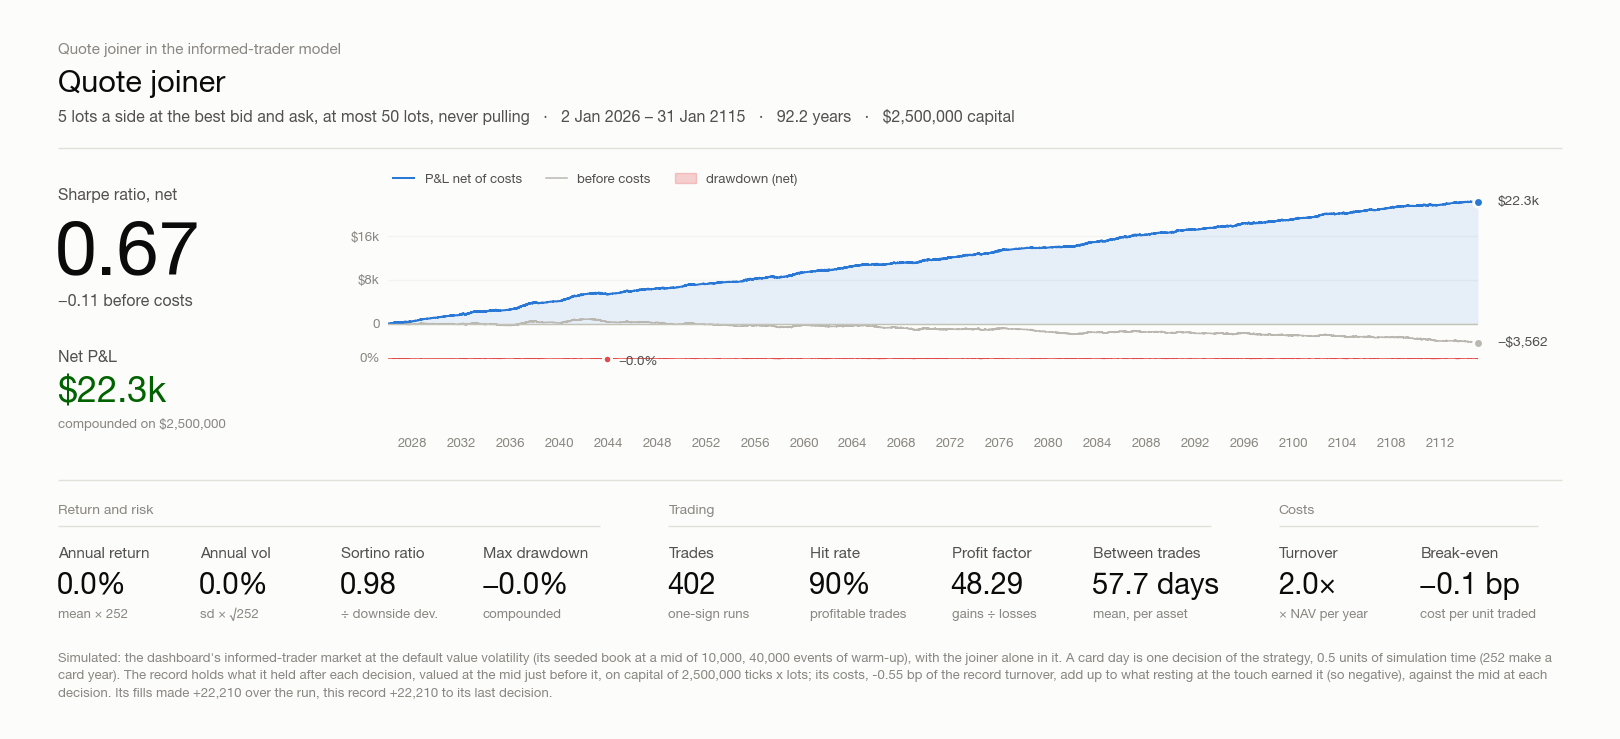

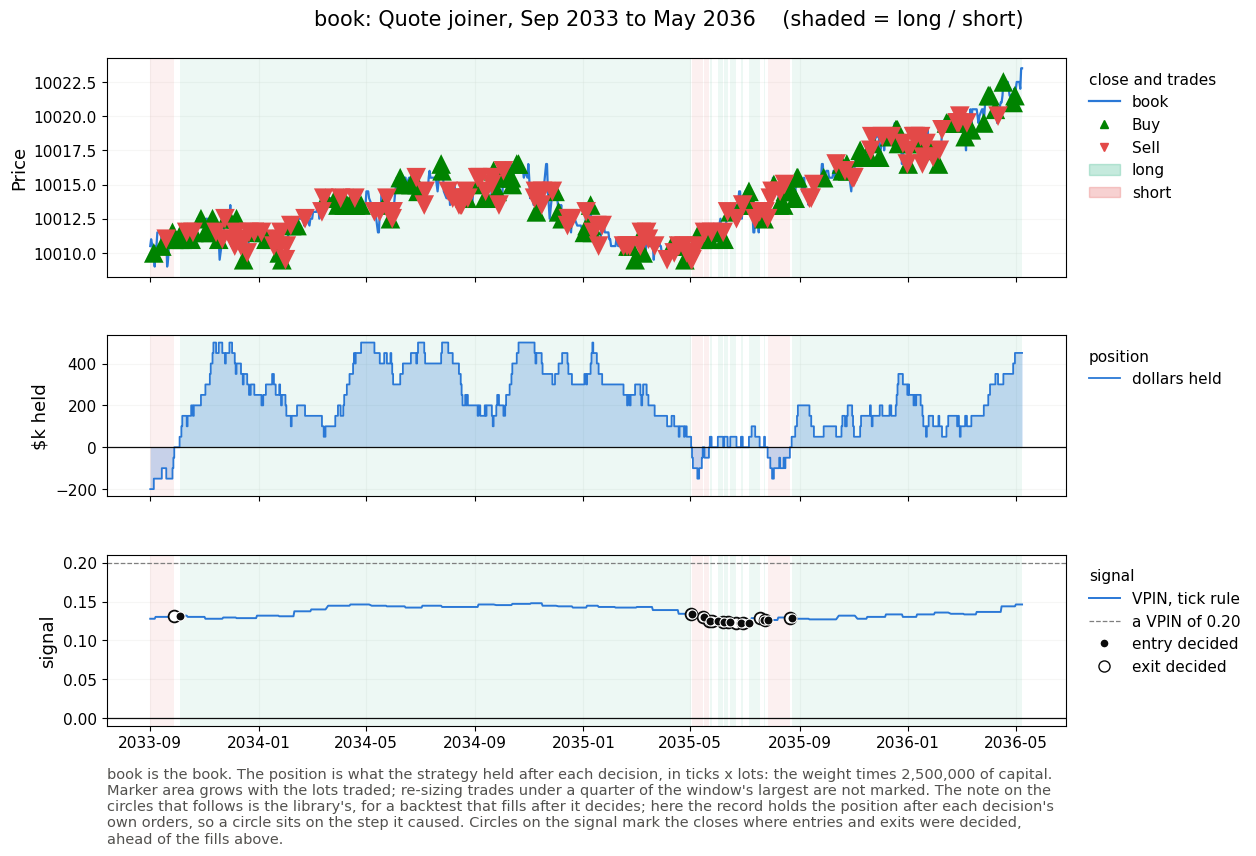

Quote joiner pulling on VPIN: pulled 2.8% of its decisions on this seed, 11,802 fills.


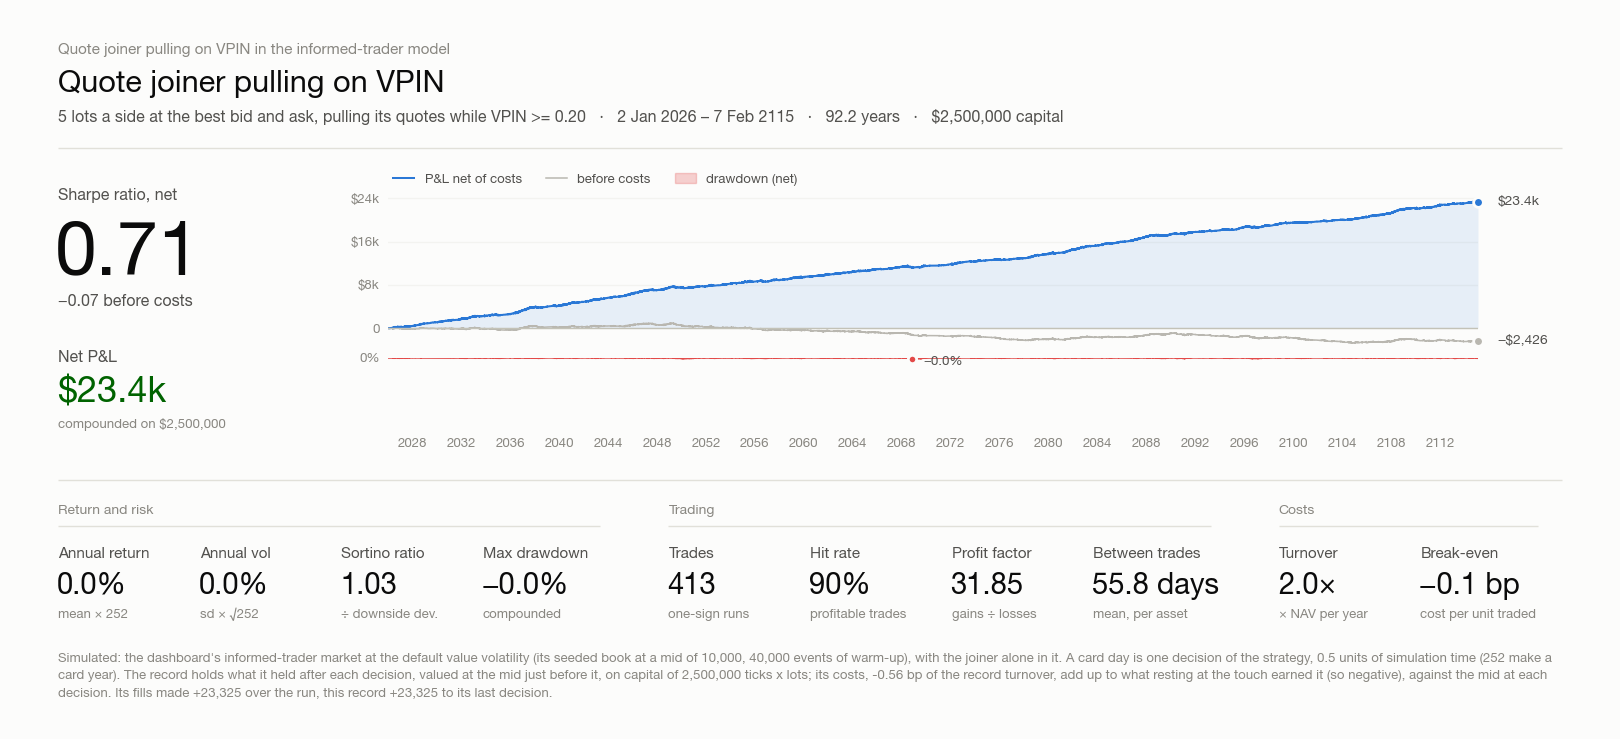

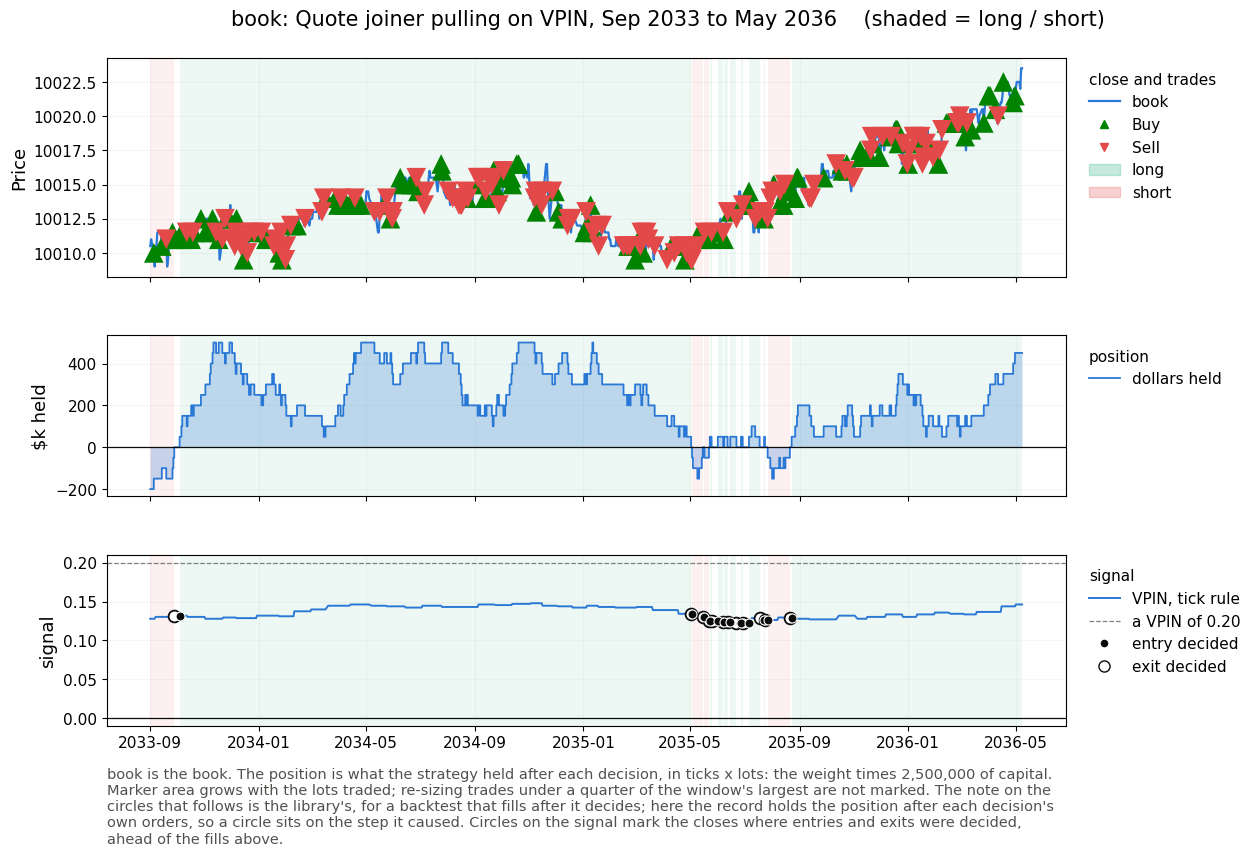

Each card against the fills (the fills over the whole run, the card to its last decision): {'Quote joiner': '+22,210 and +22,210', 'Quote joiner pulling on VPIN': '+23,325 and +23,325'}


In [19]:
JOINER_SETTING = (
    "the dashboard's informed-trader market at the default value volatility (its seeded book at a mid of 10,000, "
    '40,000 events '
    'of warm-up), with the joiner alone in it'
)
joiner_card_check = {}
for rule, theta, strategy, detail in (
    ('never', None, 'Quote joiner', '5 lots a side at the best bid and ask, at most 50 lots, never pulling'),
    (
        'vpin',
        0.20,
        'Quote joiner pulling on VPIN',
        '5 lots a side at the best bid and ask, pulling its quotes while VPIN >= 0.20',
    ),
):
    run = next(
        r
        for r in joiner_runs
        if r['cell'] == JOINER_CELLS[0] and r['seed'] == FIRST and r['rule'] == rule and r['threshold'] == theta
    )
    note(
        f'{strategy}: pulled {run["pulled"] / run["decisions"]:.1%} of its decisions on this seed, {run["fills"]:,} '
        'fills.',
    )
    joiner_card_check[strategy] = card(
        run['history'],
        JOINER_CAPITAL,
        strategy,
        detail,
        f'{strategy} in the informed-trader model',
        JOINER_SETTING,
        'VPIN, tick rule',
        [(0.20, 'C7', 'a VPIN of 0.20')],
        run['pnl'],
    )
print(
    'Each card against the fills (the fills over the whole run, the card to its last decision):',
    {k: f'{a:+,.0f} and {b:+,.0f}' for k, (a, b) in joiner_card_check.items()},
)

The comparison is a quote joiner (5 lots at the best bid and ask, at most 50 lots, every 0.5 units, keeping its place in the queue) that rests nothing while the board's tick-rule VPIN is at or above a threshold of 0.16, 0.20 or 0.25, against the same joiner that never pulls, in three markets: Informed ZI at `sigma_v` 0.3 (the default) and at 1.0, and one-sided flow with no informed traders (persistence 0.85). Each joiner is alone in the dashboard's market (its seeded book at a mid of 10,000, 40,000 events of warm-up), over 12,000 units a run on seeds 101 to 112. The thresholds were chosen on seeds 1 to 8 by the share of time each pulls. The second baseline is a placebo that pulls as much, in episodes as long (both measured from the VPIN rule's own decisions on the same seeds), at times that ignore VPIN. Differences are paired by seed, with a different path once the fills differ.

**High VPIN is not a worse time to quote, so pulling on it only costs the time off the book.** The never-pulling joiner's fills, split by the VPIN in force, are as good in both regimes. In the default cell at a threshold of 0.16, VPIN is at or above it 0.28 (se 0.02) of the time; the joiner gets 1.01 (se 0.00) fills a unit below and 1.00 (se 0.00) at or above, gains 0.348 (se 0.008) and 0.352 (se 0.011) a lot at 30 units, and has 0.163 (se 0.001) and 0.174 (se 0.002) of its lots informed. At `sigma_v` 1.0 the gain at or above is higher at 0.20 (0.385 (se 0.007) against 0.358 (se 0.007)) and at 0.25 (0.405 (se 0.025) against 0.370 (se 0.006)); in two of the seven rows it is lower (0.371 (se 0.005) against 0.398 (se 0.022) at `sigma_v` 1.0 and 0.16, and 0.338 (se 0.046) against 0.347 (se 0.006) at the default and 0.20). The informed share of lots is a little higher at or above in every informed row (0.174 against 0.163 at the default and 0.16, 0.223 (se 0.003) against 0.216 (se 0.001) at `sigma_v` 1.0 and 0.25) and is 0.000 in the persistence cell. Two rules, the default at 0.25 and persistence at 0.16, were left out of the split for one regime empty or all but, and have no placebo.

**The VPIN rule does no better than a placebo that pulls as much, and the difference bounds what VPIN's timing is worth.** The pulled shares match: 0.21 (se 0.01) for the rule and 0.20 (se 0.01) for the placebo at the default and 0.16, 0.46 (se 0.02) for both at `sigma_v` 1.0 and 0.20, 0.88 (se 0.02) and 0.90 (se 0.01) in the persistence cell at 0.20. The rule's P&L less the placebo's, paired by seed, is -178 (se 733) and -616 (se 737) at the default (0.16, 0.20), -1,152 (se 1,198), +426 (se 1,633) and +155 (se 551) at `sigma_v` 1.0 (0.16, 0.20, 0.25), and +363 (se 356) and -416 (se 394) in the persistence cell (0.20, 0.25). The signs are mixed and none is further than about one standard error from 0. At the default and 0.16 the rule makes -4,079 (se 821) against never pulling and the placebo -3,901 (se 517). The bound is loose where pulling cost most: at two standard errors (the difference plus twice its se) VPIN's timing could still be worth up to +1,288 at the default and 0.16 (against the 4,079 that pulling cost there) and +3,692 at `sigma_v` 1.0 and 0.20 (against 11,005), about a third in each, and +1,257 at `sigma_v` 1.0 and 0.25 (against 2,467), about half. In the other cells it is +858 at the default and 0.20 (where pulling cost 79 (se 400), nothing to recover), +1,244 at `sigma_v` 1.0 and 0.16 (against 23,565) and +1,075 and +372 in the persistence cell (against 9,156 and 2,124), 5 to 18% of the cost. An independent check outside this notebook found that the placebo pulls the pooled share on every seed while the rule's own share varies across seeds, which adds noise to each difference (correcting for it left the difference at about 0 at the default and 0.16), and that the placebo matches the rule's mean episode length and not its spread, the rule's episodes being more spread out, with a longer tail of very long ones.

**Pulling on VPIN changes which fills the joiner keeps in one market, and nothing in another.** At `sigma_v` 1.0 and 0.16, with 86% of the time pulled, its remaining fills lose 1.34 (se 0.05) a lot at 30 units when informed (never 1.65 (se 0.04), placebo 1.64 (se 0.09)) and gain 0.78 (se 0.01) when uninformed (never 0.93 (se 0.01), placebo 0.90 (se 0.03)): less toxic fills and less profitable ones. In the default cell it changes neither (a loss of 1.24 (se 0.02) and a gain of 0.66 (se 0.01), against 1.28 (se 0.04) and 0.67 (se 0.01) never pulling).

**Pulling costs what the time off the book predicts, which is not a finding by itself.** The joiner earns a positive amount a unit whenever it is on the book (1.80 (se 0.04) a unit at the default, 2.13 (se 0.07) at `sigma_v` 1.0, 0.85 (se 0.02) in the persistence cell), so what pulling loses is about the pulled share times that: 4,548 (se 286) predicted against 4,079 (se 821) measured at the default and 0.16; 21,953 (se 824) against 23,565 (se 1,189) at `sigma_v` 1.0 and 0.16, where the rule pulls 86% of the time and its P&L a unit falls from 2.13 to 0.17 (se 0.04); 9,068 (se 314) against 9,156 (se 365) in the persistence cell at 0.20, where there is nothing informed to avoid (the informed share of lots is 0.000 (se 0.000)) and the rule pulls 88% of the time. The widest gap of the nine rows is the second of these.

**The joiner's own quotes raise the tick VPIN.** In the default cell it is 0.146 (se 0.001) with the never-pulling joiner against 0.129 (se 0.001) without it (section 4); at `sigma_v` 1.0, 0.205 against 0.191; in the persistence cell, where nothing is informed, no rise, 0.229 against 0.231. A threshold is therefore set and read in the market with the joiner in it. The comment in the code cell above gives only the tick rule's part of the reason, which the notebook does not measure. An independent check outside this notebook found that the rise is in the flow before it is in the rule: in the same market with nothing resting the tick VPIN was section 4's figure, and with the joiner's 5 lots at each best quote the true-side VPIN rose too, and so did the informed share of the taker lots. A touch that moves less leaves V beyond a quote more often, so the informed trade more; the tick rule adds the rest, as an unchanged price keeps the previous sign, as VisualHFT's own note on the tick rule says.

**The cards (seed 101, the default cell): +22,210 never pulling and +23,325 pulling at 0.20.** The first never pulls and has 12,080 fills; the second pulled 2.8% of its decisions and has 11,802; in each the fills and the record agree. The net Sharpe is 0.67 and 0.71, and -0.11 and -0.07 before costs, because the joiner's fills lose against the mid (the lines end at -3,562 and -2,426) and what it earns is the spread it rests at the touch for, a cost of -0.55 and -0.56 bp of the record's turnover. In the window of the charts the tick VPIN stays under the line at 0.20, so the two charts are the same there. The second card's lead is one seed: over the twelve, the rule at 0.20 makes -79 (se 400) against never pulling. VisualHFT's trigger engine acts by a UI alert or a REST webhook, so the action here, resting nothing, is the notebook's own; its research found that an order-to-trade ratio did not support an order-pulling trigger, and the same question put to VPIN has the same answer in these markets.

## 8. Conclusions

In [20]:
def pp(values):
    return said(values, 1, 100)


print('Section 1. The imbalance and the next change of the mid (lift over the better of the reversal rate and 50%):')
for key in MODELS:
    _, hit, reversal, lift = scored(key, L1)
    lift_touch = scored(key, L10_TOUCH)[3]
    lift_equal = scored(key, 6)[3]
    one, wide = scored(key, L1, spread='one')[3], scored(key, L1, spread='wide')[3]
    print(
        f'- {NAMES[key]}: L 1 hits {pp(hit)}% against a reversal baseline of {pp(reversal)}%, a lift of {pp(lift)} pp '
        f'(one tick {pp(one)}, wider {pp(wide)}); touch-weighted L 10 {pp(lift_touch)} pp, equal weights at L 10 '
        f'{pp(lift_equal)} pp. Dropped for no reading: {pp(dropped(key, L1)[0])}% (inclusive design '
        f'{pp(dropped(key, L1, 1)[0])}%), {pp(dropped(key, L10_TOUCH)[0])}% at touch L 10.'
    )
tick = {key: fits[key, 'one tick'] for key in MODELS}
print(
    '- The queue race at one-tick spreads: a = '
    + ', '.join(f'{NAMES[key]} {fit["a"]:.2f} (c {fit["c"]:.2f})' for key, fit in tick.items())
    + f'. Over every spread a is {min(fits[key, "all"]["a"] for key in MODELS):.2f} to '
    f'{max(fits[key, "all"]["a"] for key in MODELS):.2f}.'
)
same = [trap[key][:, L1, 1] / trap[key][:, L1, 0] for key in MODELS]
nxt = [trap[key][:, L1, 3] / trap[key][:, L1, 2] for key in MODELS]
print(
    f'- The look-ahead pairing at L 1 agrees in sign {pp(np.mean(same, axis=0))}% of the time with the change just '
    'seen and '
    f'{pp(np.mean(nxt, axis=0))}% with the next (means over the five models).'
)

print('\nSection 2. Order flow imbalance: explained or forecast?')
for key in MODELS:
    f10, f50 = ofi_stats[key, OFI_MAIN], ofi_stats[key, OFI_LONG]
    print(
        f'- {NAMES[key]}: R2 {said(f10["same R2"], 2)} in the same {OFI_MAIN} units; against the next change '
        f'{said(f10["OFI against the next change"], 2)}, where the last change itself gives '
        f'{said(f10["the last change against the next"], 2)}; OFI beyond the last change '
        f'{said(f10["OFI beyond the last change"], 2)} at {OFI_MAIN} units and '
        f'{said(f50["OFI beyond the last change"], 2)} at {OFI_LONG}.'
    )

print('\nSection 3. Who was the aggressor?')
for key in MODELS:
    r = sides[key]
    right = {name: said([x[2][name][1] for x in r], 1, 100) for name in DELTAS}
    bvc_corr = said([correlation(x[3]['bvc'][:, 2], x[3]['bvc'][:, 3]) for x in r], 2)
    tick_corr = said([correlation(x[3]['tick'][:, 2], x[3]['tick'][:, 3]) for x in r], 2)
    level = {rule: np.mean([np.nanmean(trailing(x[3][rule][:, 1])) for x in r]) for rule in ('true', 'tick', 'bvc')}
    print(
        f'- {NAMES[key]}: the tick rule is right on {right["tick rule"]}% of fills, the quote rule '
        f"{right['quote rule, lag 1']}% at lag 1 and {right['quote rule, lag 5']}% at lag 5. Per bucket the share's "
        f'correlation with the truth is {tick_corr} (tick) and {bvc_corr} (bvc). VPIN: true {level["true"]:.3f}, '
        f'tick {level["tick"]:.3f}, bvc {level["bvc"]:.3f}.'
    )

print('\nSection 4. VPIN and toxicity:')
default = 'sigma_v 0.3 (default)'
print(
    f'- At the defaults the informed share is {said(values_of(default, "informed share"))}, VPIN '
    f'{said(values_of(default, "vpin true"))} (tick {said(values_of(default, "vpin tick"))}, bvc '
    f'{said(values_of(default, "vpin bvc"))}); an informed fill costs the maker '
    f'{said(values_of(default, "loss informed"), 2)} '
    f'ticks a lot against V, by construction, and {said(values_of(default, "mark 30 units informed"), 2)} at 30 units, '
    f'{said(values_of(default, "mark 100 events informed"), 2)} at 100 events.'
)
print(
    '- Maker earnings at 30 units a lot: '
    + ', '.join(f'{cell} {said(values_of(cell, "mark 30 units all"), 2, -1)}' for cell in CELLS)
    + '.'
)
for (cell, label, name), row in pairs.items():
    if label == 'informed':
        mate = pairs[cell, 'persistence', cell]
        print(
            f'- The same VPIN, opposite earnings: {name} (VPIN {row["VPIN, true side"]}) earns '
            f'{row["maker earnings, 30 units"]} at 30 units, {cell} (VPIN {mate["VPIN, true side"]}) earns '
            f'{mate["maker earnings, 30 units"]}.'
        )
for cell in ('sigma_v 0.3 (default)', 'sigma_v 1.0', 'rare jumps'):
    f = within[cell]
    print(
        f"- Within a run, {cell}: VPIN's partial coefficient on the next bucket's loss is {said(f['vpin 2'], 3)} "
        'beside the '
        f"bucket's own imbalance, {said(f['vpin 3'], 3)} once the last five buckets' mean is added (which has "
        f'{said(f["five 3"], 3)}).'
    )
if 'rare jumps' in jump_lags:
    pick = jump_lags['rare jumps']
    at = {offset: i for i, offset in enumerate(OFFSETS)}
    print(
        f'- After {int((pick["iso"] > 0).sum())} isolated jumps of V, VPIN is unchanged one bucket before '
        f'({pick["vpin true"][:, at[-1]].mean():+.4f}) and up {pick["vpin true"][:, at[1]].mean():+.4f} a bucket after '
        'and '
        f'{pick["vpin true"][:, at[8]].mean():+.4f} eight buckets after; the mid has moved half the jump after a '
        'median '
        f'{np.nanmedian(pick["lag units"]):.1f} units.'
    )

print('\nSection 5. How fast the book refills:')
for key in ZI_FAMILY:
    m = metrics[key, 'below']
    gross = PARAMS[key]['lot_size'] * PARAMS[key]['lam'] * STUDY.ticks
    print(
        f'- {NAMES[key]}: median recovery {said(m["median recovery"], 1)} units against '
        f'{(m["median deficit"] / gross).mean():.1f} from the gross refill ({gross:g} lots a unit); arrivals '
        f'{said(m["arrived"], 1)} a unit, takes {said(m["taken"], 1)}, cancels {said(m["canceled"], 1)}, net '
        f'{said(m["net"], 1)}; D over the median net rate {said(m["median deficit"] / m["median net rate"], 1)} units, '
        f'the median depth gained over it {said(m["median gain"] / m["median net rate"], 1)}. The shifting-window '
        'definition starts '
        f'{np.mean(shift_stats[key]["starts"]) / m["started a unit"].mean():.0f} times as many episodes, '
        f'{pp(shift_stats[key]["improving"])}% from a quote-improving arrival.'
    )
print(
    "- Large's restoration: "
    + ', '.join(f'{NAMES[key]} {said(metrics[key, "below"]["restored share"], 3)}' for key in MODELS)
    + f' of quote-moving takes put back within {STUDY.restore_window:g} units.'
)

print(f'\nSection 6. Order-to-trade ratios ({DEFAULT_WINDOW} units):')
for key in MODELS:
    f = otr_stats[key, DEFAULT_WINDOW]
    print(
        f"- {NAMES[key]}: OTR {said(f['OTR'], 2)}, TTO {said(f['TTO'], 3)}; against the next unit's |change| "
        f"{said(f['OTR against the next |change|'], 2)}, against the last's "
        f'{said(f["OTR against the last |change|"], 2)}, '
        f'beyond the last {said(f["OTR against the next, given the last"], 2)}.'
    )

print('\nSection 7. Acting on the signals:')
null_cell = ('touch L 10', 0.0, MAIN[2], 0.1)
for key in TAKER_MODELS:
    g = taker[(taker.model == key) & (taker.label == label_of(MAIN))].set_index('seed')
    null = taker[(taker.model == key) & (taker.label == label_of(null_cell))].set_index('seed')
    print(
        f'- {NAMES[key]}, the taker at |I| >= {MAIN[1]:g}, hold {MAIN[2]:g}: {said(g.after_trip, 2)} a round trip '
        'after '
        f'costs, {said(g.before_trip, 2)} before, {said(g.before_trip - null.before_trip, 2)} before costs less the '
        "null's; "
        f'{said(g.after, 0)} over {STRATEGY_UNITS:,} units, positive on {(g.after > 0).sum()} of {len(g)} seeds.'
    )
signals = taker[taker.cell.map(lambda c: c[3] is None)]
for key in TAKER_MODELS:
    best = signals[signals.model == key].groupby('label').after_trip.mean().idxmax()
    print(f'- {NAMES[key]}: the best cell of the grid after costs is {best}.')
for cell in JOINER_CELLS:
    base = series(cell, 'never', None, 'pnl')
    parts = []
    for theta in THRESHOLDS:
        if (cell, theta) not in placed:
            continue
        vpin_pnl, block_pnl = series(cell, 'vpin', theta, 'pnl'), series(cell, 'block', theta, 'pnl')
        parts.append(
            f'VPIN >= {theta:.2f} (pulled {matched[cell, theta][0]:.0%}) {said(vpin_pnl - base, 0)} against never, '
            f'placebo {said(block_pnl - base, 0)}, VPIN less placebo {said(vpin_pnl - block_pnl, 0)}'
        )
    print(f'- {cell}, never pulling makes {said(base, 0)}: ' + '; '.join(parts) + '.')
r = regime(JOINER_CELLS[0], THRESHOLDS[0])
print(
    f'- {JOINER_CELLS[0]}, never pulling, split at a VPIN of {THRESHOLDS[0]:.2f} ({said(r["time"], 2)} of the time at '
    'or '
    f'above): {said(r["fills lo"], 2)} and {said(r["fills hi"], 2)} fills a unit, a gain of {said(r["gain lo"], 3)} '
    'and '
    f'{said(r["gain hi"], 3)} a lot at 30 units, {said(r["informed lo"], 3)} and {said(r["informed hi"], 3)} of the '
    'lots informed.'
)

Section 1. The imbalance and the next change of the mid (lift over the better of the reversal rate and 50%):
- ZI: L 1 hits 71.1 (0.1)% against a reversal baseline of 63.9 (0.1)%, a lift of 7.2 (0.1) pp (one tick 2.2 (0.1), wider 9.0 (0.2)); touch-weighted L 10 1.4 (0.1) pp, equal weights at L 10 -2.1 (0.1) pp. Dropped for no reading: 17.3 (0.1)% (inclusive design 10.2 (0.1)%), 8.2 (0.1)% at touch L 10.
- Hawkes ZI: L 1 hits 71.8 (0.1)% against a reversal baseline of 64.3 (0.2)%, a lift of 7.4 (0.2) pp (one tick 1.9 (0.1), wider 9.3 (0.3)); touch-weighted L 10 2.9 (0.2) pp, equal weights at L 10 -1.8 (0.2) pp. Dropped for no reading: 19.8 (0.3)% (inclusive design 10.9 (0.2)%), 10.6 (0.2)% at touch L 10.
- MF 2008: L 1 hits 66.9 (0.3)% against a reversal baseline of 61.3 (0.2)%, a lift of 5.6 (0.3) pp (one tick 2.3 (0.2), wider 6.9 (0.4)); touch-weighted L 10 2.2 (0.2) pp, equal weights at L 10 -7.5 (0.1) pp. Dropped for no reading: 18.1 (0.2)% (inclusive design 7.7 (0.1)%), 12.0 (0.1)%

**Limitations.** There is one simulator here, five models at one set of parameters (the dashboard's) and one initial mid, and the findings might differ in another market: the seeds hold out the settings and not the simulator. The comparison with R-001 is of a simulator's reversal rate and not of Nasdaq's, and says nothing of whether its 55.1% survives a reversal baseline. Four of the five models have no information behind their flow. The informed model has one latent value and one kind of informed trader, whose rule (market orders only, at a rate proportional to the gap between V and the quote it would hit, up to a cap, and only beyond that quote; no splitting, no informed limit orders) is a stand-in for Glosten and Milgrom's and not a model of it. What that model makes true by construction is not evidence about real markets: the informed fills' loss against V, VPIN's inability to lead a jump, the true-side VPIN's rise with any one-sidedness, and the loss of the null taker. The informed share is not a sufficient statistic: `kappa` raises it and lowers the loss per informed fill, and `sigma_v` raises both (section 4), so what a share of 0.155 means depends on which dial produced it. The sweeps are like for like in model, seeds and run length and not in the path of V, along which the loss on an informed fill varies: 1.89 (se 0.03) at `kappa` 4 here, against the 1.75 in the model's docstring and 1.71 in a review, from 3 seeds of about 5,000 units, which vary by about 0.2 across seeds.

The settings come from small grids on seeds 1 to 8 that the notebook does not print (the imbalance threshold and hold, the VPIN thresholds, the cells, the run lengths), and a setting off those grids might do better. The best cell of a grid is the best of ten cells a model fixed in advance, and counts of positive seeds or of cells that pay are counts over that list, not tests; the main cell of 7a is not its best. The standard errors are across 8 or 12 seeds, and the differences of 7b are paired by seed and not by path.

The taker of 7a uses market orders only, so it pays the spread on every round trip, and passive orders could change every comparison that costs decide; 7b's joiner, the only passive strategy, rests at the touch and has no signal but its pulling rule. Each is alone in its market, and the joiner's own quotes move the tick VPIN it reads (0.146 against 0.129 at the default), so a threshold belongs to the market it was set in. A taker's before-cost figure includes its own push on the mid, which the null's before-cost earnings (+0.46 (se 0.06) at a hold of 2) show.

Time is in units of simulation time and not seconds, and a unit holds 13.3 to 60.3 events by model, so VisualHFT's windows of 100 ms to 60 s do not map onto it. BVC here is the bucket-level form with the standard deviation of the last 100 buckets' mid changes; Easley, Lopez de Prado and O'Hara (2012), as the reviews read them, classified time bars inside a bucket with a sample-wide standard deviation, which the reviews did not verify against the paper. The initial mid of 10,000 and not the dashboard's 100 moved MF 2008's imbalance lift by 0.1 to 0.2 pp in the exploration, where its prices clip at 1; the other four models were identical at both. The notebook does not test the footprint, the tape, the triggers, volume delta as a study, market resilience's bias, or VisualHFT's Book Toxicity Index and Directional Flow Pressure, whose methods are not disclosed.